# Importons le DataFrame.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.read_csv("electricity-report.csv",index_col=0)
display(data)

,Conso_TWh,Conso_Hab_MWh,Renewable_pct,Nuclear_pct,Fossil_pct,CO2_Intensity
Pays,,,,,,
Allemagne,505.2,6.1,54.1,0.0,45.9,380
France,445.0,6.5,26.0,65.0,9.0,55
Italie,295.5,5.0,43.5,0.0,56.5,320
Pologne,165.8,4.4,21.0,0.0,79.0,650
Suède,135.2,12.8,68.0,28.0,4.0,15
Espagne,240.1,5.1,52.3,20.0,27.7,145
Norvège,128.5,23.4,98.5,0.0,1.5,8
Pays-Bas,108.4,6.1,48.2,3.5,48.3,280
Grèce,48.2,4.6,51.2,0.0,48.8,295


 Remarquons que c'est un jeu de données synthétique mais la difficulté est déjà présente: nous devons analyser et classer 10 pays européens  en utilisant 6 indicateurs différents. Heureusement que l'algorithme de l'ACP (Analyse en Composantes Principales) va nous permettre de réduire assez aisément notre jeu de données afin de mieux le comprendre.

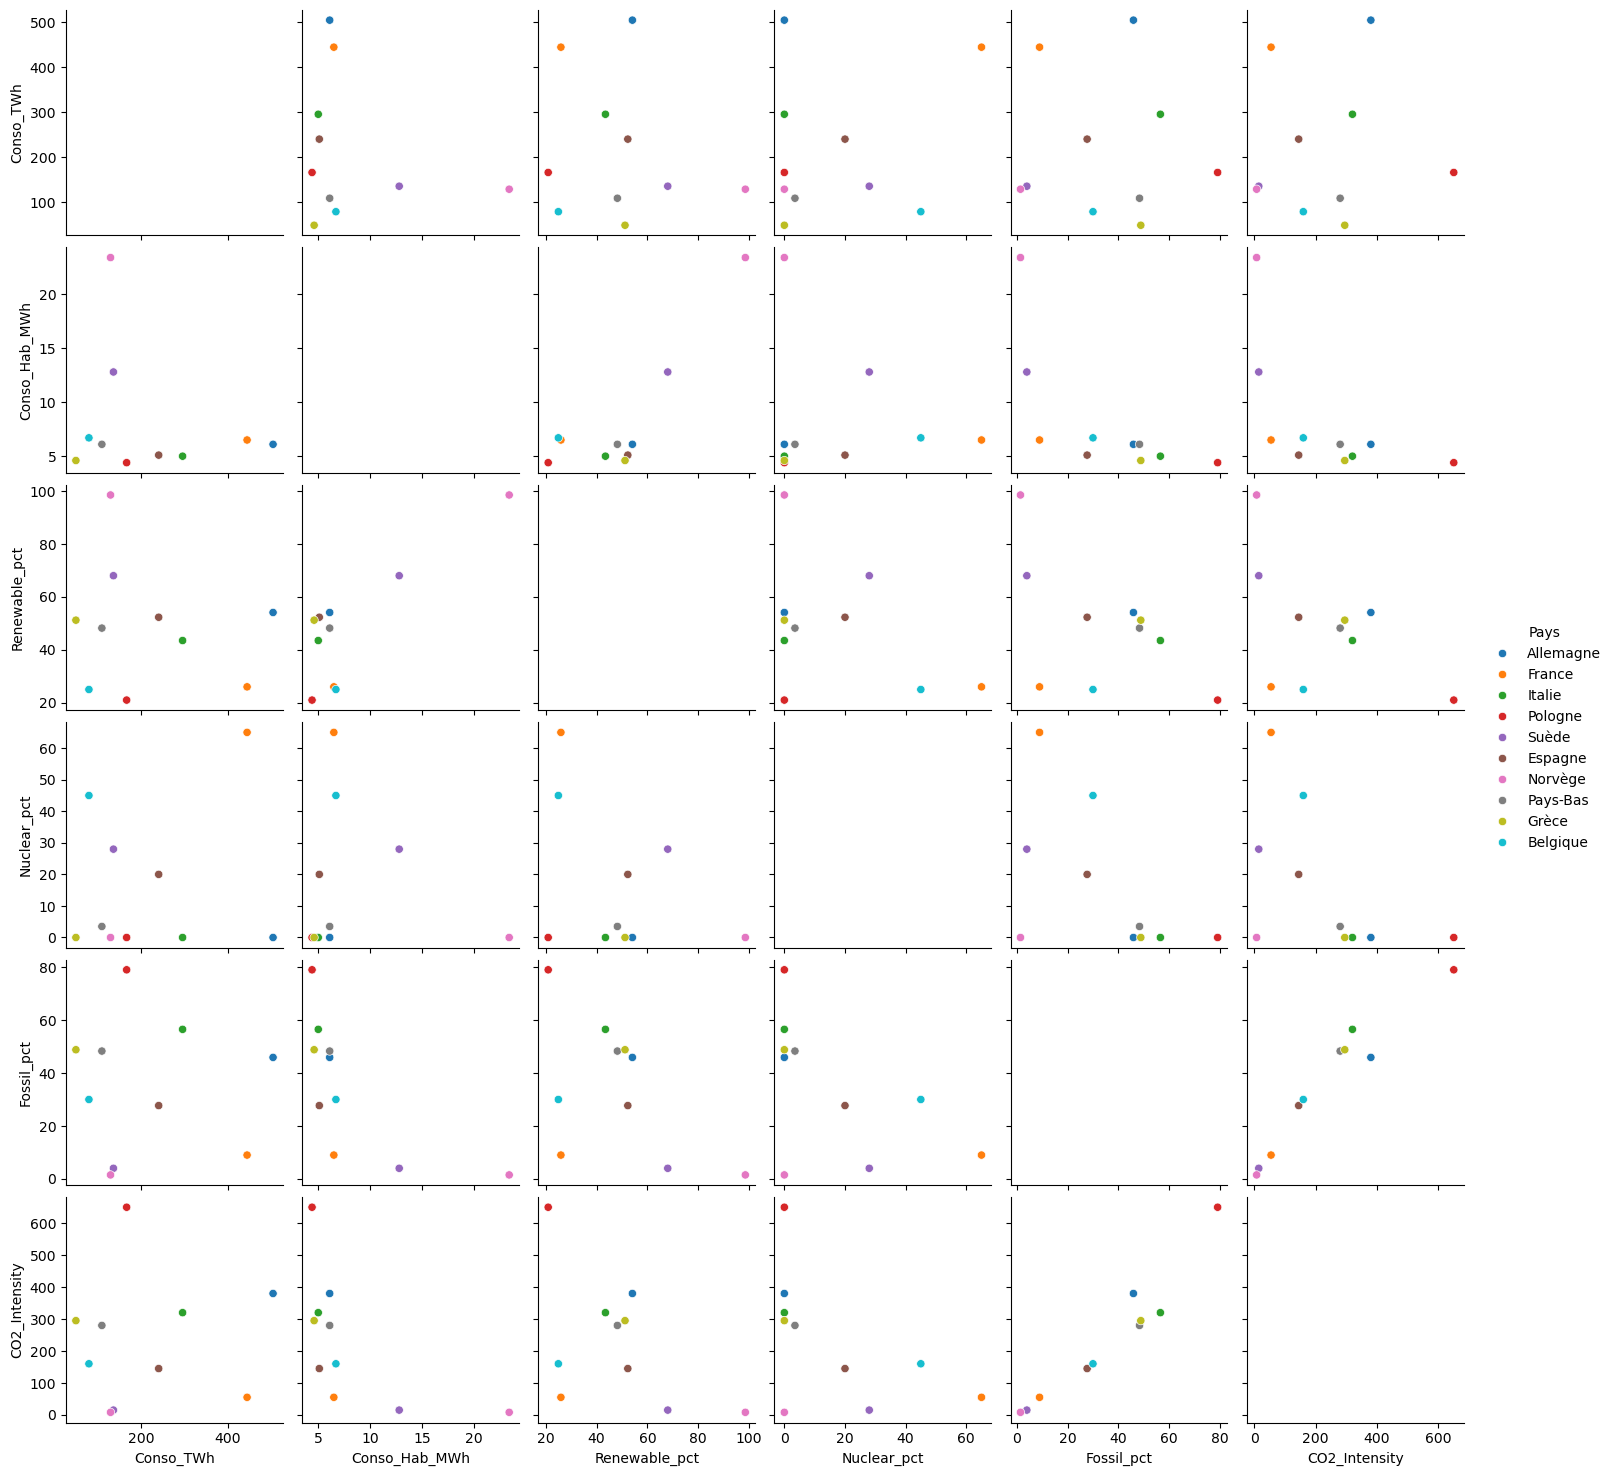

In [3]:
#Commençons par faire un pairplot. Cette représentation permet de 
#faire une analyse rapide et synthétique des corrélations deux à 
#deux des différentes variables. 

import seaborn as sns

sns.pairplot(data.reset_index(),hue="Pays")

On peut se rendre compte que des petits ilôts ont tendance à se former, notamment entre Pays-Bas, Allemagne et Grèce. Remarquons aussi une corrélation linéaire forte entre l'utilisation des énergies fossiles et l'intensité de CO2 rejetée dans l'atmosphère. Néanmoins, ce genre de graphique reste très dur à analyser et demande une forte expertise et compréhension des choses à l'oeuvre dans l'étude. C'est pour cela que PCA a été créé, pour nous simplifier la vie et résumer les corrélations sur un plan en 2D, voire 3D. 

# 1 - L'inertie

Commençons par l'élément central et majeur de l'algorithme, le calcul de l'inertie. 

La distance entre deux lignes (dans notre cas des pays) se calcule comme ceci: $ \ d(i_1,i_2 ) = \sqrt{\sum_{ k = 1}^{n}{( x_{i_1,k} - x_{i_2,k} )^2}} $. Vous remarquerez que c'est simplement la formule d'une distance euclidienne dans $\mathbb{R}$.

In [4]:
def euclidean_distance(x: np.ndarray,y: np.ndarray):
    return np.sqrt(np.sum(np.power(x - y,2)))

# Un exemple de distance euclidienne entre la France et l'Allemagne.
print("Distance entre France et Allemagne: ", euclidean_distance(data.loc["France"],data.loc["Allemagne"]))

#Un exemple de distance euclidienne entre la France et la Suède.
print("Distance entre France et Suède: ", euclidean_distance(data.loc["France"],data.loc["Suède"]))

Distance entre France et Allemagne:  340.0373802981078
Distance entre France et Suède:  317.44878327062463


A en regarder les résultats obtenus, il semblerait que la France soit plus proche en termes de profil énergétique de la Suède que de l'Allemagne. Seulement, nous avons ici un problème d'échelle. Vous remarquerez que d'une part, nous comparons des MWh avec des TWh. Nous comparons aussi des TWh avec une intensité des émissions de gaz à effet de serre. En bref, cela amène des problèmes d'échelle et donc de dispersion des données. De surcroît, nous pouvons aussi avoir des potentiels problèmes de nombres qui peuvent croître exponentiellement dans nos données et donc tirer dans le futur les axes et la variance vers eux.

Pour pallier à cela, nous pouvons utiliser la distance euclidienne pondérée: $d(i_1,i_2)  = \sqrt{ \sum_{j = 1}^{n}{\frac{( x_{i_1,j} - x_{i_2,j} )^2}{\sigma_j^2} }}   $, avec $ \sigma^2_j$ la variance baisée : $ \sigma_j^2 = \frac{1}{n} \sum_{k=1}^{n}{( x_{k,j} - \overline{ x_j } )^2}$ et  $ \overline{x_j} $ la moyenne $ \overline{ x_j } = \frac{1}{n} \sum_{k=1}^{n}{x_{k,j}}$.

In [5]:
def euclidean_distance(data, x:np.ndarray,y:np.ndarray, weighted = False) :
    if weighted ==  True:
        variances = np.var(data,axis=0, ddof=0)  # axis = 0 représente les colonnnes, ddof = 0 représentela variance baisée.
        return np.sqrt(np.sum(np.power(x - y,2) / variances)) 
    else:
       return np.sqrt(np.sum(np.power(x - y,2))) 
        
#Recalculons les mêmes distances pour France et Allemagne
print("Distance France et Allemagne: ", euclidean_distance(weighted=True, data = data, x = data.loc["France"], y = data.loc["Allemagne"]))

#Recalculons les mêmes distances pour France et Suède
print("Distance France et Suède: ", euclidean_distance(weighted=True, data = data, x = data.loc["France"], y = data.loc["Suède"]))

Distance France et Allemagne:  3.9923779010214497
Distance France et Suède:  3.503970815133941


Dans ce cas, nous voyons que la distance entre France et Allemagne est toujours plus grande que France et Suède. Notez que des fois, les résultats peuvent varier. En pratique, nous utiliserons cette distance euclidienne standardisée par les écarts types pour l'agorithme ACP. C'est ce qu'on appelle l'ACP normée. 

$\underline{NB: }$ Notez que si nos points sont déjà à la même échelle, une ACP normée n'est pas requise.

Pour la suite, nous allons utiliser la version pondérée.

L'inertie est une généralisation du concept de variance appliquée à la multidimensionalité des données. Au lieu de comparer les données d'une variable à la moyenne de cette colonne, nous allons considérer le barycentre G composé des moyennes de toutes les colonnes à la fois. Cela permet donc de capturer la totalité de la dispersion du nuage de point autour de ce barycentre global.  La moyenne et la variance mesurent donc la dispersion locale le long d'un axe déterminé. 

__La formule est donc:__

$ I_p = \sum_{k=1}^{n}{ d^2(k,G) }$, en supposant qu'on ait p colonnes et n lignes dans notre jeu de données. 

Remarquez que:
$$I_p =  \frac{1}{n} \sum_{k=1}^{n} d^2(k, G) = \frac{1}{n} \sum_{k=1}^{n} \sum_{j=1}^{p} (x_{k,j} - \bar{x}_j)^2 = \sum_{j=1}^{p} \left[ \frac{1}{n} \sum_{k=1}^{n} (x_{k,j} - \bar{x}_j)^2 \right] = \sum_{j=1}^{p} \text{Var}(X_j)$$
Ce dernier résultat sera fondamental lorsqu'on va analyser les valeurs propres de la matrice de covariance (dont la trace vérifie effectivement la formule émise plus haut).

Remarquez dors et déjà que si vous centrez, puis réduisez vos données, l'inertie sera donc égale à p, le nombre de colonnes. De même, si vous centrez, puis réduisez vos données, le barycentre deviendra le vecteur nul et la distance euclidienne sera équivalente à la distance euclidienne pondérée. 

__Une autre manière de voir l'inertie est celle-ci:__

$$I_p = \frac{1}{2n^2} \sum_{i_1} \sum_{i_2} d^2(i_1, i_2)$$

Cette formule est un peu plus difficile à retenir, mais elle signifie qu'on peut aussi voir l'inertie comme la moyenne des carrés des distances entre chaque observations prises deux à deux. 

# Démonstration : Équivalence des définitions de l'Inertie

L'objectif est de démontrer que l'inertie par rapport au barycentre $G$ (mesure de dispersion centrale) est strictement équivalente à l'inertie calculée à partir des distances mutuelles entre tous les individus (mesure de dispersion relationnelle).

### 1. Les deux définitions
Nous voulons montrer l'égalité entre :
1. **L'inertie par rapport au centre :** $I_p = \frac{1}{n} \sum_{i=1}^{n} d^2(i, G)$
2. **L'inertie par rapport aux distances mutuelles :** $I_p = \frac{1}{2n^2} \sum_{i_1=1}^{n} \sum_{i_2=1}^{n} d^2(i_1, i_2)$

### 2. Application du théorème d'Al-Kashi
Pour n'importe quel couple de points $(i_1, i_2)$, nous considérons le triangle formé avec le barycentre $G$. En utilisant le théorème d'Al-Kashi (Pythagore généralisé), le carré de la distance entre deux points s'écrit :

$$d^2(i_1, i_2) = \|\vec{GM_{i_2}} - \vec{GM_{i_1}}\|^2$$
$$d^2(i_1, i_2) = d^2(i_1, G) + d^2(i_2, G) - 2 \vec{GM_{i_1}} \cdot \vec{GM_{i_2}}$$

### 3. Sommation sur l'ensemble du nuage
Appliquons la double somme $\sum_{i_1=1}^n \sum_{i_2=1}^n$ à l'ensemble des termes :

$$\sum_{i_1=1}^n \sum_{i_2=1}^n d^2(i_1, i_2) = \sum_{i_1=1}^n \sum_{i_2=1}^n d^2(i_1, G) + \sum_{i_1=1}^n \sum_{i_2=1}^n d^2(i_2, G) - 2 \sum_{i_1=1}^n \sum_{i_2=1}^n \vec{GM_{i_1}} \cdot \vec{GM_{i_2}}$$

### 4. Simplification des termes
* **Distances au centre :** Puisque $d^2(i_1, G)$ ne dépend pas de $i_2$, on le somme $n$ fois. Le raisonnement est identique pour $i_2$ :
  $$\sum \sum d^2(i_1, G) + \sum \sum d^2(i_2, G) = 2n \sum_{i=1}^n d^2(i, G)$$

* **Produit scalaire :** Par linéarité, la double somme se factorise :
  $$2 \left( \sum_{i_1=1}^n \vec{GM_{i_1}} \right) \cdot \left( \sum_{i_2=1}^n \vec{GM_{i_2}} \right)$$
  Par définition du barycentre $G$, la somme vectorielle des écarts est nulle ($\sum \vec{GM_i} = \vec{0}$), donc ce terme s'annule.

### 5. Conclusion
L'égalité devient :
$$\sum_{i_1=1}^n \sum_{i_2=1}^n d^2(i_1, i_2) = 2n \sum_{i=1}^n d^2(i, G)$$

En multipliant par $\frac{1}{2n^2}$, on retrouve la définition initiale :
$$\frac{1}{2n^2} \sum_{i_1=1}^n \sum_{i_2=1}^n d^2(i_1, i_2) = \frac{1}{n} \sum_{i=1}^n d^2(i, G) = I_p$$

Si vous ne retenez pas la démonstration, ce n'est pas primordial. Retenez simplement l'égalité des définitions. 

In [6]:
#Récoltons les variances

sigmas = np.var(data, axis = 0, ddof = 0)

#Calculons les distances carrés entre chaque points. 
Ip_v1 = 0
n,p = data.shape

for i in range(n):
    for j in range(n):
        Ip_v1 += np.sum( np.power(data.iloc[i, : ] - data.iloc[j, : ] , 2) )
Ip_v1 = Ip_v1/(2*n**2)

print("Inertie totale: ",Ip_v1)
print("Somme des variances: ", np.sum(sigmas))

Inertie totale:  58596.57240000001
Somme des variances:  58596.57240000001


Comme vous le voyez, les résultats sont égaux. Attention, des fois vous pouvez avoir des résultats un peu différent à cause des arrondis faits par Python. Essayons maintenant la seconde méthode :

In [7]:
#Récoltons le barycentre.

G = np.mean(data, axis=0)
Ip_v2 = 0
for i in range(n):
    Ip_v2 += np.sum( np.power( data.iloc[i, : ] - G, 2))
Ip_v2 /= n

print("Inertie totale: ",Ip_v2)
print("Somme des variances: ", np.sum(sigmas))

Inertie totale:  58596.572400000005
Somme des variances:  58596.57240000001


Ici, on retrouve le problème que je vous avais confié. Les erreurs d'approximation amène Python à avoir des résultats non totalement exactes. Les lignes de codes suivantes le prouvent aussi : 

In [8]:
np.allclose(Ip_v2, np.sum(sigmas)), Ip_v2 == np.sum(sigmas)

(True, np.False_)

# La matrice de covariance

La matrice de covariance entre n variables quantitatives lignes et p variables qualitatives colonnes s'écrit comme ceci: 

Chaque élément $c_{j,k}$ situé à la ligne $j$ et à la colonne $k$ de la matrice correspond à la covariance entre la variable $X_j$ et la variable $X_k$ :$$c_{j,k} = \text{Cov}(X_j, X_k) = \frac{1}{n} \sum_{i=1}^{n} (x_{i,j} - \bar{x}_j)(x_{i,k} - \bar{x}_k)$$

Elle ressemble alors à :

$$\Sigma = \begin{pmatrix} 
\text{var}(X_1) & \text{cov}(X_1, X_2) & \text{cov}(X_1, X_3) & \cdots & \text{cov}(X_1, X_p) \\
\text{cov}(X_2, X_1) & \text{var}(X_2) & \text{cov}(X_2, X_3) & \cdots & \text{cov}(X_2, X_p) \\
\text{cov}(X_3, X_1) & \text{cov}(X_3, X_2) & \text{var}(X_3) & \cdots & \text{cov}(X_3, X_p) \\
\vdots & \vdots & \vdots & \ddots & \vdots \\
\text{cov}(X_p, X_1) & \text{cov}(X_p, X_2) & \text{cov}(X_p, X_3) & \cdots & \text{var}(X_p)
\end{pmatrix}$$

Remarquez que $Tr(\Sigma) = I_p$, et surtout que $\Sigma$ est symétrique. $\Sigma$ est alors diagonalisable et ne dispose que de valeurs propres réelles. L'invariance par changement de base de la trace nous assure que la somme des valeurs propres de cette matrice nous redonnera l'inertie totale. 

In [9]:
#Récupérons la matrice de covariance.

cov_matrix = np.cov(data,rowvar = False,ddof=0) #rowvar permet de dire que nous nous intéressons à la variance des variables colonnes et non des lignes? 

display(cov_matrix)
cov_matrix.shape, data.shape

array([[ 2.18342581e+04, -1.80147100e+02, -5.59346400e+02,
         6.69265500e+02, -1.09919100e+02,  1.74772600e+03],
       [-1.80147100e+02,  3.13241000e+01,  1.01143400e+02,
        -9.75550000e+00, -9.13879000e+01, -6.23436000e+02],
       [-5.59346400e+02,  1.01143400e+02,  4.77239600e+02,
        -1.94427000e+02, -2.82812600e+02, -2.10347400e+03],
       [ 6.69265500e+02, -9.75550000e+00, -1.94427000e+02,
         4.83802500e+02, -2.89375500e+02, -2.21992000e+03],
       [-1.09919100e+02, -9.13879000e+01, -2.82812600e+02,
        -2.89375500e+02,  5.72188100e+02,  4.32339400e+03],
       [ 1.74772600e+03, -6.23436000e+02, -2.10347400e+03,
        -2.21992000e+03,  4.32339400e+03,  3.51977600e+04]])

((6, 6), (10, 6))

Intéressons-nous à une propriété fondamentale de la matrice de covariance et de son lien avec notre jeu de données brut (que l'on notera $\mathcal{D}$).

# Lien entre la matrice de données $D$ et la matrice de covariance $\Sigma$

Soit $D$ notre matrice de données brute de dimensions $(n, p)$, où $n$ est le nombre de pays et $p$ le nombre de variables énergétiques.

### 1. Propriété fondamentale : La forme quadratique
Le lien mathématique direct entre les données et la structure de dispersion s'exprime par le produit matriciel de la matrice centrée par sa transposée :

$$\Sigma = \frac{1}{n} X^\top X$$

Où $X$ représente les données après traitement (centrage ou standardisation).

---

### 2. Cas n°1 : Sans standardisation (ACP sur covariance)
Si nous appliquons uniquement un **centrage** sur les données brutes ($X = D - \bar{D}$), la matrice obtenue est la **matrice de covariance**.

* **Lien explicite :** Chaque élément $\sigma_{jk}$ est le produit scalaire des colonnes de données centrées :
    $$\sigma_{jk} = \frac{1}{n} \sum_{i=1}^{n} (d_{i,j} - \bar{d}_j)(d_{i,k} - \bar{d}_k)$$
* **Sur la diagonale :** On retrouve les variances brutes $\text{var}(D_j)$.
* **Inertie Totale :** $I_{tot} = \text{Tr}(\Sigma) = \sum \text{var}(D_j)$.
* **Conséquence :** Si une variable a des valeurs numériquement très grandes (ex: Consommation en TWh), sa variance écrasera les autres. C'est ce qui explique une inertie totale élevée (ex: **50 000**).

---

### 3. Cas n°2 : Avec standardisation (ACP sur corrélation)
Si nous **standardisons** les données ($X = Z$), chaque valeur est centrée et divisée par son écart-type : $z_{i,j} = \frac{d_{i,j} - \bar{d}_j}{s_j}$. La matrice $\Sigma$ devient alors la **matrice de corrélation** $R$.

* **Lien explicite :** La corrélation est une covariance normalisée par le produit des écarts-types :
    $$r_{jk} = \frac{\text{cov}(D_j, D_k)}{s_j \cdot s_k}$$
* **Sur la diagonale :** On ne retrouve que des **1**, car chaque variable a été réduite à une variance unité :
    $$\text{var}(Z_j) = \frac{\text{var}(D_j)}{s_j^2} = 1$$
* **Inertie Totale :** $I_{tot} = \text{Tr}(R) = p$ (le nombre de variables).
* **Conséquence :** L'inertie totale est exactement égale au nombre de colonnes (ex: **6**). Chaque
# Démonstration : Pourquoi le centrage est-il nécessaire ? (Théorème de Huygens)

Soit un échantillon de $n$ observations $d_1, d_2, \dots, d_n$ pour une variable donnée $D$. On note $\bar{d}$ la moyenne empirique de ces observations.

### 1. Définition de l'Inertie par rapport à l'origine
Si nous calculons l'inertie $I_O$ du nuage de points sans centrer les données (par rapport à l'origine $0$), nous calculons la moyenne du carré des valeurs :
$$I_O = \frac{1}{n} \sum_{i=1}^{n} d_i^2$$

### 2. Décomposition de la somme
Pour faire apparaître la dispersion autour de la moyenne (la variance), nous introduisons artificiellement $\bar{d}$ dans l'expression :
$$I_O = \frac{1}{n} \sum_{i=1}^{n} (d_i - \bar{d} + \bar{d})^2$$

En développant l'identité remarquable $(a+b)^2$ avec $a = (d_i - \bar{d})$ et $b = \bar{d}$, nous obtenons :
$$I_O = \frac{1}{n} \sum_{i=1}^{n} \left[ (d_i - \bar{d})^2 + 2\bar{d}(d_i - \bar{d}) + \bar{d}^2 \right]$$

### 3. Séparation des termes par linéarité
Grâce aux propriétés de la sommation, nous pouvons séparer l'expression en trois parties distinctes :
$$I_O = \frac{1}{n} \sum_{i=1}^{n} (d_i - \bar{d})^2 + \frac{2\bar{d}}{n} \sum_{i=1}^{n} (d_i - \bar{d}) + \frac{1}{n} \sum_{i=1}^{n} \bar{d}^2$$

### 4. Simplification des termes
Analysons chaque composante :
1. **Le premier terme** est, par définition, la **variance** de la variable $D$ :
   $$\text{Var}(D) = \frac{1}{n} \sum_{i=1}^{n} (d_i - \bar{d})^2$$
2. **Le deuxième terme** s'annule obligatoirement. En effet, la somme des écarts à la moyenne est toujours nulle :
   $$\sum_{i=1}^{n} (d_i - \bar{d}) = \sum d_i - n\bar{d} = n\bar{d} - n\bar{d} = 0$$
3. **Le troisième terme** se simplifie car $\bar{d}^2$ est une constante par rapport à l'indice $i$ :
   $$\frac{1}{n} \sum_{i=1}^{n} \bar{d}^2 = \frac{n \cdot \bar{d}^2}{n} = \bar{d}^2$$

### 5. Conclusion : La formule de Huygens
Le lien entre l'inertie brute et la variance est donc :
$$I_O = \text{Var}(D) + \bar{d}^2$$



---

### Conséquence pour l'ACP
Pour que l'Analyse en Composantes Principales (ACP) étudie uniquement la **dispersion** des données (les différences entre les pays) et non leur distance par rapport à l'origine $0$, il est impératif de **centrer** les données. 

En posant $X = D - \bar{d}$, la nouvelle moyenne devient $0$, ce qui annule le terme $\bar{d}^2$. L'inertie totale devient alors strictement égale à la somme des variances :
$$I_{centrée} = \sum \text{Var}(D_j)$$

In [10]:
#Recréons la matrice de covariance.

G = np.mean(data, axis = 0)

X = data - G

cov_matrix_v2 = X.T @ X / (n)
np.allclose(cov_matrix_v2,cov_matrix),np.all(cov_matrix_v2 == cov_matrix)

(True, np.False_)

Si vous voulez utiliser les variances et covariances débiaisées, ce qui est le calcul fait de base par pandas et numpy, vous devez diviser par (n-1) à la place de n. Il est d'ailleurs conseillé de débiaiser vos calculs puisqu'ils seront plus précis. Pour simplifier les calculs, je ne le ferai pas dans ce cours. Normalement, les packages préfaits que vous utiliserez et qui font l'ACP débiaiserons pour vous les calculs. Retenez que vous devez donc au minimum centrer vos données pour que le barycentre devienne l'origine du repère. 

In [11]:
#Voici ce qui se passe sans centrage

cov_matrix_v3 = data.T @ data / (n)
np.allclose(cov_matrix_v3,cov_matrix),np.all(cov_matrix_v2 == cov_matrix)

(False, np.False_)

Même le allclose de numpy prouve que ce n'est pas une question de problème d'arrondis. C'est à cause de la formule de Huygens. Regardez aussi que la trace de la matrice de covariance est bien équivalente à l'inertie totale:

In [12]:
#Inertie de la matrice de covariance v1

trace_v1 = np.trace(cov_matrix)
trace_v2 = np.trace(cov_matrix_v2)
trace_v3 = np.trace(cov_matrix_v3)

print(trace_v1,trace_v2,trace_v3,Ip_v1)

58596.572400000005 58596.57240000001 162038.45399999997 58596.57240000001


Il est encore une fois claire que si nous centrons pas nos données, nous avons une trace bien plus grande. Tentons finalement de centrer ET réduire nos données.

In [13]:
Z = X/np.sqrt(sigmas)

cov_matrix_reduced = np.cov(Z, rowvar=False, ddof=0)
cov_matrix_reduced_v2 = Z.T @ Z / n

trace_reduced_v1 = np.trace(cov_matrix_reduced)
trace_reduced_v2 = np.trace(cov_matrix_reduced_v2)

print(trace_reduced_v1,trace_reduced_v2,p)

6.0 6.0 6


En réalité, la matrice Z est une matrice qui a un nom assez spécial: c'est la matrice des corrélations linéaires de Pearson. 

# La Matrice des Corrélations Linéaires

## 1. Définition et Concept
La matrice des corrélations (notée souvent $R$) est un tableau carré de dimension $(p \times p)$ qui synthétise les relations linéaires entre $p$ variables. Chaque élément $r_{ij}$ de la matrice correspond au **coefficient de corrélation de Pearson** entre la variable $i$ et la variable $j$.

Le coefficient est calculé comme suit :
$$r_{ij} = \frac{\text{Cov}(X_i, X_j)}{\sigma_{i} \sigma_{j}}$$

* **L'objectif :** Mesurer la force et le sens de la liaison linéaire entre deux variables, indépendamment de leurs unités (le coefficient est sans unité).



---

## 2. Propriétés Mathématiques
Une matrice de corrélation possède des propriétés structurelles uniques :

* **Diagonale unité :** La diagonale principale est toujours composée de **1**, car une variable est toujours parfaitement corrélée avec elle-même ($r_{ii} = 1$).
* **Symétrie :** La matrice est symétrique ($r_{ij} = r_{ji}$). La relation entre $X$ et $Y$ est identique à celle entre $Y$ et $X$.
* **Bornes :** Tout coefficient $r$ est compris dans l'intervalle **[-1, 1]**.
    * **1** : Corrélation positive parfaite (les variables évoluent ensemble).
    * **-1** : Corrélation négative parfaite (elles évoluent en sens inverse).
    * **0** : Absence de relation linéaire.
* **Semi-définie positive :** Toutes ses valeurs propres sont $\lambda \ge 0$. La somme de ces valeurs propres est égale au nombre de variables $p$.

---

## 3. Lien avec l'ACP (Analyse en Composantes Principales)
Dans une **ACP normée**, la matrice des corrélations est l'objet central de l'étude. 

> **Point clé :** Faire une ACP sur la matrice des corrélations revient exactement à faire une ACP sur la matrice de covariance de vos données **centrées et réduites**. 

C'est cette étape de réduction (division par l'écart-type) qui transforme la covariance en corrélation et permet de traiter sur un pied d'égalité des variables aux unités différentes (ex: des TWh et des pourcentages).



---

## 4. Interprétation des Résultats
L'examen de cette matrice permet deux diagnostics rapides :

1.  **Redondance :** Si des coefficients sont très élevés (ex: $|r| > 0.95$), l'une des deux variables n'apporte presque aucune information nouvelle. C'est ce qui réduit le **rang** de la matrice.
2.  **Structure des données :** Des blocs de fortes corrélations suggèrent que ces variables "vont ensemble" et formeront probablement une composante principale unique (un axe).

---

## 5. Visualisation et Implémentation (Python)
La méthode la plus efficace pour interpréter cette matrice est la **Heatmap** (carte de chaleur).



True


/var/folders/6g/63k1jcx515d55m6v2ybt5k200000gn/T/ipykernel_4525/588345656.py:3: DeprecationWarning: bias and ddof have no effect and are deprecated
  cov_matrix_reduced_v3 = np.corrcoef(data,rowvar=False, ddof=0) #Je fais exprès de vous montrer que ddof ne sert à rien puisque le fait d'être biaisé n'aura AUCUN IMPACT.


<Axes: >

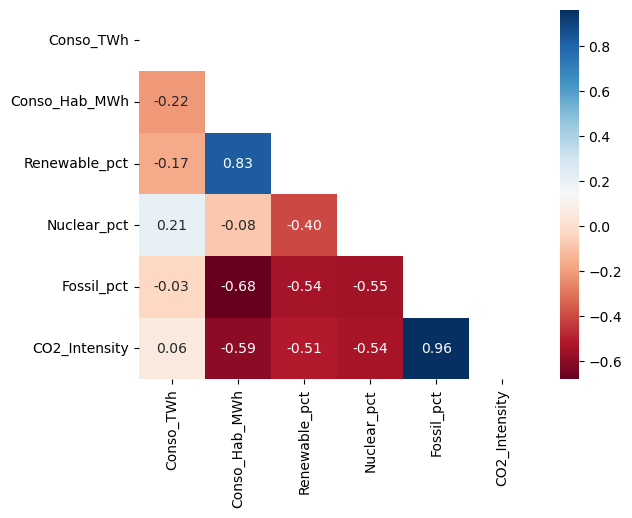

In [14]:
#Création de la matrice des corrélations linéaires de Pearson

cov_matrix_reduced_v3 = np.corrcoef(data,rowvar=False, ddof=0) #Je fais exprès de vous montrer que ddof ne sert à rien puisque le fait d'être biaisé n'aura AUCUN IMPACT.
print(np.allclose(cov_matrix_reduced_v2,cov_matrix_reduced_v3))

sns.heatmap(cov_matrix_reduced_v3,cmap="RdBu",annot=True,fmt=".2f",xticklabels=data.columns, yticklabels=data.columns,mask=np.triu(cov_matrix_reduced_v3))

Je pense que vous comprenez que j'adoreles belles heatmap. J'adore donc ces graphiques qui nous montrent que nos données sont plutôt corrélées linéairement. Notez que pour améliorer ce graphique, j'ai imposé un masque booléen qui permet de ne pas afficher les doublons etla diagonale superflue (une variable est forcément corrélée à elle-même.)

Bon, l'ACP a pour but de diagonaliser cette matrice de covariance normalisée, ou encore appelée matrice des corrélations de Pearson. Faisons cela via Numpy:

In [15]:
eig_vals, eig_vecs = np.linalg.eigh(cov_matrix_reduced) #np.eigh est optimisée pour les matrices symétriques. :)

print(np.sum(eig_vals))

5.999999999999998


La somme des valeurs propres ne vous rappelle rien, à l'arrondi près ? Oui, c'est l'inertie. C'est la propriété de l'invariance de la trace d'une matrice dont je vous parlais plus tôt. 

In [16]:
eig_vals_sorted = eig_vals[np.argsort(eig_vals)[::-1]]
print(eig_vals_sorted, np.linalg.matrix_rank(cov_matrix_reduced))

[ 3.13662345e+00  1.75779841e+00  8.81653986e-01  2.04777562e-01
  1.91465856e-02 -5.46879530e-17] 5


Notez que le rang d'une matrice de covariance n'est pas toujours inférieur ou égale à p-1 où p est le nombre de variables en colonnes dans votre jeu de données.Si c'est le cas, cela signifie que vous aurez au plus 5 valeurs propres non nulles. La 6ème est forcément nulle, ou alors si elle ne l'est pas, cela est entièrement causé par des problèmes d'arrondis. Dans notre cas, la dernière valeur propre est de l'ordre de $ 10^{-17}$, ce qui prouve ces dire vu que le rang de la matrice est 5. La dernière composante principale est donc à ne pas considérer si on souhaite faire une analyse en composantes principales. 

Comme chacune des valeurs propres correspond à une partie d'inertie expliquée, nous pouvons donc calculer un pourcentage comme ceci:

Text(0, 0.5, "Pourcentage d'inertie (%)")

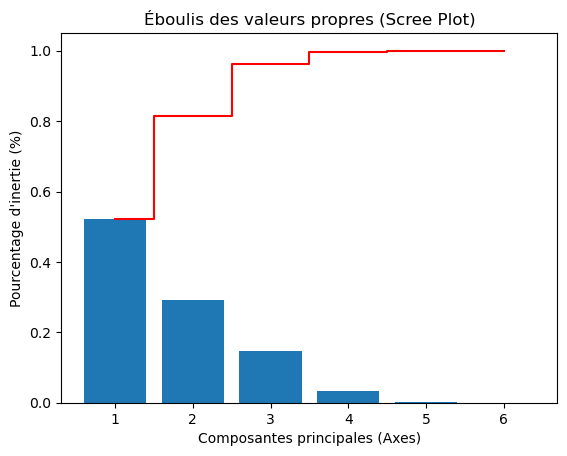

In [17]:
pourcentage_inertie_expliquée = eig_vals[np.argsort(eig_vals)[::-1]] / np.sum(eig_vals)
x_axis = range(1, len(pourcentage_inertie_expliquée) + 1)
plt.bar(x_axis, pourcentage_inertie_expliquée)
# Optionnel : On ajoute une ligne pour le cumul (très utile en ACP)
plt.step(x_axis, np.cumsum(pourcentage_inertie_expliquée), where='mid', color='red', label="Inertie cumulée")
plt.title("Éboulis des valeurs propres (Scree Plot)")
plt.xlabel("Composantes principales (Axes)")
plt.ylabel("Pourcentage d'inertie (%)")

Un graphique comme celui-ci est très intéressant. Il nous permet de visualiser rapidement quelles composantes sont les plus importantes. Ici, on se rend vite compte que si nous ne récupérons que les 3 premières composantes principales, nous avons une inertie reconstruite de l'ordre des 95%, ce qui est incroyable. Un graphique en 3D permet d'autre part de faire des analyses graphiques en 3 dimensions grâce à matplotlib. Néanmoins, ne garder que les deux premières composantes principales est aussi très utile puisque ce sont ces deux composantes récupèrent à eux deux plus de 80% de l'inertie totale. 

Il existe différentes techniques permettant de déterminer le nombre d'axes à considérer si nous souhaitons installer PCA dans une pipeline scikit-learn future. J'en décompte 5. 

Le premier critère est le plus simple: voulez-vous analyser visuellement vos données ? Si oui, vous n'aurez pas le choix, vous devrez choisir au maximum trois axes et au minimum 2 axes. 

Le second critère s'apelle la méthode du coude. Le but est de déterminer la valeur propre à partir de laquelle le gain d'inertie devient drastiquement plus bas. Sur le graphique, cela doit former une sorte de "coude" (elbow en anglais).

Nous pouvons utiliser cette méthode comme ceci:

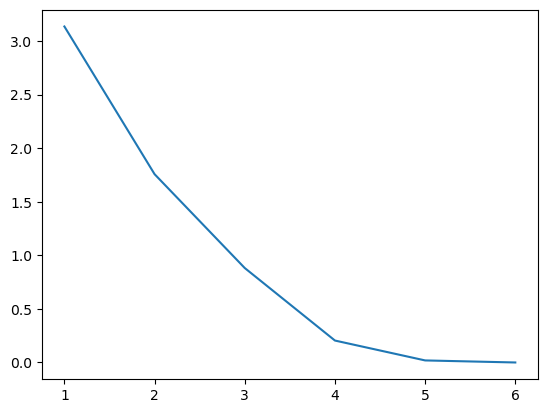

In [18]:
plt.plot(x_axis,eig_vals_sorted)

Parfois, le coude n'est pas très visible, ici, il est vrai que nous avons du mal à identifier le seuil optimal. Selon moi, il est entre 2 et 3. 

Une autre méthode utile est la méthode de Kaiser, elle a pour but de sélectionner toutes les valeurs propres qui sont supérieures à la valeur propre moyenne. 

Remarquons que comme $Tr(\Sigma) = Tr(Diag((\lambda_1,...,\lambda_p))$, on remarquera donc que la somme des valeurs propres est égale à la somme des variances. Dans le cas où nos variables sont réduites, toutes les variances sont égales à 1. et vous devez sûrement savoir que:
$\frac{1}{n}\sum_{k=1}^{n}{1} = \frac{n}{n} = 1,$  donc $\bar{\lambda} = 1$.

La règle de Kaiser la plupart du temps en ACP (vu qu'on la fera normée) sera donc de récupérer les valeurs propres qui sont supérieures à 1. D'après la règle de Kaiser, le nombre optimal de valeur propre est donc: $$$$

In [19]:
eig_vals_sorted > 1

array([ True,  True, False, False, False, False])

Une autre technique s'appelle la règle de Karlis-Saporta-Spinaki. Au lieu de comparer à la moyenne, vous comparez vos valeurs propres à:
$$S = \bar{\lambda} \cdot ( 1 + 2 \sqrt{\frac{p-1}{n-1}})$$


In [20]:
eig_vals_sorted > 1 + 2 * np.sqrt((p-1)/(n-1) )

array([ True, False, False, False, False, False])

Ce critère est un critère beaucoup plus demandeur et stricte que les deux derniers. Vous voyez donc qu'il ne nous propose de ne garder qu'un seul axe ! Il est d'autant plus déconseillé ici parce que nous avons des valeurs de p (6) et de n (10) très faibles.

Une avant dernière méthode consiste à faire la méthode des bâtons brisés.

# Le Modèle des Bâtons Brisés (Broken Stick Model)

## 1. Principe théorique
Le modèle des bâtons brisés est un critère de sélection des axes en ACP. Il repose sur une comparaison entre les valeurs propres observées et une distribution théorique issue d'un découpage aléatoire de l'inertie totale.

L'idée fondamentale est la suivante : si l'on brise un bâton de longueur 1 en $p$ segments de façon aléatoire, quelle est la taille espérée du $k$-ième segment le plus long ?

## 2. Formulation Mathématique
Pour un nombre de variables $p$, le seuil critique pour le $k$-ième axe (noté $b_k$) est calculé par la somme des inverses des rangs restants :

$$b_k = \frac{1}{p} \sum_{i=k}^{p} \frac{1}{i}$$

* **$\lambda_k$** : Valeur propre de l'axe $k$.
* **Règle de décision** : On conserve l'axe $k$ si et seulement si :
$$\frac{\lambda_k}{\sum \lambda} > b_k$$

*(Note : Dans une ACP normée où la somme des $\lambda = p$, cela revient à vérifier si $\lambda_k > \sum_{i=k}^{p} \frac{1}{i}$)*

## 3. Pourquoi utiliser ce modèle ?
Le modèle des bâtons brisés est souvent préféré aux autres critères pour les raisons suivantes :

1. **Moins arbitraire que Kaiser :** Kaiser retient tout ce qui est au-dessus de la moyenne ($>1$), ce qui surestime souvent l'importance des petits axes.
2. **Indépendant de l'échantillon ($n$) :** Contrairement à Karlis-Saporta, il ne devient pas "trop sévère" quand on a peu d'individus.
3. **Logique de décroissance :** Il tient compte du fait que, par construction, les valeurs propres sont ordonnées. Le seuil pour le premier axe est donc naturellement plus élevé que pour le second.

## 4. Application pour $p = 6$
Voici les seuils calculés pour un jeu de 6 variables (Inertie totale = 6) :

| Axe | Formule théorique | Seuil (Inertie) | % d'Inertie min. |
| :--- | :--- | :--- | :--- |
| **F1** | $1 + 1/2 + 1/3 + 1/4 + 1/5 + 1/6$ | **2.45** | 40.8% |
| **F2** | $1/2 + 1/3 + 1/4 + 1/5 + 1/6$ | **1.45** | 24.2% |
| **F3** | $1/3 + 1/4 + 1/5 + 1/6$ | **0.95** | 15.8% |
| **F4** | $1/4 + 1/5 + 1/6$ | **0.62** | 10.3% |



In [21]:
import numpy as np

# Calcul des seuils du bâton brisé
broken_stick_thresholds = [np.sum(1/np.arange(k, p + 1)) for k in range(1, p + 1)]

# Sélection des composantes
n_axes = np.sum(eig_vals_sorted > broken_stick_thresholds)
print(f"Nombre d'axes à retenir selon le bâton brisé : {n_axes}")

Nombre d'axes à retenir selon le bâton brisé : 2


La dernière méthode est souvent oubliée par beaucoup de personnes qui commencent dans le machine learning et qui veulent faire des choses qui paraissent compliquées. Je l'apelle la méthode du 90-95-98%. Le but de cette métode est simplement de garder un pourcentage de variance cumulative que vous voulez, généralement entre 90, 95 ou 98%. Cela est intéressant pour des datasets assez gros (avec des centaines de dimensions) dans des algorithmes de machine learning qui galèrent avec la dimensionalité (ex: le k nearest neighbear vu que l'ACP tente de garder les distances euclidiennes intactes.) Attention néanmoins, vous n'obtiendrez qu'une optimalité dans le sens où vous l'avez définie. Si votre but est de récolter un maximum de variance totale resistée, choisissez 98%.

Dans mon cas, toutes les méthodes, sauf une, me poussent à utiliser 2 axes principaux. Cela m'arrange d'autant plus que nous pourrons analyser graphiquement les résultats. C'est donc "parfait". 

Il est grand temps de récupérer les vecteurs propres ET les coordonnées des points.

In [22]:
#On récupère les vecteurs propres dans l'ordre d'importance des valeurs propres.

eig_vecs_sorted = eig_vecs[:,np.argsort(eig_vals)[::-1]]
eig_vecs_choosen = eig_vecs_sorted[:,:2]

loadings = eig_vecs_choosen
scores = Z @ loadings
display(scores)

,0,1
Pays,,
Allemagne,-0.990700,-0.087191
France,0.744684,3.116250
Italie,-1.254776,-0.358664
Pologne,-3.094630,-0.796591
Suède,2.201432,0.097792
Espagne,0.231978,0.435563
Norvège,3.571237,-1.936451
Pays-Bas,-0.653704,-0.735030
Grèce,-0.772986,-1.001825


Vous remarquerez que j'ai pris le soin de renommer les points projetés des "loadings" et les vecteurs des "scores". Ce sont en réalité les mots les plus communéments utilisés en ACP statistiques. Vous les retrouverez avec ce genre de notations dans différents packages.

# De la réduction de dimension à la récupération de la matrice de corrélation initiale. 

L'une des plus grandes forces de l'ACP, tout comme d'autres méthodes, c'est de pouvoir compresser nos données. 

In [23]:
scores@loadings.T,Z

(                  0         1         2         3         4         5
 Pays                                                                 
 Allemagne  0.042562 -0.451517 -0.378900 -0.223056  0.551144  0.535099
 France     1.077805 -0.529591 -1.084842  2.285520 -1.110845 -1.090404
 Italie    -0.036395 -0.501164 -0.368452 -0.454839  0.754733  0.733728
 Pologne   -0.057757 -1.261069 -0.948203 -1.060687  1.841295  1.789734
 Suède     -0.129484  1.030648  0.885034  0.429038 -1.202786 -1.167396
 Espagne    0.141057 -0.012528 -0.097664  0.340432 -0.223843 -0.218946
 Norvège   -0.972213  2.268731  2.376348 -0.758448 -1.472831 -1.421174
 Pays-Bas  -0.218378 -0.104946  0.054157 -0.617512  0.518359  0.505911
 Grèce     -0.306490 -0.086305  0.123604 -0.822293  0.643238  0.628154
 Belgique   0.459293 -0.352259 -0.561080  0.881845 -0.298463 -0.294707,
            Conso_TWh  Conso_Hab_MWh  Renewable_pct  Nuclear_pct  Fossil_pct  \
 Pays                                                              

Comme ceci, on ne s'en rend pas compte car cela n'a pas l'air fameux. Prenons l'exemple d'une image.

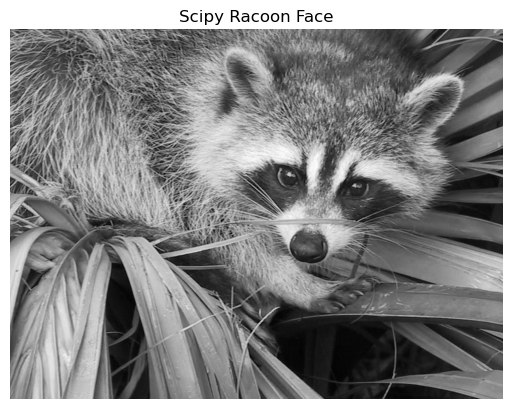

In [24]:
import scipy
from scipy import datasets

# Charger l'image (format NumPy array)
face = datasets.face(gray=True)

# Afficher l'image
plt.imshow(face,cmap="grey")
plt.title("Scipy Racoon Face")
plt.axis('off') # Pour enlever les axes x et y
plt.show()

Regardez-moi cette belle petite tête de raton tout mimi. Vous n'imaginez pas que cet afreux jojo coute cher en place sur le disque dur. 

oui, ça en fait beaucoup des données à garder en mémoire pour une simple image. Appliquons donc PCA à l'image et regardons le résultat.

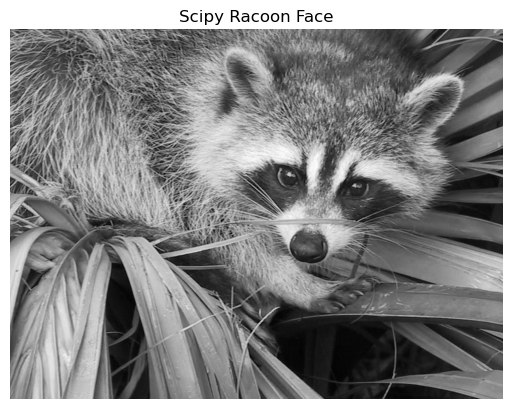

In [25]:
face_norm = face / 255.0 #Normalisation de l'image. 

plt.imshow(face_norm,cmap="grey")
plt.title("Scipy Racoon Face")
plt.axis('off') # Pour enlever les axes x et y
plt.show()

Vous remarquerez que la normalisation n'a eu aucun effet sur notre image et son affichage. APpliquons-lui maintenant PCA.

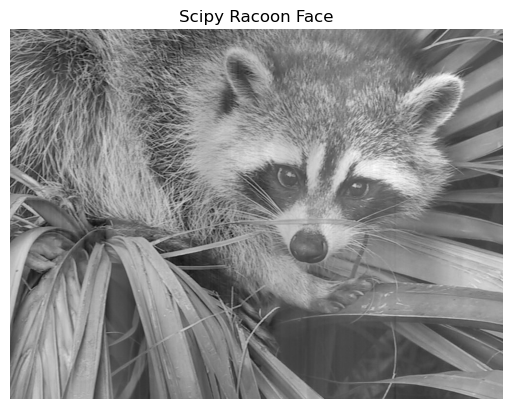

In [26]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
face_scaled = scaler.fit_transform(face_norm)

plt.imshow(face_scaled,cmap="grey")
plt.title("Scipy Racoon Face")
plt.axis('off') # Pour enlever les axes x et y
plt.show()

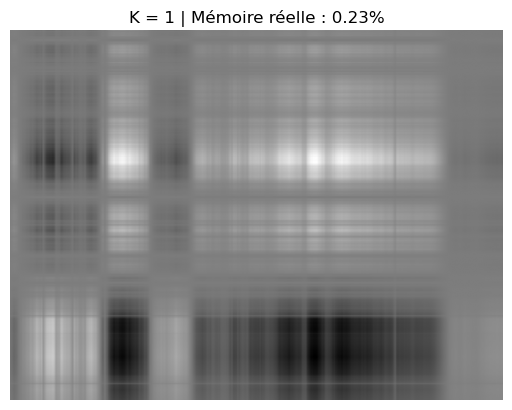

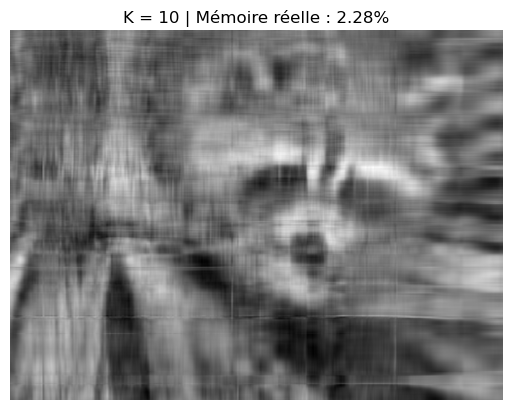

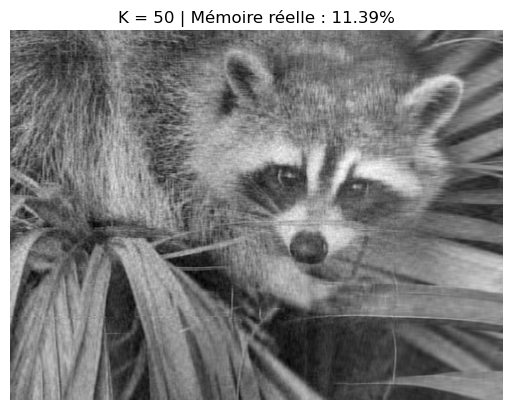

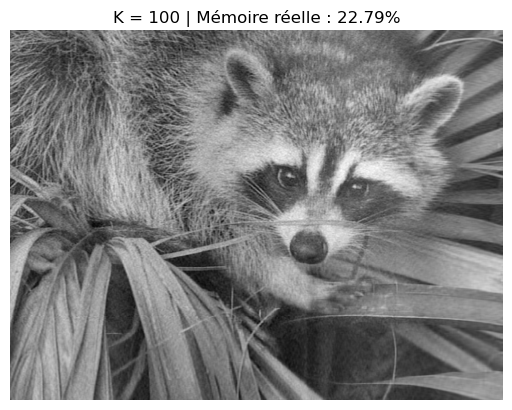

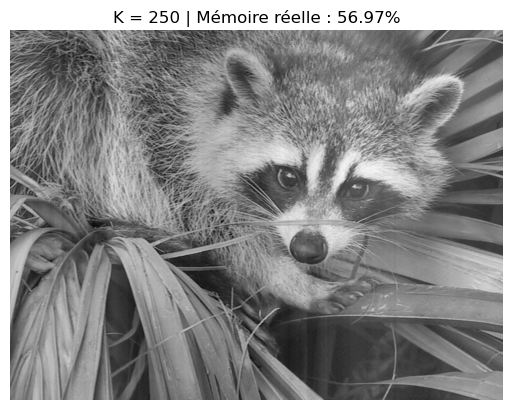

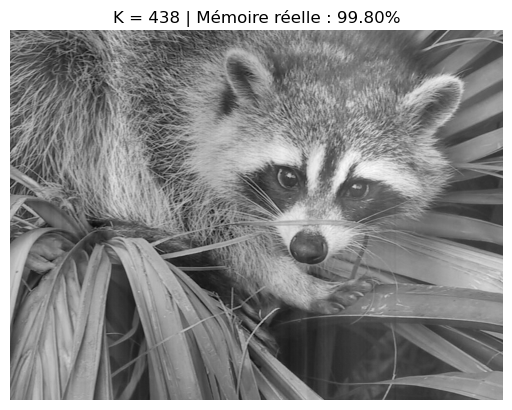

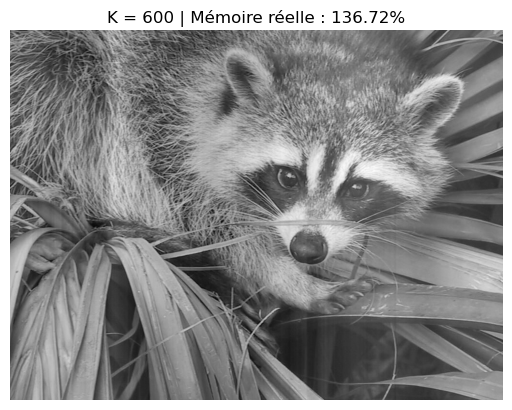

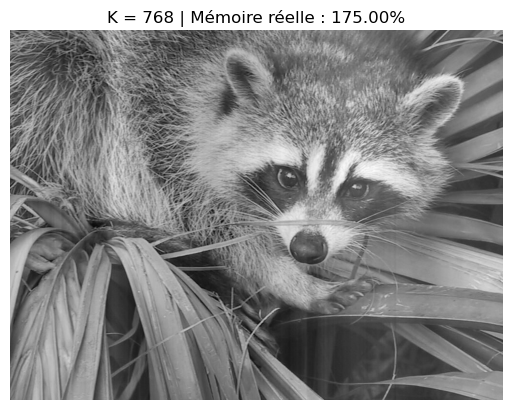

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import datasets

# 1. Charger et normaliser
face = datasets.face(gray=True)
face_norm = face / 255.0 
face_mean = face_norm.mean(axis=0)
face_norm -= face_mean #(on ne stadardise pas les données car toutes les données sont similaires (ce sont des pixels))

# 2. Calcul des valeurs/vecteurs propres sur la matrice de covariance (ou corrélation)
# On travaille sur les colonnes (1024 variables)
R = np.cov(face_norm, rowvar=False) 
eig_vals_rac, eig_vecs_rac = np.linalg.eigh(R)

# 3. Tri rigoureux
idx = np.argsort(eig_vals_rac)[::-1]
eig_vals_rac_sorted = eig_vals_rac[idx]
eig_vecs_rac_sorted = eig_vecs_rac[:, idx]

# 4. Test de reconstruction pour des valeurs de K 

N, P = face_norm.shape  # Récupère 768 et 1024

for k in [1, 10, 50, 100, 250, 438, 600, 768]:
    
    # 1. Sélection des k colonnes
    loadings_k = eig_vecs_rac_sorted[:, :k] 
    
    # 2. Projection et Reconstruction
    scores = face_norm @ loadings_k 
    scores_inverted = scores @ loadings_k.T
    
    # On stocke les scores (N*k) et les loadings (P*k)
    taille_compressee = k * (N + P)
    taille_originale = N * P
    pct_memoire = (taille_compressee / taille_originale) * 100
    
    plt.imshow(scores_inverted, cmap='gray')
    plt.title(f"K = {k} | Mémoire réelle : {pct_memoire:.2f}%")
    plt.axis('off')
    plt.show()

Pour K = 100 (et peut être même moins si on optimisait l'algorithme), on a déjà un raton laveur qui est très facilement discernable. Notez que dès K = 10, on reconnait déjà notre raton ! En bref, on a compressé les données, et on n'a en mémoire que 22.79% des données, c'est donc très puissants.

Néanmoins, si l'on fait la même chose, mais en normalisant nos données, voici ce qui se passera :

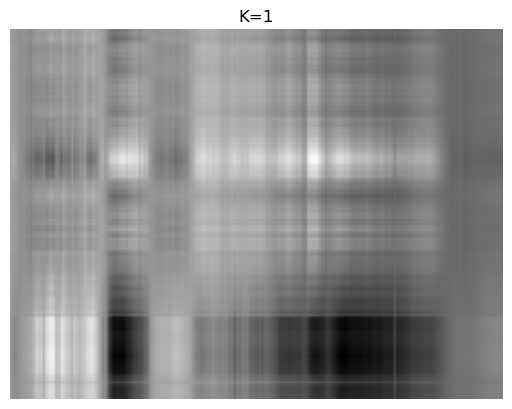

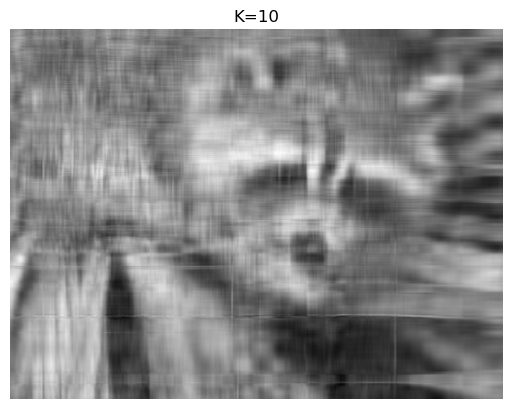

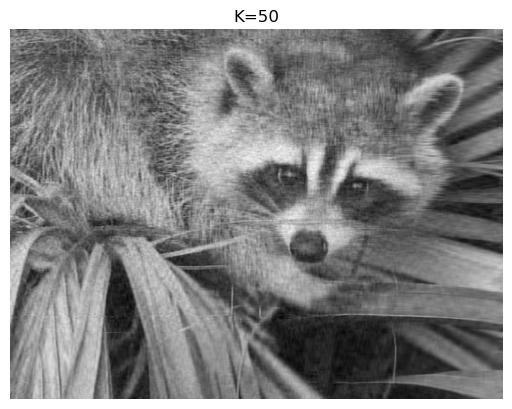

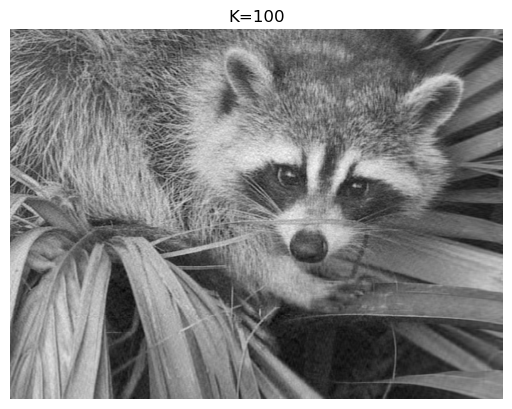

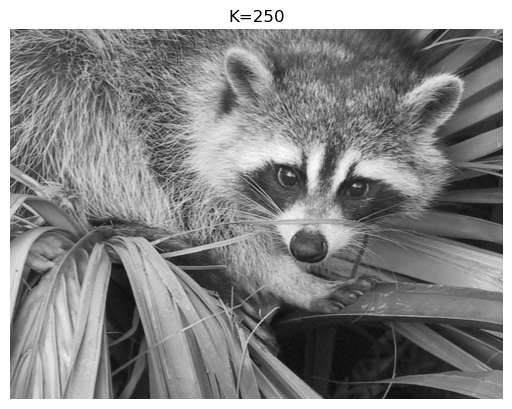

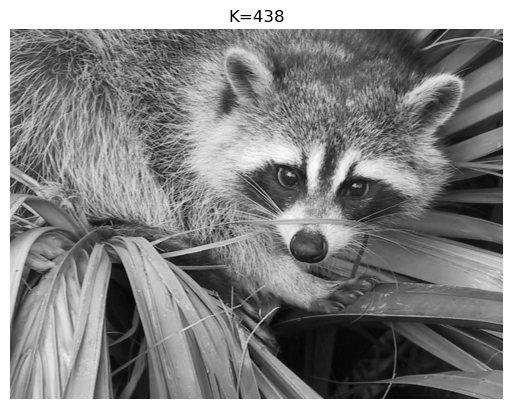

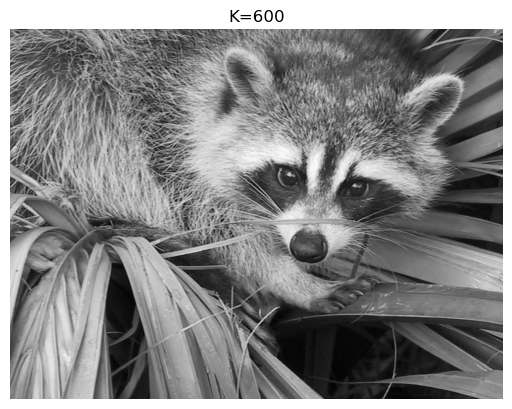

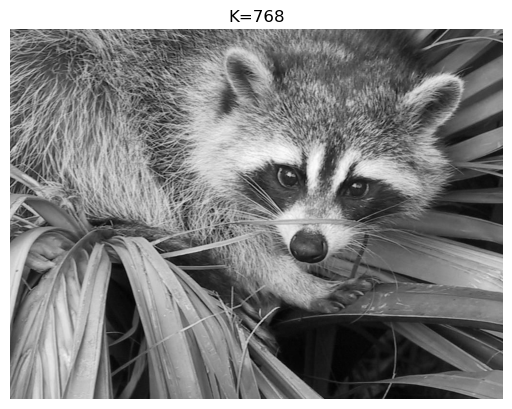

In [28]:
face = datasets.face(gray=True)
face_norm = face / 255.0

face_mean = face_norm.mean(axis=0)
face_std = face_norm.std(axis=0)

X = (face_norm - face_mean) / face_std   # standardisation

R = X.T@X #Je m'amuse à appeler la matrice de covariance de cette manière-ci !
eig_vals, eig_vecs = np.linalg.eigh(R)
idx = np.argsort(eig_vals)[::-1]
eig_vecs = eig_vecs[:, idx]

N, P = X.shape

for k in [1, 10, 50, 100, 250, 438, 600, 768]:
    W = eig_vecs[:, :k]
    scores = X @ W
    recon_std = scores @ W.T

    recon = recon_std * face_std + face_mean  # dé-standardisation

    plt.imshow(recon, cmap='gray')
    plt.title(f"K={k}")
    plt.axis("off")
    plt.show()

C'est très léger, mais vous remarquerez que les zones d'ombres ont été mieux recréées par l'ACP non normée que celle normée. Dans la deuxième version, on n'y distingue à peine les tiges, voire pas du tout. Sinon, l'image dans son global reste la même. 

Bien évidemment, l'ACP n'est pas la seule méthode de réduction des dimensions, et je vous encourage vivement à tester toutes les techniques de réduction de dimension que vous connaissez sur une image comme celle-ci. En effet, cela permet visuellement de comprendre les avantages et désavantages de chaque méthode de réduction de dimensionalité. 

J'espère que ce court passage sur la reconstruction des données via l'ACP vous a conquis. C'est souvent une méthode oubliée par certain mais pourtant primordiale à comprendre pour maîtriser l'ACP. Cela vous donnera peut être des idées dans des projets futurs...

Bon, revenons-en à notre problème principal: l'analyse des consommations énergétiques par pays ! Nous venons de voir qu'il était possible de récupérer des scores très proches des points initiaux. Nous pouvons aussi reconstruire la matrice de corrélation associée comme ceci:

Si $V$ est la matrice de tes vecteurs propres et $\Lambda$ la matrice diagonale de tes valeurs propres, la matrice de corrélation $R$ se calcule ainsi :$$R = V \Lambda V^T$$

Si tu n'utilises qu'un nombre $k$ d'axes, tu obtiens une matrice de corrélation reconstruite (approximée) :$$R_{approx} = V_{k} \Lambda_{k} V_{k}^T$$

In [29]:
cov_matrix_approx = eig_vecs_choosen@np.diag(eig_vals_sorted[:2])@eig_vecs_choosen.T

np.abs(cov_matrix_approx-cov_matrix_reduced).mean()

np.float64(0.07685781908593686)

On a une distance assez faible d'erreur absolue moyenne lors de la reconstruction matricielle. (à relativiser puisque les nombres sont compris entre -1 et 1.)
Notez que pour choisir le K optimal pour l'image du petit raton laveur, il faudra jouer sur la métrique que nous venons de voir ainsi que le % de compression des données. 

Bon, nous avons bientôt fini notre aventure, il nous reste maintenant plus qu'à afficher nos données. 

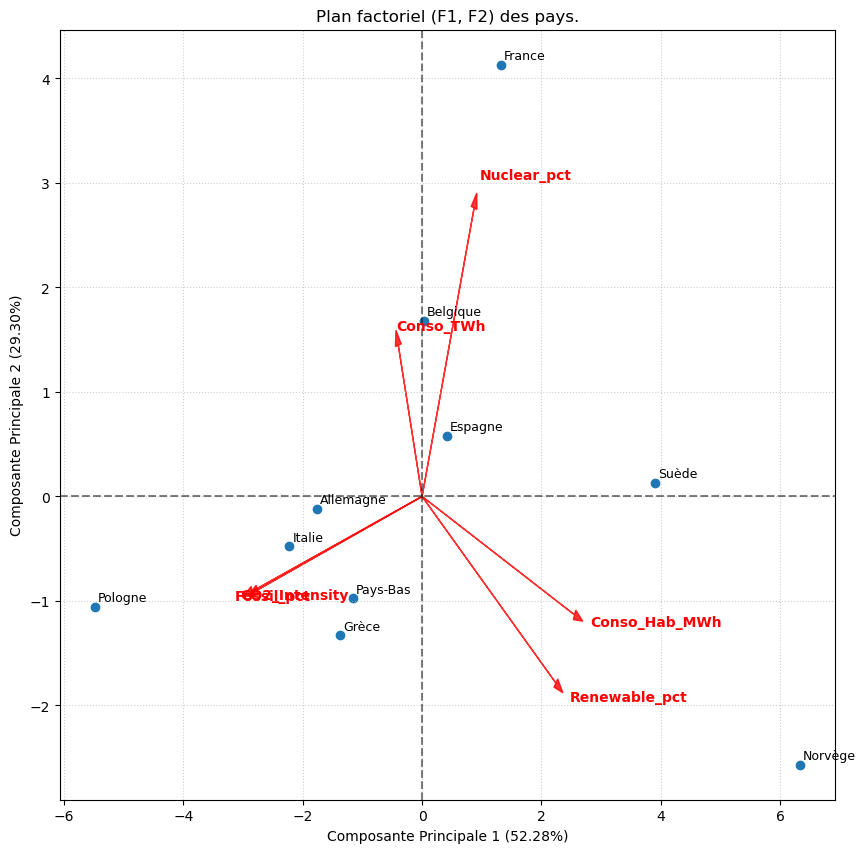

In [30]:
#je remets les variables car elles ont été supprimées lors du racoon face test.
G = np.mean(data, axis = 0)

X = data - G
Z = X/np.sqrt(sigmas)

eig_vals, eig_vecs = np.linalg.eigh(cov_matrix_reduced)
eig_vecs_sorted = eig_vecs[:,np.argsort(eig_vals)[::-1]]
eig_vecs_choosen = eig_vecs_sorted[:,:2]*np.sqrt(eig_vals_sorted[:2]) #L'ajustement est important pour tenir compte du poids des valeurs propres dans la représentation. 

loadings = eig_vecs_choosen
scores = Z @ loadings

x = scores.iloc[:,0].to_numpy()
y = scores.iloc[:,1].to_numpy()
plt.figure(figsize=(10,10))

plt.scatter(x,y)
for i, ville in enumerate(data.index):
    plt.text(x[i] + 0.05, y[i] + 0.05, ville, fontsize=9)
# Tracer une ligne horizontale à y = 0
plt.axhline(y=0, color='black', linestyle='--', alpha=0.5)

# Tracer une ligne verticale à x = 0
plt.axvline(x=0, color='black', linestyle='--', alpha=0.5)

# 1. Tracer les flèches des variables (Loadings)
# On multiplie par un facteur (ici 3) pour que les flèches soient à la même échelle que les pays
scale_factor = 3 

for i in range(loadings.shape[0]):
    # On trace la flèche
    plt.arrow(0, 0, loadings[i, 0] * scale_factor, loadings[i, 1] * scale_factor, 
              color='red', alpha=0.8, head_width=0.1)
    
    # On ajoute le nom de la variable (Charbon, Gaz, etc.)
    plt.text(loadings[i, 0] * scale_factor * 1.1, 
             loadings[i, 1] * scale_factor * 1.1, 
             data.columns[i], color='red', fontweight='bold')

# --- AJOUT DES TITRES AUX AXES ---
var_exp = (eig_vals_sorted / np.sum(eig_vals_sorted)) * 100
plt.xlabel(f"Composante Principale 1 ({var_exp[0]:.2f}%)")
plt.ylabel(f"Composante Principale 2 ({var_exp[1]:.2f}%)")

plt.title("Plan factoriel (F1, F2) des pays.")
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

C'est assez poétique comme graphique. La France semble clairement, avec l'Espagne et la Belgique, une grande utilisatrice de l'énergie nucléaire. Il semblerait d'autre part que ce soit l'énergie fossile qui rejette le plus d'intensité de C02. (c'est une simple vérité affirmée par ACP, et je sais qu'on avait pas besoin de tout cela pour le deviner !)

# Bonus: L'approche par la Décompositon en Valeurs Singulières.


Ici, ce n'est pas le but de faire une analyse de la décomposition en valeurs singlières dans tous ses retranchements. Je vais simplement vous montrer que nous trouvons les mêmes résultats par cette seconde méthode (utilisée par exemple par Scikit Learn pour gagner du temps)

In [31]:
U,S,Vh = np.linalg.svd(Z,full_matrices=False)
print(np.allclose(Vh.T[:,:-1],eig_vecs_sorted[:,:-1]))

False


In [32]:
display(pd.DataFrame(Vh.T)),display(pd.DataFrame(eig_vecs_sorted))

,0,1,2,3,4,5
0,-0.074978,0.363783,-0.921824,0.041083,-0.102918,0.000000e+00
1,0.480825,-0.284847,-0.086510,0.778801,-0.271395,-4.486864e-17
2,0.421970,-0.448962,-0.266420,-0.328605,0.360763,5.579105e-01
3,0.164052,0.694217,0.247498,0.256790,0.220021,5.617336e-01
4,-0.536223,-0.228328,0.015732,0.063979,-0.531789,6.108938e-01
5,-0.520268,-0.225582,-0.101359,0.462348,0.674088,-4.524180e-17


,0,1,2,3,4,5
0,-0.074978,0.363783,0.921824,-0.041083,-0.102918,4.135728e-16
1,0.480825,-0.284847,0.086510,-0.778801,-0.271395,7.138769e-16
2,0.421970,-0.448962,0.266420,0.328605,0.360763,5.579105e-01
3,0.164052,0.694217,-0.247498,-0.256790,0.220021,5.617336e-01
4,-0.536223,-0.228328,-0.015732,-0.063979,-0.531789,6.108938e-01
5,-0.520268,-0.225582,0.101359,-0.462348,0.674088,-2.498934e-15


(None, None)

Remarquez qu'au signe près (colinéarité) et à des arrondis près (erreur), nous avons dans le vecteur $V_h$, la transposée de la matrices composée des vecteurs propres obtenus lors de la diagnalisation de notre matrice de covariance. N'ayez donc pas peur si ici, le np.allclose affiche false.

Regardons ce que contient la matrice $U \times S$:

In [33]:
scores_svd = U @ np.diag(S)

display(pd.DataFrame(scores_svd)),display(scores/np.sqrt(eig_vals_sorted[:2]))

,0,1,2,3,4,5
0,-0.990700,-0.087191,-2.099858,-0.065366,0.115041,-1.032024e-16
1,0.744684,3.116250,-0.505081,0.255465,-0.023663,3.766524e-17
2,-1.254776,-0.358664,-0.605986,-0.236803,-0.311847,-8.146961e-17
3,-3.094630,-0.796591,0.323328,0.855524,0.121502,-4.018202e-17
4,2.201432,0.097792,0.420003,-0.129692,0.177536,-8.465903e-17
5,0.231978,0.435563,-0.068591,-0.645467,0.078764,-8.902934e-17
6,3.571237,-1.936451,-0.386929,0.533840,-0.077780,-3.676207e-17
7,-0.653704,-0.735030,0.542513,-0.286100,-0.083668,2.056096e-17
8,-0.772986,-1.001825,0.857511,-0.559248,0.088309,3.164976e-18
9,0.017467,1.266146,1.523090,0.277848,-0.084194,-1.527856e-16


,0,1
Pays,,
Allemagne,-0.990700,-0.087191
France,0.744684,3.116250
Italie,-1.254776,-0.358664
Pologne,-3.094630,-0.796591
Suède,2.201432,0.097792
Espagne,0.231978,0.435563
Norvège,3.571237,-1.936451
Pays-Bas,-0.653704,-0.735030
Grèce,-0.772986,-1.001825


(None, None)

En enlevant le scaling par les valeurs propres qu'on avait produit, on se rend compte que ce produit matriciel redonne les scores. AInsi, lorsqu'on essayait de créer nos matrices plus tôt en les approximant par un nombre d'axes factoriels réduit, nous faisons une décomposition en valeurs singulières. 

# Théorème:

Pour toute matrice $A \in \mathbb{R}^{n \times p}$, les valeurs singulières de $A$ sont les racines carrées des valeurs propres non nulles de la matrice $A^TA$ (ou de $AA^T$).Mathématiquement, si on note $\sigma_i(A)$ les valeurs singulières et $\lambda_i(M)$ les valeurs propres d'une matrice $M$ :$$\sigma_i(A) = \sqrt{\lambda_i(A^TA)}$$

Et oui, on remarquera donc que: $$\sigma_i(A) = \sqrt{\lambda_i(A^TA)} $$
d'où:
$$\sigma_i(A)^2 = \lambda_i(A^TA) $$

dans notre cas, on étudiait $\frac{Z^TZ}{n}$ (attention, ici la variance est biaisée si on ne standaridse pas !), donc on aura : 
$$\frac{\sigma_i(Z)^2}{n} = \lambda_i(Z^TZ) $$

In [34]:
print("Valeurs singulières: ",S,"\n", "Valeurs propres:", eig_vals_sorted) #Les valeurs propres et les valeurs singulières semblent différentes ?
print("--------------------------")
print("Valeurs singulières converties: ",S**2/n,"\n","Valeur propres :",eig_vals_sorted)
print("--------------------------")
print(np.linalg.matrix_rank(Z))

Valeurs singulières:  [5.60055663e+00 4.19261066e+00 2.96926588e+00 1.43100511e+00
 4.37568116e-01 2.46053480e-16] 
 Valeurs propres: [ 3.13662345e+00  1.75779841e+00  8.81653986e-01  2.04777562e-01
  1.91465856e-02 -5.46879530e-17]
--------------------------
Valeurs singulières converties:  [3.13662345e+00 1.75779841e+00 8.81653986e-01 2.04777562e-01
 1.91465856e-02 6.05423149e-33] 
 Valeur propres : [ 3.13662345e+00  1.75779841e+00  8.81653986e-01  2.04777562e-01
  1.91465856e-02 -5.46879530e-17]
--------------------------
5


In [35]:
#Bonus sur l'origine de U.

eig,eigv = np.linalg.eigh(Z@Z.T)
idx = np.argsort(eig)[::-1]

display(pd.DataFrame(eigv[:,idx][:,:p])), display(pd.DataFrame(U))

,0,1,2,3,4,5
0,-0.176893,0.020796,0.707198,-0.045678,0.262910,0.191789
1,0.132966,-0.743272,0.170103,0.178521,-0.054079,0.086827
2,-0.224045,0.085547,0.204086,-0.165480,-0.712683,0.520148
3,-0.552558,0.189999,-0.108891,0.597848,0.277675,0.135596
4,0.393074,-0.023325,-0.141450,-0.090630,0.405734,0.528023
5,0.041420,-0.103888,0.023100,-0.451059,0.180004,-0.165957
6,0.637658,0.461872,0.130311,0.373052,-0.177754,0.041860
7,-0.116721,0.175316,-0.182709,-0.199929,-0.191211,-0.368088
8,-0.138020,0.238950,-0.288796,-0.390808,0.201818,0.414425
9,0.003119,-0.301995,-0.512952,0.194163,-0.192415,0.226714


,0,1,2,3,4,5
0,-0.176893,-0.020796,-0.707198,-0.045678,0.262910,-0.419431
1,0.132966,0.743272,-0.170103,0.178521,-0.054079,0.153077
2,-0.224045,-0.085547,-0.204086,-0.165480,-0.712683,-0.331105
3,-0.552558,-0.189999,0.108891,0.597848,0.277675,-0.163306
4,0.393074,0.023325,0.141450,-0.090630,0.405734,-0.344068
5,0.041420,0.103888,-0.023100,-0.451059,0.180004,-0.361829
6,0.637658,-0.461872,-0.130311,0.373052,-0.177754,-0.149407
7,-0.116721,-0.175316,0.182709,-0.199929,-0.191211,0.083563
8,-0.138020,-0.238950,0.288796,-0.390808,0.201818,0.012863
9,0.003119,0.301995,0.512952,0.194163,-0.192415,-0.620945


(None, None)

A cause du rang de la matrice qui est 5 (pour rappel), on a un petit problème d'approximation pour la dernière valeur propre (qui est censée être parfaitement nulle). Sinon, on a bien réussi à les reconstruire. Félicitations ! 

Vous remarquerez aussi que U et $ZZ^T$ sont en relation via les vecteurs propres associés tout comme $V_h$ l'est avec $Z^tZ$. Les valeurs propres de $Z^TZ$ et les valeurs singulières sont aussi en relation. En réalité la SVD permet de généraliser le concept de diagonalisation. Cet algorithme d'algèbre linéaire étant très important, je pense un jour faire un cours complet permettant de comprendre ses tenants et aboutissants. 

Personnellement, je préfère l'approche par SVD pour réduire la dimensionalité des images car je la trouve plus simple: il suffit de récupérer les k premières colonnes de U, les k premières valeurs singulières de $\Sigma$ et les k premières lignes de $V_h$. Bref, ceci conclut cette approche bonus. Revenons au sujet principal: l'ACP sur nos pays pollueurs.

# Les différents indicateurs

A partir de maintenant, je vais utiliser un package appelé fanalysis. Ce package est optimisé pour l'implémentation des méthodes factorielles à la fois dans une démarche exploratrice mais aussi de data science (scikit-learn). L'avantage réside dans la rapidité d'utilisation de cet outil. Regardez :

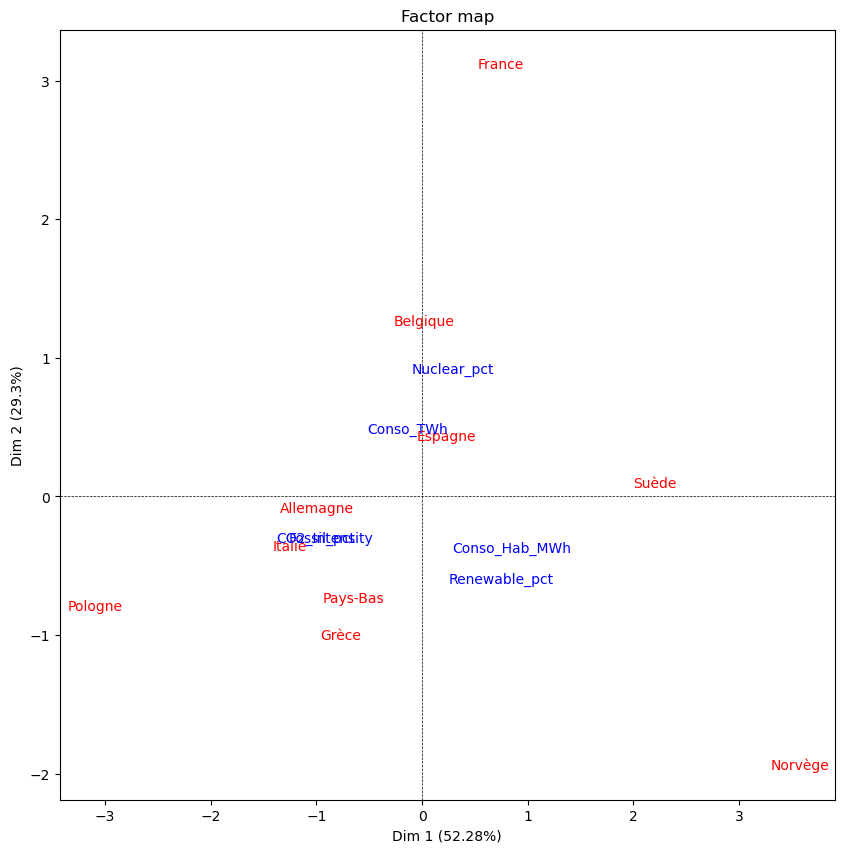

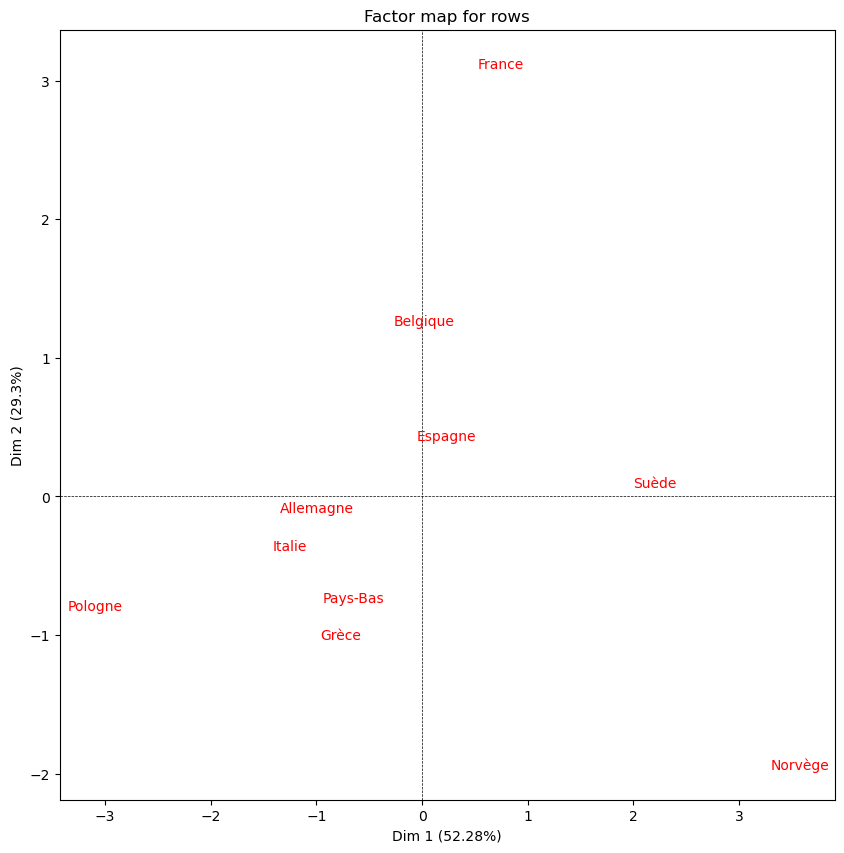

In [36]:
from fanalysis.pca import PCA
#std_unit permet de réduire les données centrées (ACP normée), stats = True sera utile par la suite pour calculer certains indicateurs que
#l'on va étudier par la suite. 
apc = PCA(std_unit=True,stats=True,row_labels=data.index,col_labels=data.columns) 
apc.fit(data.to_numpy())
apc.mapping(num_x_axis=1,num_y_axis=2,figsize=(10,10))
apc.mapping_row(num_x_axis=1,num_y_axis=2,figsize=(10,10))


# Lien entre un axe factoriel, sa valeur propre, sa variance et son coefficient de corrélation linéaire. 

## 1. Définition de l'Axe Factoriel
Soit $X$ la matrice des données **centrées et réduites** de taille $(n, p)$. 
Un axe factoriel (ou composante principale) $F_k$ est obtenu par la projection des données sur le vecteur propre $v_k$ associé à la matrice de corrélation :

$$F_k = X v_k$$

* $F_k$ : Vecteur de taille $n$ contenant les coordonnées (scores) des individus sur l'axe $k$.
* $v_k$ : Vecteur propre (loading) unitaire, tel que $\|v_k\|^2 = v_k^T v_k = 1$.

---

## 2. Expression de la Variance de l'Axe
Par définition, la variance d'un vecteur $F_k$ dont la moyenne est nulle (puisque $X$ est centrée) s'écrit :

$$\text{Var}(F_k) = \frac{1}{n} F_k^T F_k$$

En substituant $F_k$ par son expression de projection $X v_k$, on obtient :

$$\text{Var}(F_k) = \frac{1}{n} (X v_k)^T (X v_k)$$
$$\text{Var}(F_k) = \frac{1}{n} v_k^T X^T X v_k$$

---

## 3. Lien avec la Matrice de Corrélation
Dans le cas de données centrées-réduites, la matrice de corrélation $R$ est définie par :

$$R = \frac{1}{n} X^T X$$

L'expression de la variance devient alors une forme quadratique faisant intervenir $R$ :

$$\text{Var}(F_k) = v_k^T R v_k$$



---

## 4. Utilisation des Propriétés des Vecteurs Propres
Par définition, un vecteur propre $v_k$ de la matrice $R$ satisfait l'équation caractéristique :

$$R v_k = \lambda_k v_k$$

En remplaçant $R v_k$ dans notre équation de variance :

$$\text{Var}(F_k) = v_k^T (\lambda_k v_k)$$
$$\text{Var}(F_k) = \lambda_k (v_k^T v_k)$$

---

## 5. Conclusion
Puisque le vecteur propre est normé à 1 ($v_k^T v_k = 1$), le terme entre parenthèses disparaît, ce qui nous donne la preuve finale :

$$\text{Var}(F_k) = \lambda_k$$

---
Utilisations ces apprentissages pour démontrer la chose suivante: 
## 1. Définitions et Hypothèses
* **$X$** : Matrice des données **centrées-réduites** de taille $(n, p)$.
* **$x_j$** : La $j$-ème colonne de $X$ (variable $j$). Puisqu'elle est réduite, son écart-type $\sigma_{x_j} = 1$.
* **$v_k$** : Le $k$-ème vecteur propre de la matrice de corrélation $R$ (normé tel que $\|v_k\| = 1$).
* **$F_k = Xv_k$** : Le $k$-ème axe factoriel (composante principale).
* **$\lambda_k$** : La valeur propre associée à l'axe $k$. On sait que $\text{Var}(F_k) = \lambda_k$, donc l'écart-type de l'axe est $\sigma_{F_k} = \sqrt{\lambda_k}$.

---

## 2. Point de départ
La corrélation de Pearson entre la variable $x_j$ et l'axe $F_k$ est donnée par :

$$Corr(F_k, x_j) = \frac{Cov(F_k, x_j)}{\sigma_{F_k} \sigma_{x_j}} = \frac{Cov(Xv_k, x_j)}{\sqrt{\lambda_k} \times 1}$$

---

## 3. Développement du numérateur (Covariance)
En utilisant la définition matricielle de la covariance pour des données centrées :

$$Cov(Xv_k, x_j) = \frac{1}{n} (Xv_k)^T x_j$$

En appliquant la propriété de la transposée $(AB)^T = B^T A^T$ :

$$Cov(Xv_k, x_j) = \frac{1}{n} v_k^T X^T x_j$$

---

## 4. Lien avec la matrice de corrélation $R$
Le terme $\frac{1}{n} X^T x_j$ correspond mathématiquement à la $j$-ème colonne de la matrice de corrélation $R$. Notons ce vecteur colonne $R_j$.

$$Cov(Xv_k, x_j) = v_k^T R_j$$

Puisque $R$ est une matrice symétrique, $v_k^T R_j$ est le $j$-ème élément du vecteur résultant de $v_k^T R$. Or, par définition des vecteurs propres :

$$v_k^T R = \lambda_k v_k^T$$

Par conséquent, pour la composante $j$ :

$$v_k^T R_j = \lambda_k v_{jk}$$

*(Où $v_{jk}$ est la $j$-ème composante du vecteur propre $v_k$.)*

---

## 5. Conclusion Finale
En réinjectant ce résultat dans la formule de corrélation initiale :

$$Corr(F_k, x_j) = \frac{\lambda_k v_{jk}}{\sqrt{\lambda_k}}$$

En simplifiant par $\sqrt{\lambda_k}$, nous obtenons :

$$\mathbf{Corr(F_k, x_j) = v_{jk} \sqrt{\lambda_k}}$$

---
Cette valeur est exactement la coordonnée fournie par `fanalysis` dans `apc.col_coord_`. 

1. **Le signe** : Le signe de $v_{jk}$ indique si la variable évolue dans le même sens que l'axe ou à l'opposé.
2. **La magnitude** : Plus la corrélation est proche de 1 ou -1, mieux la variable est représentée sur le cercle des corrélations.

Mettons en place ceci pour voir quelles sont les corrélations les plus imortantes entre les axes ET les variables analysées. Pour ce faire, on va faire une HEATMAP, yaaaaaaaaaaaay :))))) :


<Axes: >

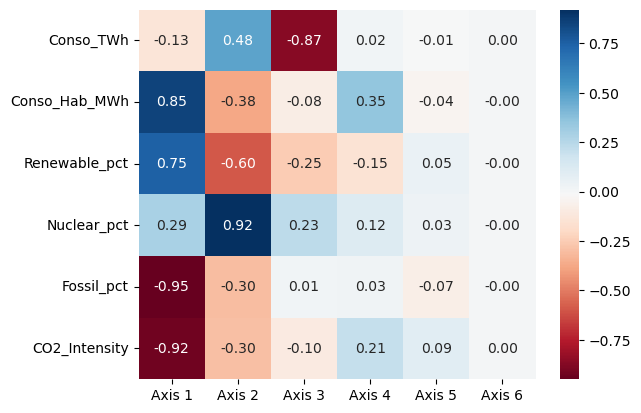

In [37]:
sns.heatmap(apc.col_coord_,annot=True,fmt=".2f",xticklabels=[f"Axis {k}" for k in range(1,apc.eig_.shape[1] + 1)],yticklabels=data.columns,cmap="RdBu")

On peut aussi retrouver ce coefficient de corrélation linéaire au sein d'un cercle des corrélations:

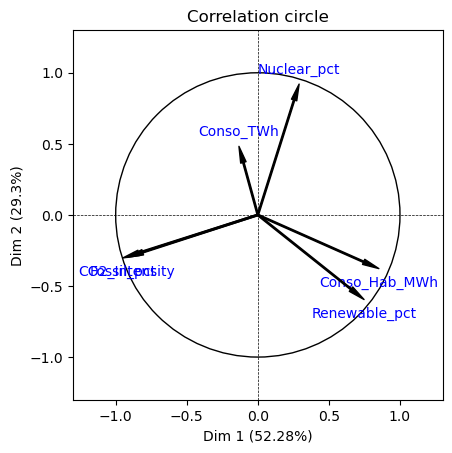

In [38]:
apc.correlation_circle(num_x_axis=1,num_y_axis=2,)

# Démonstration : Interprétation Géométrique et Cosinus de l'Angle

Comme démontré précédemment, la coordonnée d'une variable $x_j$ sur l'axe $F_k$ est :
$$Corr(F_k, x_j) = v_{jk} \sqrt{\lambda_k}$$

## 1. Lien avec le Cosinus
Dans l'espace des variables, la corrélation entre deux vecteurs est égale au **cosinus de l'angle** $\theta$ qu'ils forment, à condition que les variables soient centrées et réduites.

$$Corr(F_k, x_j) = \cos(\theta)$$

Sur le graphique :
* **L'axe (Dim 1 ou Dim 2)** représente le vecteur de la composante principale.
* **La flèche** représente le vecteur de la variable d'origine projeté dans ce plan.
* La valeur lue sur l'axe est la projection orthogonale de la flèche, soit : $\text{Longueur de la flèche} \times \cos(\theta)$.

## 2. La Qualité de Représentation ($cos^2$)
Puisque le rayon du cercle est 1, plus une flèche est longue (proche du bord du cercle), plus l'angle $\theta$ avec le plan factoriel est petit. 

On utilise souvent le **cosinus carré** pour mesurer la qualité de la représentation :
$$cos^2(\theta) = (Corr(F_k, x_j))^2$$

* Si $cos^2 \approx 1$ : La variable est très proche de l'axe, elle est parfaitement expliquée par lui (ex: `Nuclear_pct` sur la Dim 2).
* Si $cos^2 \approx 0$ : La variable est perpendiculaire à l'axe, elle n'a aucun lien avec lui.

## 3. Pourquoi un "Cercle" ?
Dans un espace complet à $p$ dimensions, la somme des $cos^2$ d'une variable sur tous les axes est toujours égale à 1 :
$$\sum_{k=1}^{p} Corr(F_k, x_j)^2 = 1$$

C'est l'application du théorème de Pythagore. C'est pour cela que dans le plan 2D, aucune flèche ne peut sortir du cercle de rayon 1. Si une flèche est courte, cela signifie simplement qu'elle est corrélée à un **troisième axe** que l'on ne voit pas sur ce graphique. C'est effectivement le cas pour Conso_TWh. 

In [39]:
#Regardez pourquoi:

print(np.linalg.norm(apc.col_coord_[0,:2]))
print(np.linalg.norm(apc.col_coord_[0,:3]))

0.5002570241446098
0.9997257498226649


Effectivement, on passe d'une norme de 0.50 à une norme d'environ 1. D'où le visuel ! Notez que lorsque je scalais mes points tout à l'heure pour plot les points sur mon Biplot afin de faire de beaux vecteurs, je multipliais en réalité cette norme par 3. Une analyse sur le cercle des corrélations aurait pu être faite, mais en prenant compte de ce rescaling du rayon du cercle de 1 à 3. 

De manière analogue, nous ne pouvons pas analyser les distances entre les points et les axes sur le graphique directement en faisant une "norme euclidienne" visuelle entre le nom d'une colonne et le nom d'une ligne ! Il faut passer par un ^cos^2^entre les deux vecteurs formés. 

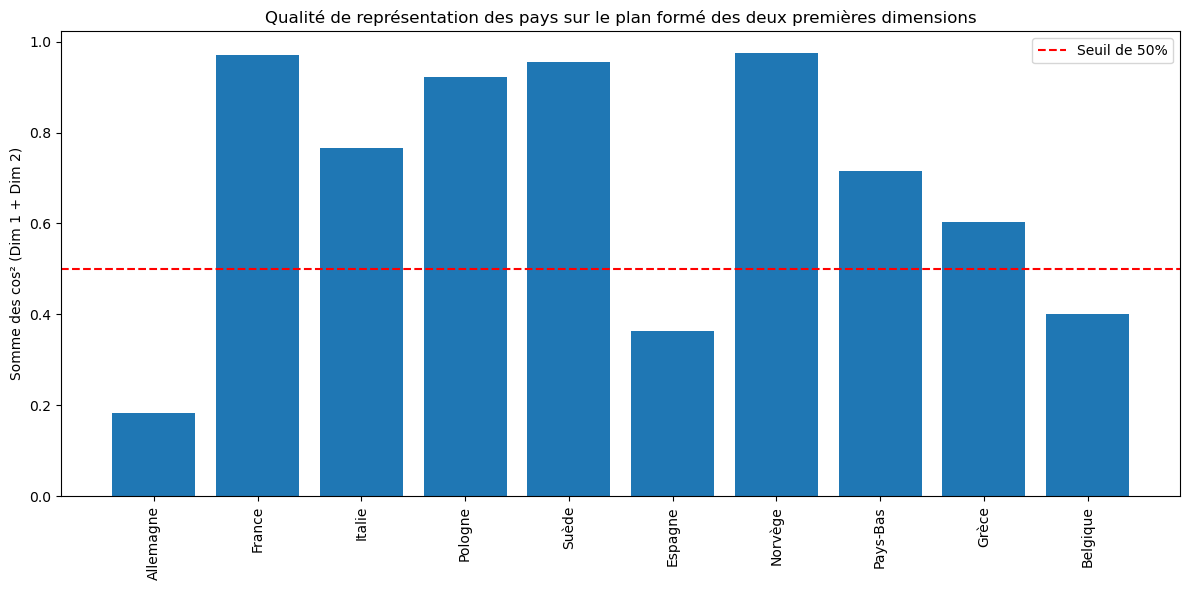

In [40]:
# 1. Calcul de la qualité (somme des cos2 sur les 2 premiers axes)
# On somme horizontalement (axis=1) pour avoir une valeur par ligne (pays)
qualite_pays = np.sum(apc.row_cos2_[:, :2], axis=1)

# 2. Création du graphique
plt.figure(figsize=(12, 6))
plt.bar(x=np.arange(len(qualite_pays)), height=qualite_pays, tick_label=data.index)

# 3. Cosmétique
plt.xticks(rotation=90) # Rotation pour lire les noms des pays
plt.axhline(y=0.5, color='r', linestyle='--', label='Seuil de 50%')
plt.ylabel('Somme des cos² (Dim 1 + Dim 2)')
plt.title('Qualité de représentation des pays sur le plan formé des deux premières dimensions')
plt.legend()
plt.tight_layout()
plt.show()

Remarquons que notre analyse aura du mal à saisir parfaitement certains pays comme l'allemagne, l'espagne ou encore la Belgique. Encore une fois, vous aurez compris que la heatmap (youhou) va nous aider à comprendre mieux cela. 

<Axes: >

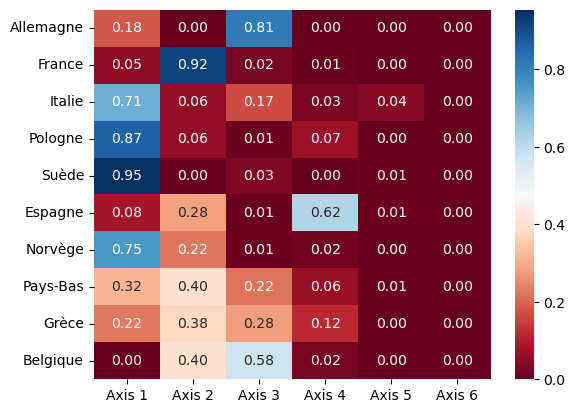

In [41]:
cos2_row = apc.row_cos2_

sns.heatmap(cos2_row,annot=True,fmt=".2f", yticklabels=data.index, xticklabels=[f"Axis {k}" for k in range (1,data.shape[1] +1)], cmap = "RdBu")

On voit clairement qu'on manque cruellement d'informations pour ces trois pays et on comprend pourquoi. 

In [42]:
data

,Conso_TWh,Conso_Hab_MWh,Renewable_pct,Nuclear_pct,Fossil_pct,CO2_Intensity
Pays,,,,,,
Allemagne,505.2,6.1,54.1,0.0,45.9,380
France,445.0,6.5,26.0,65.0,9.0,55
Italie,295.5,5.0,43.5,0.0,56.5,320
Pologne,165.8,4.4,21.0,0.0,79.0,650
Suède,135.2,12.8,68.0,28.0,4.0,15
Espagne,240.1,5.1,52.3,20.0,27.7,145
Norvège,128.5,23.4,98.5,0.0,1.5,8
Pays-Bas,108.4,6.1,48.2,3.5,48.3,280
Grèce,48.2,4.6,51.2,0.0,48.8,295


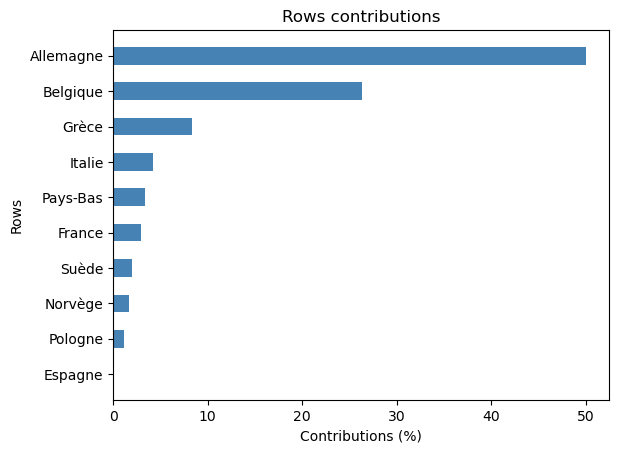

In [43]:
apc.plot_row_contrib(num_axis=3)

Essayons d'implémenter de nouvelles données.

In [44]:
data_bis = pd.read_csv("electricity-report-bis.csv",index_col=0)
display(data_bis)

,Conso_TWh,Conso_Hab_MWh,Renewable_pct,Nuclear_pct,Fossil_pct,CO2_intensity
Pays,,,,,,
Danemark_bis,35.0,6.0,75.0,0.0,25.0,80
Suisse_bis,60.0,6.8,60.0,35.0,5.0,25
Autriche_bis,70.0,7.8,80.0,0.0,20.0,90
Portugal_bis,50.0,4.9,65.0,0.0,35.0,120
Tchéquie_bis,65.0,6.1,15.0,35.0,50.0,420


L'ajout de ces 5 pays européens permet de tester la robustesse de notre modèle ACP. Voici les hypothèses d'interprétation avant de relancer les calculs sur la base du plan factoriel actuel.

## 1. Hypothèses de placement sur le Biplot
En nous basant sur les corrélations déjà identifiées, nous pouvons anticiper la position de ces nouveaux points :

* **Renforcement du pôle Renouvelable** : 
    * **Autriche_bis** (80%) et **Danemark_bis** (75%) devraient se projeter très loin dans la direction de la flèche `Renewable_pct`. 
    * Ils se situeront probablement dans le quadrant inférieur droit, proche de la **Norvège**.
* **Profils Low-Carbon Mixtes** : 
    * **Suisse_bis** (60% Renouvelable, 35% Nucléaire) est un profil très propre. Elle devrait se situer à mi-chemin entre la **France** et la **Suède**. 
    * Son intensité CO2 très basse (25) la placera à l'opposé exact du vecteur `CO2_intensity`.
* **Transition et Inertie Fossile** : 
    * **Tchéquie_bis** combine Nucléaire (35%) et Fossile (50%). Sa position devrait être proche de la **Belgique**, mais plus décalée vers la gauche à cause d'une `CO2_intensity` plus élevée (420).
    * **Portugal_bis** (65% Renouvelable) devrait suivre la trace de l'**Espagne**, confirmant la cohérence géographique des mix énergétiques.

## 2. Fiabilité attendue (cos²)
On peut s'attendre à ce que la qualité de représentation ($cos^2$) de ces pays soit élevée sur le premier plan (Dim 1 & Dim 2) car leurs profils s'alignent sur les variables qui portent le plus de variance dans notre étude.

Ici, je fais des prédictions qui peuvent s'avérer bien évidemment fausses. L'important sera de comprendre pourquoi si c'est le cas. 

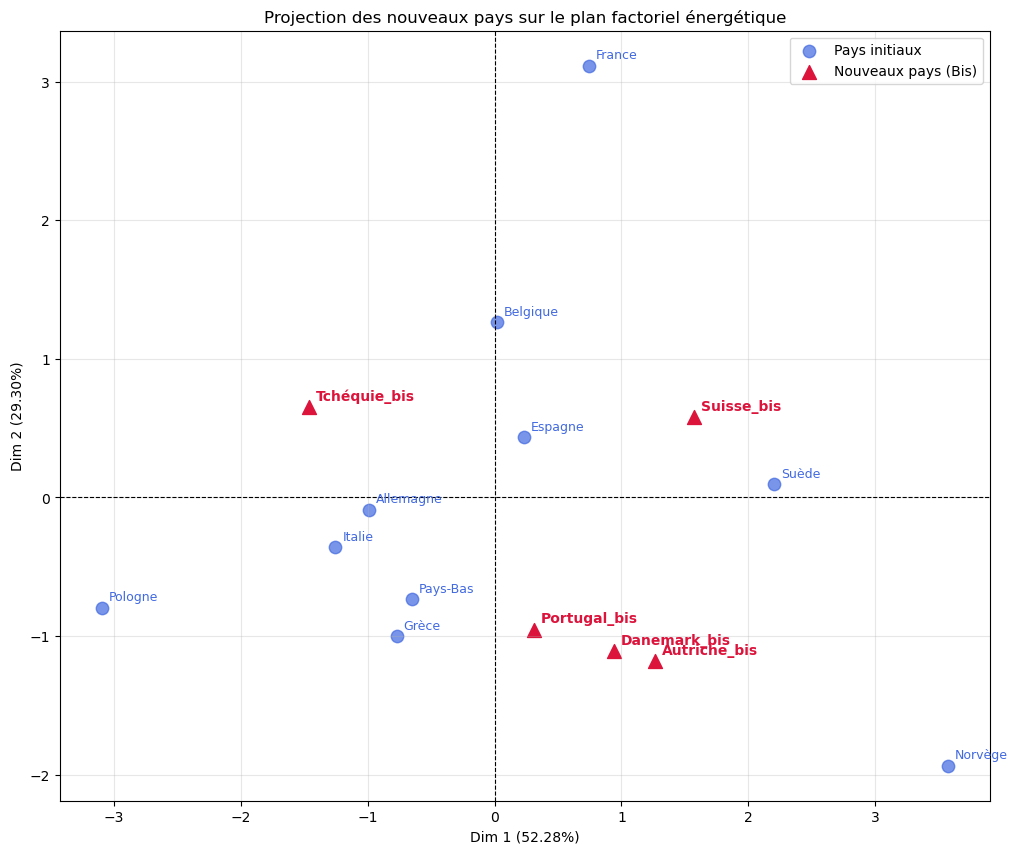

In [45]:
scores_bis = apc.transform(data_bis.to_numpy())
#Il faut recréer les graphiques à la main puisque la projection de nouveaux points sur un graphique n'est pas supportée. 

plt.figure(figsize=(12, 10))

# Affichage des anciens pays (Bleu)
plt.scatter(apc.row_coord_[:, 0], apc.row_coord_[:, 1], 
            color='royalblue', alpha=0.7, label='Pays initiaux', s=80)
for i, txt in enumerate(data.index):
    plt.annotate(txt, (apc.row_coord_[i, 0], apc.row_coord_[i, 1]), 
                 xytext=(5,5), textcoords='offset points', fontsize=9, color='royalblue')

# Affichage des nouveaux pays (Rouge)
# On utilise ici les coordonnées calculées pour data_bis
plt.scatter(scores_bis[:, 0], scores_bis[:, 1], 
            color='crimson', marker='^', s=100, label='Nouveaux pays (Bis)')
for i, txt in enumerate(data_bis.index):
    plt.annotate(txt, (scores_bis[i, 0], scores_bis[i, 1]), 
                 xytext=(5,5), textcoords='offset points', fontsize=10, weight='bold', color='crimson')

# Esthétique du graphique
plt.axhline(0, color='black', linestyle='--', linewidth=0.8)
plt.axvline(0, color='black', linestyle='--', linewidth=0.8)
plt.xlabel(f"Dim 1 ({apc.eig_[1][0]:.2f}%)")
plt.ylabel(f"Dim 2 ({apc.eig_[1][1]:.2f}%)")
plt.title("Projection des nouveaux pays sur le plan factoriel énergétique")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Les résultats semblent plutôt être logiques par rapport aux profils de points que l'on a ajouté. Comme vous le voyez, l'ACO fait un bon boulot pour mettre de nouveaux points lorsqu'ils ne dérivent pas trop des profils des pays basiques. 

Mettre des points supplémentaires peut servir à plusieurs choses: à pouvoir utiliser une pipeline scikit learn sans n'avoir de data leakage entre le train set et test set, par exemple. Mais la projection de points supplémentaire sert surtout à l'interprétation: il permet de renforcer notre compréhension des axes, des clusters, permet aussi de savoir où se situe un pays par rapport aux autres lorsqu'on a déjà un échantillon représentatif de "profils différents", où encore la détection de nouveauté. Si ici, nous avons es chiffres pour 2025, il serait intéressant, de projeter par exemple les points de la France pour 2026, ou encore 2027 et voir comment évolue la tendance. Cela permettrait alors de vite se rendre compte d'une nouveauté dans le comportement franais: changeront-ils de levier, commenceront-ils à délaisser l'énergie nucléaire au profit de celle nouvelable ou encore carbonnée, etc...

Ou, la détection de nouveauté peut aussi être utile pour trouver des points-pays qui ne correspondent pas du tout à la structure des autres pays déjà analysés. Mais comment prouver si un point est "nouveau" dans ce sens-ci ? C'est ici quue

Faisons un exercice supplémentaire: le but est de vous montrer la puissance de PCA au travers de la création d'un dataset fictif. Nous allons faire un algorithme de clustering pour cela. 

In [46]:
from sklearn.datasets import make_classification

#Hyperparamètres. 
RANDOM_SEED = 1 #On fixe l'aléatoire.
np.random.seed(RANDOM_SEED)
N_SAMPLES = 10000 #On met beaucoup de points pour que l'on ait du mal à  analyser facilement ces derniers. 
N_FEATURES = 50
N_INFORMATIVE = np.random.randint(0,51)
N_REDUNDANT = np.random.randint(0,50 - N_INFORMATIVE)
N_REPEATED = 50 - N_INFORMATIVE - N_REDUNDANT
N_CLASSES = np.random.randint(1,51) #C'est le nombre de clusters. On veut deviner sans se spoiler avec y cet hyperparamètre au final. 



X,y = make_classification(
    n_samples=N_SAMPLES,
    n_features=N_FEATURES,
    n_informative=N_INFORMATIVE,
    n_redundant=N_REDUNDANT,
    n_repeated=N_REPEATED,
    n_clusters_per_class=1, #On veut faire du clustering.
    flip_y=0.05,
    class_sep=10,
    n_classes = N_CLASSES, #Nombre de clusters,
    random_state = RANDOM_SEED #On garde toujours le même aléatoire.
)
# print(np.linalg.matrix_rank(X)) #Si vous enlevez cette ligne, vous vous spoilerez sur le nombre de colonnes redondantes
X+= np.random.randn(X.shape[0],X.shape[1]) #On ajoute un tout petit peu de bruit Gaussien pour casser la fonction rang de la matrice

print(np.linalg.matrix_rank(X)) #Preuve

50


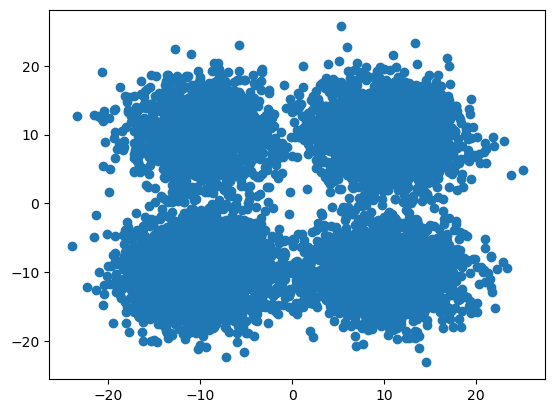

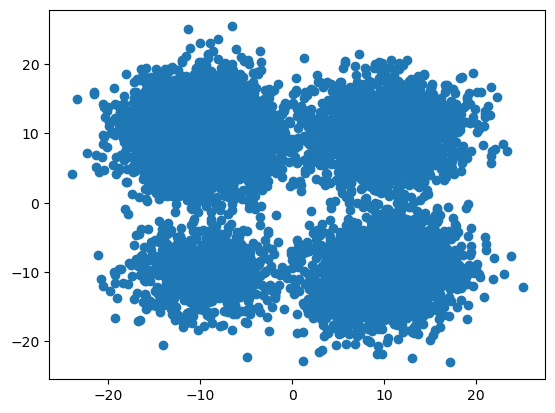

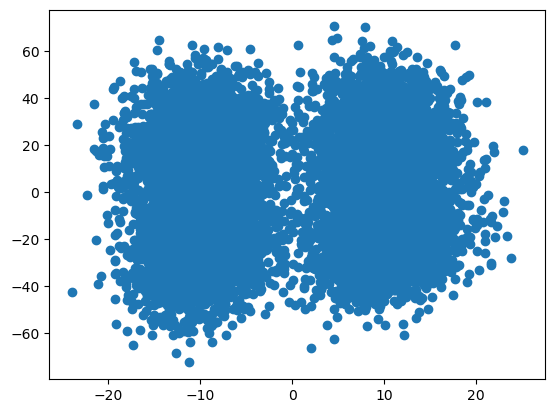

In [47]:
plt.scatter(X[:,0],X[:,1])
plt.figure()
plt.scatter(X[:,0],X[:,2])
plt.figure()
plt.scatter(X[:,0],X[:,4])
#Si vous voulez vous aider.
#plt.figure()
#plt.scatter(X[:,0],X[:,1],c=y)


Apparemment, cela va être difficile de deviner le nombre de features non redondantes, surtout si je n'affiche pas la couleur des labels y. Ici, c'est fait exprès car sinon nous saurons le nombre de clusters existants. (n_classes) Il pourrait y avoir 4 clusters, mais la troisième image nous ferait penser qu'il y en a 2... Pour rappel, dans la réalité, vous n'aurez pas forcément les labels (en Unsupervised Learning.)

Cela n'est pas vraiment un problème grâce à la puissance de PCA et de l'Algèbre Linéaire.

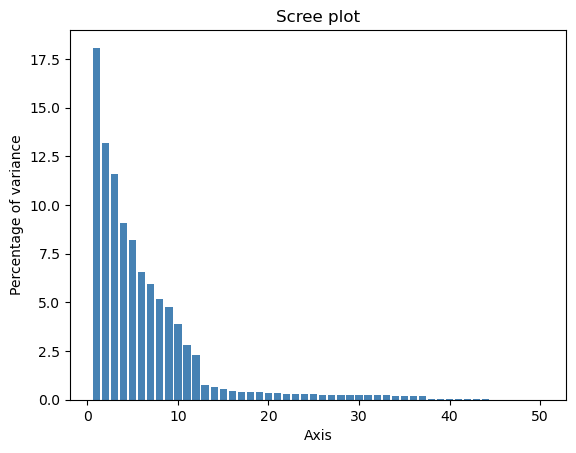

Kaiser Rule 12
Saporta rule 11
Broken stick rule 12


In [48]:
clusterPCA = PCA()
clusterPCA.fit(X)
clusterPCA.plot_eigenvalues(type = "percentage")
print("Kaiser Rule", np.sum(clusterPCA.eig_ [0]> 1))
print('Saporta rule', np.sum(clusterPCA.eig_[0] > 1 + 2*np.sqrt( (X.shape[1]-1) / (X.shape[0] - 1) )))

thresholds = [np.sum( 1/np.arange(i,len(clusterPCA.eig_[0]) + 1)) for i in range(1,len(clusterPCA.eig_[0]) + 1)]
print("Broken stick rule", np.sum(clusterPCA.eig_[1] > thresholds))

D'après la méthode du coude, nous trouvons qu'il y a entre 12 et 13 potentiels axes principaux. Il faut en général au plus $k-1$ à k dimensions pour découper les différents clusters. Bien sûr, PCA n'est pas un algorithme de clustering. Ce sera l'algorithme de clustering qui permettra de déterminer cela précisément !

En attendant, on sait que nous avons environ 35 à 37 variables "informatives", et seulement 12 à 13 variables très informatives. Du point de vue de nos différentes méthodes, il semblerait que ce soit 12 le nombre optimal d'axes à garder. 

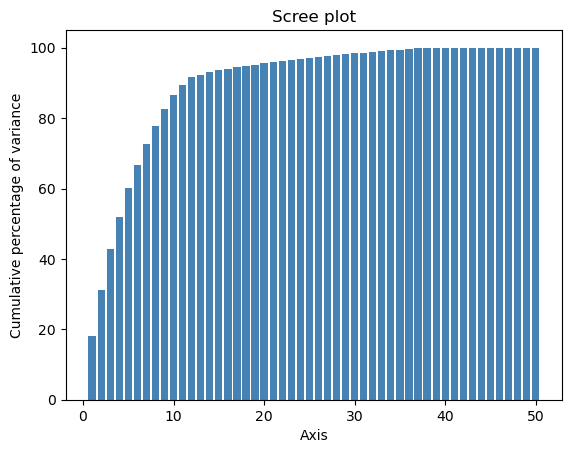

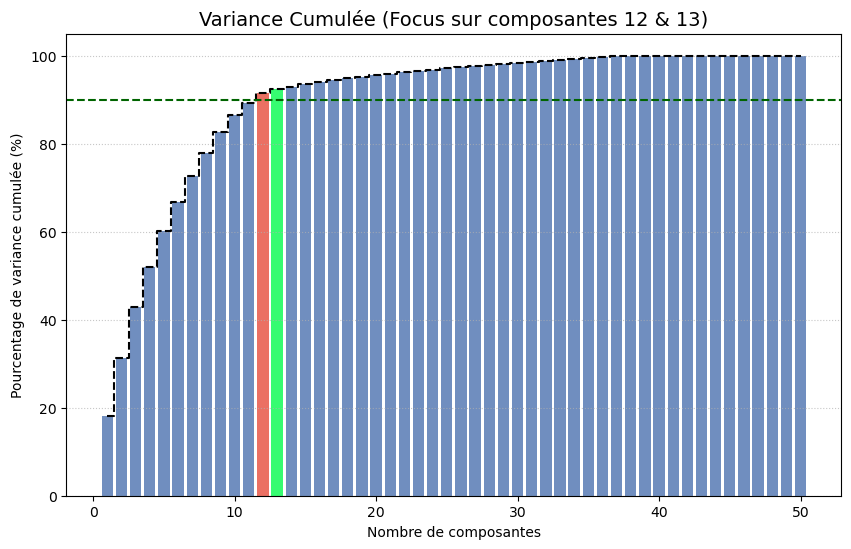

In [49]:
import matplotlib.pyplot as plt
import numpy as np

clusterPCA.plot_eigenvalues(type="cumulative")

# 1. Récupération des données (en %)
variances = clusterPCA.eig_[1]
cumul_variance = np.cumsum(variances)
n_components = len(variances)

# 2. Préparatiaon des couleurs
# Bleu standard pour tout le monde, rouge pour la 12 et la 13
colors = ['#4C72B0'] * n_components
colors[11] = '#E74C3C'  # Index 11 = Barre 12
colors[12] = '#03fc4e'  # Index 12 = Barre 13

# 3. Création du graphique
plt.figure(figsize=(10, 6))

# Dessin des barres cumulées
plt.bar(range(1, n_components + 1), cumul_variance, color=colors, alpha=0.8)

# Ajout de la ligne d'évolution pour le style "cumulative"
plt.step(range(1, n_components + 1), cumul_variance, where='mid', color='black', linestyle='--')

# 4. Habillage
plt.title("Variance Cumulée (Focus sur composantes 12 & 13)", fontsize=14)
plt.xlabel("Nombre de composantes")
plt.ylabel("Pourcentage de variance cumulée (%)")
plt.grid(axis='y', linestyle=':', alpha=0.7)

# Optionnel : Ajout d'une ligne à 80% ou 90% pour voir le seuil classique
plt.axhline(y=90, color='darkgreen', linestyle='--', label='Seuil 80%')

plt.show()

Cela a l'air d'être graphiquement une bonne idée. 

Les corrélations cos2 quant à elles semblent être en relation avec nos différents clusters ?

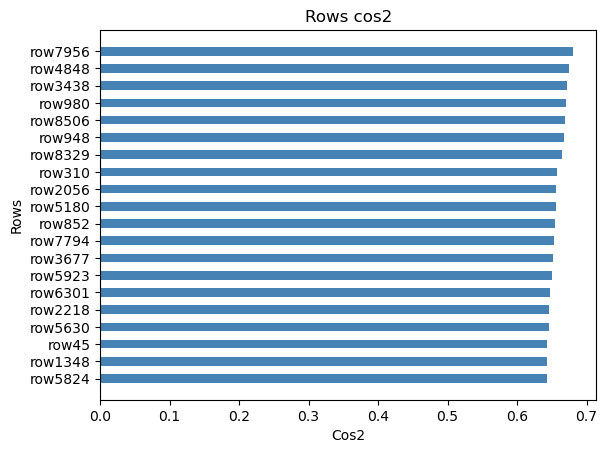

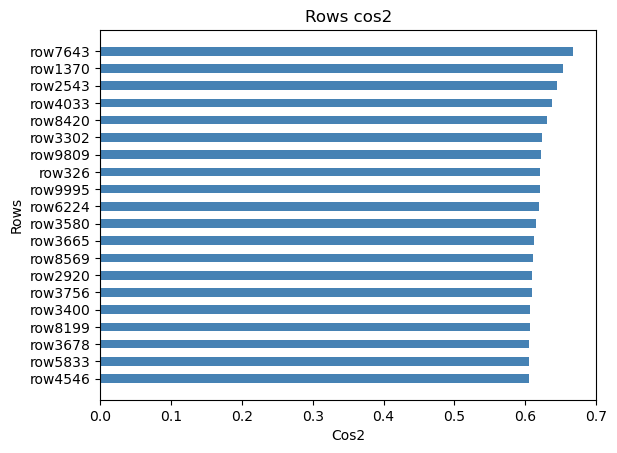

In [50]:
clusterPCA.plot_row_cos2(num_axis=1,nb_values=20)
clusterPCA.plot_row_cos2(num_axis=2,nb_values=20)

Bon, c'est assez compliqué de se rendre compte  de l'utilité de ces graphiques avec tant d'informations.  Il semblerait néanmoins que certains axes donnent plus d'importances de d'autres. Regardons cela de plus près.

<Axes: >

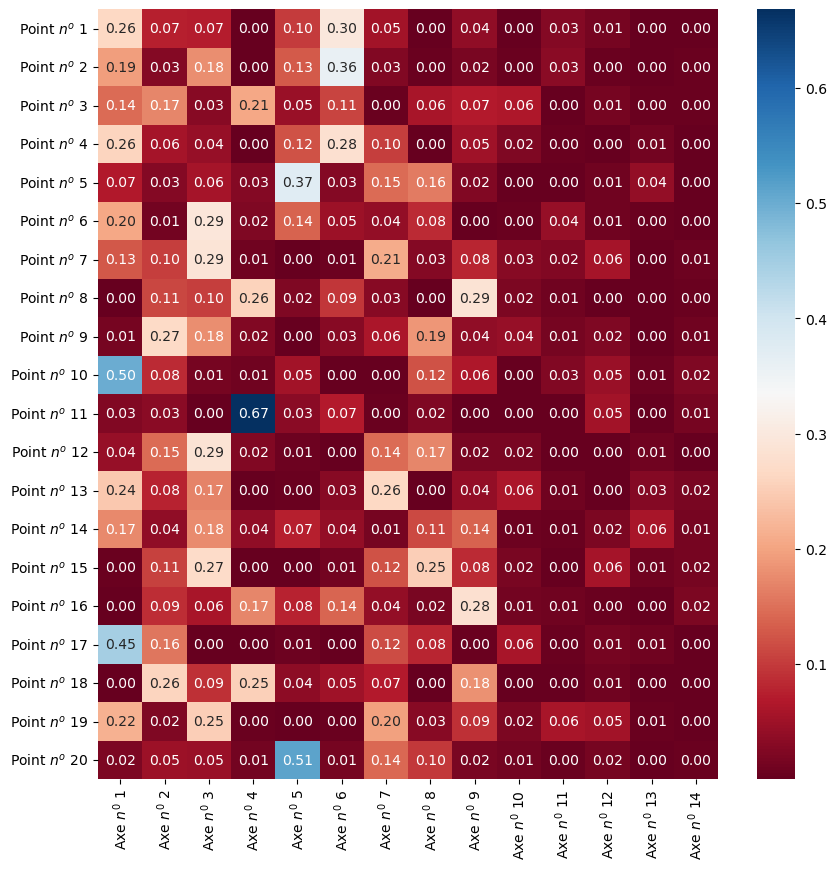

In [51]:
cos2_val = clusterPCA.row_cos2_[:20,:14]
plt.figure(figsize=(10,10))
sns.heatmap(cos2_val,cmap="RdBu",annot=True,fmt="0.2f",yticklabels=[f'Point $n^o$ {k}' for k in range(1,21)],xticklabels=[f"Axe $n^0$ {k}" for k in range(1,15)])

Pour rappel, nous avons des points qui ont été fait de manière à rajouter du "bruit". Il y a donc des points qui sont dans certains clusters, mais qui n'ont pas les bons labels. Il se pourrait qu'il y ait une corrélation entre les lignes qui n'affichent pas de corrélation claire avec un axe ET ces points-ci. 

Prenons pour exemples les points 11 et 12. 

In [52]:
point11 = np.round(clusterPCA.row_cos2_[10],2)
point12 = np.round(clusterPCA.row_cos2_[11],2)
print(point11)
print("---------------")
print(point12)

[0.03 0.03 0.   0.67 0.03 0.07 0.   0.02 0.   0.   0.   0.05 0.   0.01
 0.03 0.   0.   0.01 0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
 0.   0.01 0.01 0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
 0.   0.   0.   0.   0.   0.   0.   0.  ]
---------------
[0.04 0.15 0.29 0.02 0.01 0.   0.14 0.17 0.02 0.02 0.   0.   0.01 0.
 0.   0.   0.   0.   0.05 0.   0.01 0.01 0.   0.   0.   0.01 0.01 0.01
 0.   0.   0.01 0.   0.   0.   0.   0.   0.01 0.   0.   0.   0.   0.
 0.   0.   0.   0.   0.   0.   0.   0.  ]


Essayons de voir donc si nous pouvons en déduire des clusters différents en considérents différents axes. 

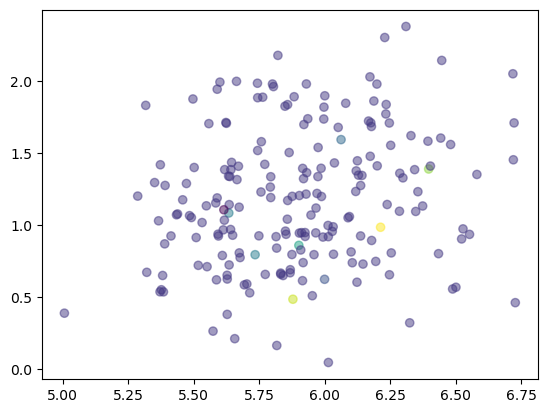

In [53]:
#AXe factoriel numéro 1.

idx = np.argsort(clusterPCA.row_cos2_[:,0])[::-1]
plt.scatter(clusterPCA.row_coord_[idx[:200],0],clusterPCA.row_coord_[idx[:200],1],c=y[idx[:200]],alpha=0.5)

In [54]:
1/20 #Les erreurs de couleurs ont l'air d'être reliées aux erreurs causées par flip_y. 

0.05

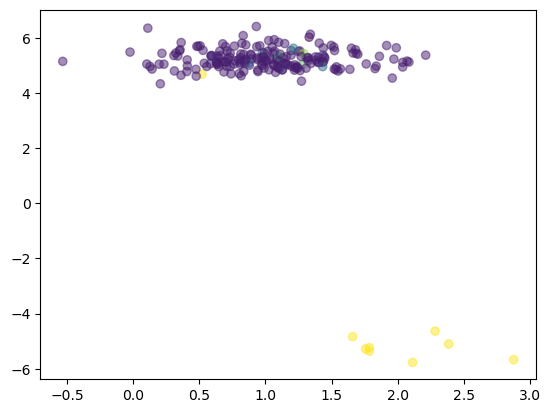

In [55]:
# Axe factoriel numéro 2
idx = np.argsort(clusterPCA.row_cos2_[:,1])[::-1]
plt.scatter(clusterPCA.row_coord_[idx[:200],0],clusterPCA.row_coord_[idx[:200],1],c=y[idx[:200]],alpha=0.5)

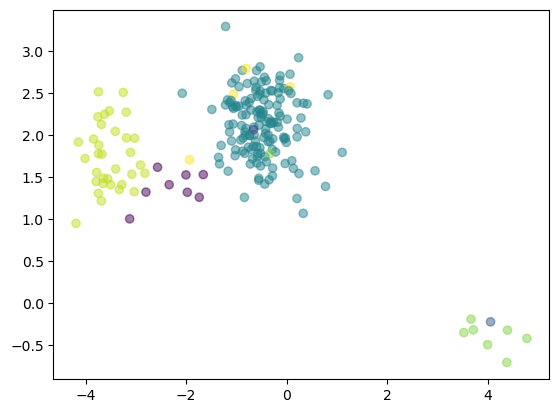

In [56]:
# Axe factoriel numéro 3
idx = np.argsort(clusterPCA.row_cos2_[:,2])[::-1]
plt.scatter(clusterPCA.row_coord_[idx[:200],0],clusterPCA.row_coord_[idx[:200],1],c=y[idx[:200]],alpha=0.5)

Les points semblent plutôt bien répartis lorsqu'on considère les points avec les meilleurs cos2. L'axe factoriel 3 semble intéressant puisqu'on a deux clusters différents semble-t-il (voire même 4 ?) 

On pourrait alors se demander la corrélation entre ces points. dans le second graphiquek il est clair que les deux nuages représentés sont très bien découpés. Ici, il serait très dur d'analyser des heatmap. C'est pourquoi nous allons opter pour une vision beaucoup plus globale et nous allons regarder le résultat global de PCA sur les axes principaux ainsi que les axes les moins informatifs pour voir à quel point ces axes ne nous servirons pas. 

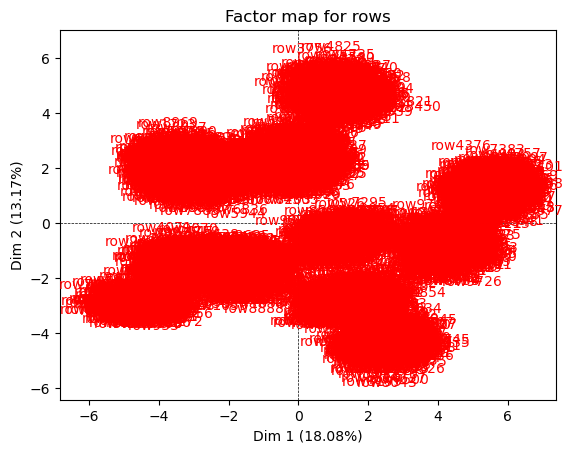

In [57]:
clusterPCA.mapping_row(num_x_axis=1,num_y_axis=2)

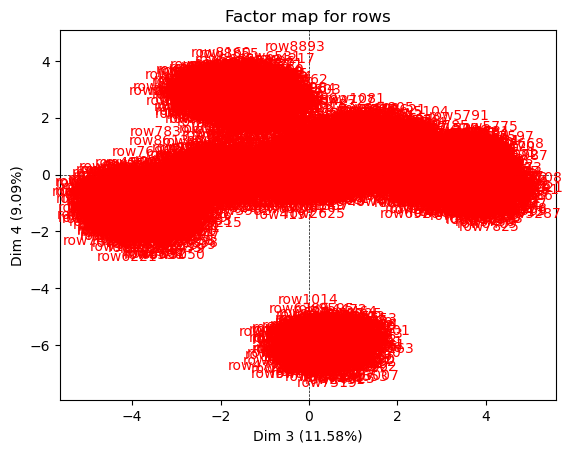

In [58]:
clusterPCA.mapping_row(num_x_axis=3,num_y_axis=4)

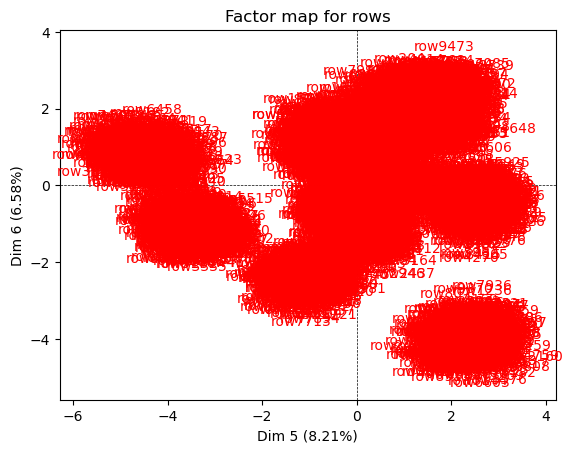

In [59]:
clusterPCA.mapping_row(num_x_axis=5,num_y_axis=6)

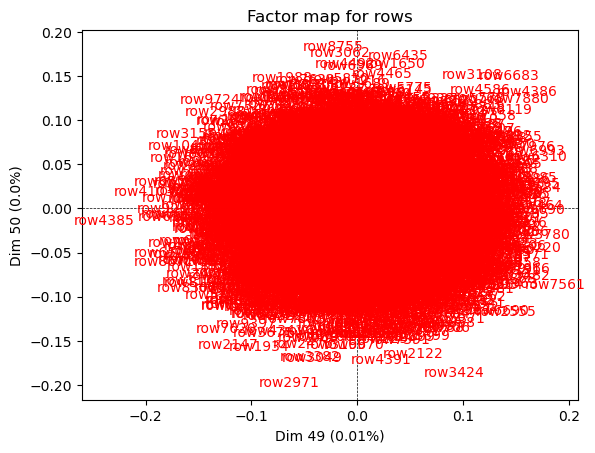

In [60]:
clusterPCA.mapping_row(num_x_axis=49,num_y_axis=50)

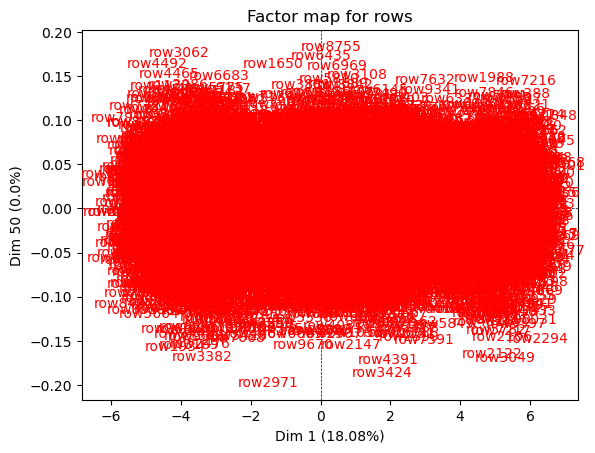

In [61]:
clusterPCA.mapping_row(num_x_axis=1,num_y_axis=50)

 PCA fait un travail assez professionnel. Remarquez qu'on a réussi à dégoter plus d'informations grâce à PCA avec ces plots que sur les plots préalables où on avait trouvé que. 4 clusters apparents. Ici, il semblerait qu'il y en ait au visuel, au moins 11 (qui est proche du nombre d'axes factoriels que l'on a choisit par ailleurs.

 On pourrait y passer des heures à chercher la petite bête pour deviner comment PCA fonctionne en long en large et en travers !

 Remarquez néanmoins que la quantité (le % d'inertie) récolté dans chacun des axes par PCA est relativement petit (puisqu'on a beaucoup de valeurs propres à considérer.) Nous verrons plus tard qu'une rotation des axes de façon orthogonale pourrait être une solution à ce problème, ce qui nous permettrait peut être d'en connaître encore plus grâce à ces plots.

En attendant, nous voyons que nous pouvons faire assez confiance à PCA en ce qui concerne le clustering (il semble garder ces formes de gaussiennes du dataset de base.) Passons donc rapidement un k-mens et faisons un rapide gridsearchcv dessus. 

In [62]:
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import silhouette_score, make_scorer

# 1. Définir une fonction de scoring personnalisée
def silhouette_scorer(estimator, X):
    # L'estimateur ici sera la pipeline
    # On récupère les labels prédits par le dernier élément (le clustering)
    labels = estimator.fit_predict(X)
    # Si le clustering ne produit qu'un seul cluster, la silhouette n'est pas définie
    if len(set(labels)) < 2:
        return -1
    return silhouette_score(X, labels)

# 2. Créer la Pipeline
# Note : StandardScaler est fortement recommandé avant une PCA
pipeline = Pipeline([
    ('pca', PCA(n_components=12)),
    ('kmeans', KMeans(random_state=42))
])

# 3. Définir la grille de recherche
# On teste le nombre de composantes PCA et le nombre de clusters
param_grid = {
    'kmeans__n_clusters': np.arange(1,20) #Je mets un peu plus que les points que je pense que ce soit eux, c'est à dire 11 12 13, etc...
}

# 4. Lancer le GridSearch
grid_search = GridSearchCV(
    pipeline, 
    param_grid, 
    scoring=silhouette_scorer, # Utilise notre fonction personnalisée
    cv=5 # Ou une autre méthode de validation
)

grid_search.fit(X)

print(f"Meilleurs paramètres : {grid_search.best_params_}")
print(f"Meilleur score de silhouette : {grid_search.best_score_}")

Meilleurs paramètres : {'kmeans__n_clusters': np.int64(13)}
Meilleur score de silhouette : 0.5395707852888993


Donc... on aurait 13 clusters ??? Voyons cela de plus près !

In [63]:
print(N_CLASSES)

13


La datascience est-elle aussi simple ??? Non. Ici, nous avons utilisé un dataset plutôt simple bien sur.

On va s'assurer tout de même que les points soient plutôt bien clusterisés. Il est bien beau d'avoir 13 clusters, mais si on met n'importe quel point n'importe ou, c'est pas foufou...

Précision (Accuracy) : 95.10%


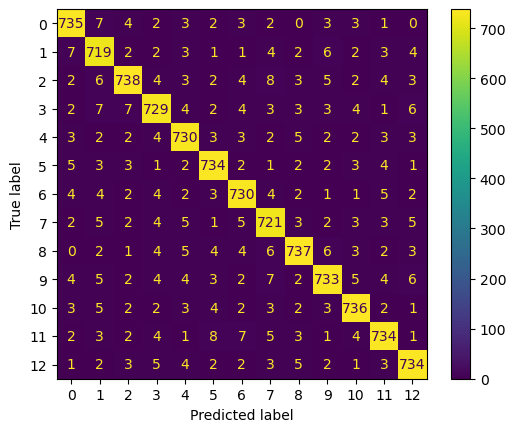

In [64]:
from sklearn.metrics import confusion_matrix, accuracy_score,mean_absolute_error, ConfusionMatrixDisplay
from scipy.optimize import linear_sum_assignment

def align_labels(y_true, y_pred):
    # 1. Créer la matrice de confusion
    cm = confusion_matrix(y_true, y_pred)
    # 2. Trouver l'assignation optimale pour maximiser la correspondance
    # On transforme le problème en minimisation du coût (négatif de la CM)
    row_ind, col_ind = linear_sum_assignment(-cm)
    
    # 3. Créer un dictionnaire de mapping
    mapping = {old_label: new_label for old_label, new_label in zip(col_ind, row_ind)}
    
    # 4. Transformer les labels prédits
    y_pred_aligned = np.array([mapping[label] for label in y_pred])
    return y_pred_aligned

# 1. Récupérer les prédictions du GridSearch
# (Assure-toi que grid_search.fit(X) a bien été exécuté)
y_pred = grid_search.best_estimator_.predict(X)

# 2. Aligner les labels (pour que le cluster 0 du modèle soit le cluster 0 de y)
y_pred_fixed = align_labels(y, y_pred) # On utilise 'y' directement ici

# 3. Calculer la précision
acc_score = accuracy_score(y, y_pred_fixed)
confusion_matrix = confusion_matrix(y,y_pred_fixed)
ConfusionMatrixDisplay(confusion_matrix=confusion_matrix).plot()


print(f"Précision (Accuracy) : {acc_score * 100:.2f}%")

C'est très bien... On a réaligné les labels comme il fallait, et nos clusters sont bons à 95%. Pourquoi 95% ? C'est car on a 5% de bruit créé par flipy. La confusion matrix nous montre bien que ce n'est pas un problème de cluster mal formé comme vous pouvez le voir. Les erreurs sont réparties gaussiennement. 

Vous comprenez donc que la PCA garde la forme de cluster, elle peut donc être utilisée pour savoir si on peut faire du clustering ou pas. Bien sûr, dans la vraie vie c'est un peu plus compliqué. En attendant, voici les réponses qu'il fallait obtenir dans ce TD bonus:

In [65]:
print(N_INFORMATIVE)
print(N_REDUNDANT)
print(N_REPEATED)
print(N_CLASSES) 

37
11
2
13


On avait déjà un peu tout deviné...

Revenons maintenant à notre problème d'utilisation de l'ACP en compagnie de nouvelles variables. Notre but va être d'analyser les nouveaux points. Comme cela fait longtemps, je vous rappelle le code, et j'ajoute par la même occasion les flèches des vecteurs propres (je préfère cette représentation personnellement à celle fournie par fanalysis):

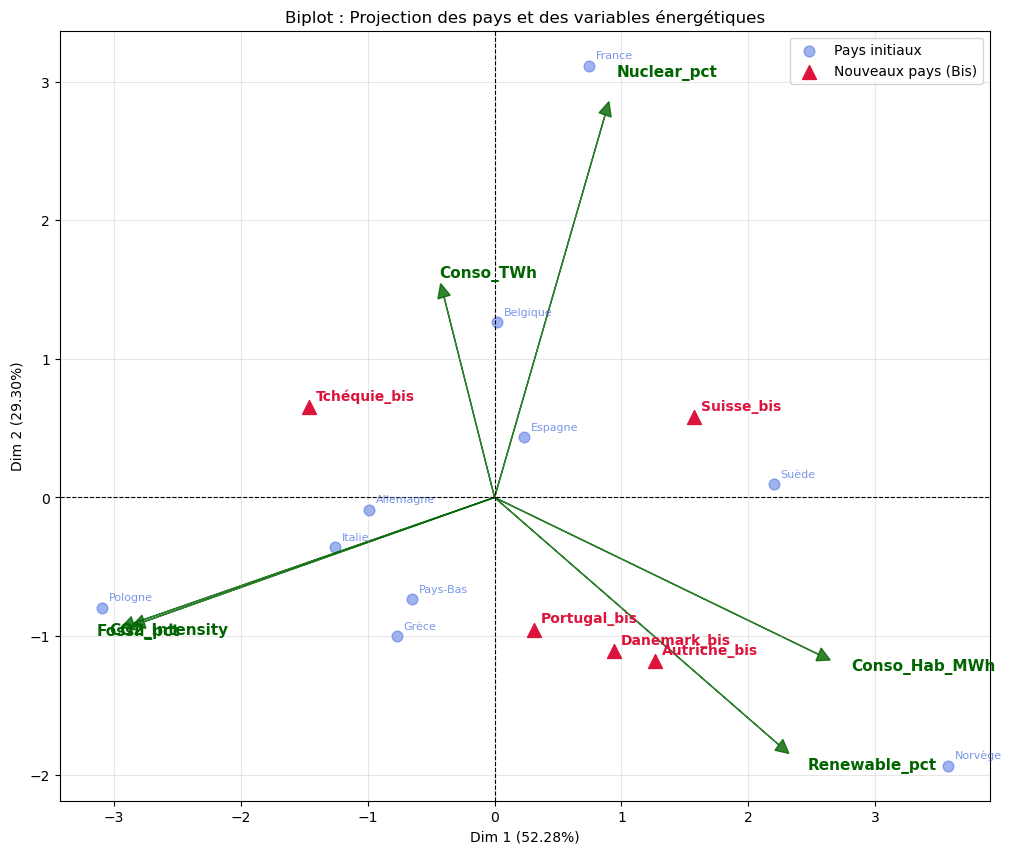

In [90]:
plt.figure(figsize=(12, 10))

# 1. Affichage des anciens pays (Bleu)
plt.scatter(apc.row_coord_[:, 0], apc.row_coord_[:, 1], 
            color='royalblue', alpha=0.5, label='Pays initiaux', s=60)
for i, txt in enumerate(data.index):
    plt.annotate(txt, (apc.row_coord_[i, 0], apc.row_coord_[i, 1]), 
                 xytext=(5,5), textcoords='offset points', fontsize=8, color='royalblue', alpha=0.7)

# 2. Affichage des nouveaux pays (Rouge)
plt.scatter(scores_bis[:, 0], scores_bis[:, 1], 
            color='crimson', marker='^', s=100, label='Nouveaux pays (Bis)', zorder=5)
for i, txt in enumerate(data_bis.index):
    plt.annotate(txt, (scores_bis[i, 0], scores_bis[i, 1]), 
                 xytext=(5,5), textcoords='offset points', fontsize=10, weight='bold', color='crimson')

# 3. AJOUT DES FLÈCHES (Variables / Colonnes)
# On récupère les coordonnées des colonnes
vep = apc.col_coord_ 

# Facteur d'échelle pour ajuster la taille des flèches à la dispersion des points
# Tu peux ajuster ce chiffre (ex: 3, 5, ou 10) selon ton rendu
scaling_factor = 3

for i, var_name in enumerate(data.columns):
    x, y = vep[i, 0] * scaling_factor, vep[i, 1] * scaling_factor
    # Dessin de la flèche
    plt.arrow(0, 0, x, y, color='darkgreen', alpha=0.8, head_width=0.1, head_length=0.1)
    # Nom de la variable
    plt.text(x * 1.1, y * 1.1, var_name, color='darkgreen', fontdict={'weight': 'bold', 'size': 11})

# Esthétique du graphique
plt.axhline(0, color='black', linestyle='--', linewidth=0.8)
plt.axvline(0, color='black', linestyle='--', linewidth=0.8)
plt.xlabel(f"Dim 1 ({apc.eig_[1][0]:.2f}%)")
plt.ylabel(f"Dim 2 ({apc.eig_[1][1]:.2f}%)")
plt.title("Biplot : Projection des pays et des variables énergétiques")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Vous pouvez bien évidemment calculer le co2 des lignes. Attention néanmoins, en ajoutant des nouveaux points, l'hypothèse de la somme des corrélations carrés  en ligne fait toujours 1, mais la somme en ligne, ne fait plus la variance totale.  

In [100]:
# 1. Calcul de la distance totale au carré (Inertie totale de l'individu)
# On utilise les données "bis" centrées et réduites selon les paramètres de l'ACP
data_bis_scaled = (data_bis - data.mean()) / data.std()
dist_totale_bis = np.sum(data_bis_scaled**2, axis=1)

# 2. Calcul du cos2
# scores_bis[:, 0] est la coordonnée sur l'axe 1, scores_bis[:, 1] sur l'axe 2, etc.
cos2_bis = scores_bis**2 / dist_totale_bis.to_numpy()[:, np.newaxis]

# 3. Organisation en DataFrame pour plus de clarté
df_cos2 = pd.DataFrame(
    cos2_bis, 
    index=data_bis.index, 
    columns=[f"Cos2_Dim_{i+1}" for i in range(scores_bis.shape[1])]
)

# On peut aussi calculer la qualité de représentation sur le PLAN (Dim 1 + Dim 2)
df_cos2['Qualité_Plan_1_2'] = df_cos2['Cos2_Dim_1'] + df_cos2['Cos2_Dim_2']

display(df_cos2.sort_values(ascending=False, by="Qualité_Plan_1_2").tail().round(2))

,Cos2_Dim_1,Cos2_Dim_2,Cos2_Dim_3,Cos2_Dim_4,Cos2_Dim_5,Cos2_Dim_6,Qualité_Plan_1_2
Pays,,,,,,,
Autriche_bis,0.45,0.39,0.05,0.36,0.02,0.0,0.84
Suisse_bis,0.74,0.10,0.40,0.17,0.07,0.0,0.84
Danemark_bis,0.26,0.36,0.16,0.51,0.01,0.0,0.62
Tchéquie_bis,0.51,0.10,0.53,0.20,0.01,0.0,0.61
Portugal_bis,0.04,0.38,0.24,0.59,0.00,0.0,0.42


La seule variable pas très bien représentée dans le plan composé des axes factoriels 1 et 2 est celui du Portugal. Cette matrice de cos2 montre de surcroît les axes les plus importants pour nos analyses de chaque point. N'analysez donc pas le Portugal en fonction de l'axe n°1, cela n'aurait que peu de sens.  

Je n'en ai pas trop parlé, mais le cosinus entre une variable et un individu permet de montrer l'importance de la relation entre l'individu et la variable. Sa formule est la suivante:

$$\cos(\theta) = \frac{\mathbf{v}_{ind} \cdot \mathbf{v}_{var}}{\|\mathbf{v}_{ind}\| \times \|\mathbf{v}_{var}\|}$$

Cela permet de faire des analyses complémentaires: la Suisse, très corrélée avec l'axe n°1, qui est lui même composé, en termes de contributions, des énergies fossiles, de la consommation par habitant et des énergies renouvelables. 

Mais, la Suisse est-elle un pays pollueur ou alors un pays qui consomme beaucoup et utilise les énergies renouvelables ? 

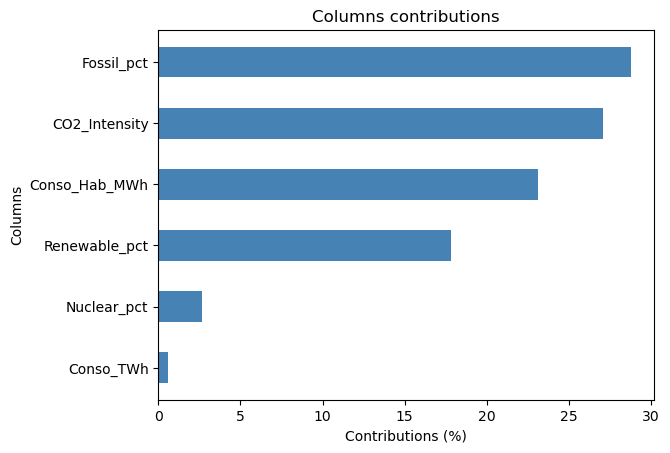

In [106]:
apc.plot_col_contrib(num_axis=1)

In [107]:
import numpy as np
import pandas as pd

# 1. Sélection des coordonnées sur les 2 premières dimensions (le plan du graphique)
coords_individus = scores_bis[:, :2]
coords_variables = apc.col_coord_[:, :2]

# 2. Normalisation des vecteurs (pour que le produit scalaire donne le cosinus)
# Norme des individus (L2 norm)
norm_ind = np.linalg.norm(coords_individus, axis=1, keepdims=True)
# Norme des variables
norm_var = np.linalg.norm(coords_variables, axis=1, keepdims=True)

# 3. Calcul de la matrice des cosinus
# On divise par les normes pour obtenir des valeurs entre -1 et 1
cosinus_matrix = (coords_individus @ coords_variables.T) / (norm_ind @ norm_var.T)

# 4. Création d'un DataFrame lisible
df_cosinus_bis = pd.DataFrame(
    cosinus_matrix, 
    index=data_bis.index, 
    columns=data.columns
)

print("Matrice des cosinus (Corrélations sur le plan Dim 1 & 2) :")
display(df_cosinus_bis.round(3))

Matrice des cosinus (Corrélations sur le plan Dim 1 & 2) :


,Conso_TWh,Conso_Hab_MWh,Renewable_pct,Nuclear_pct,Fossil_pct,CO2_Intensity
Pays,,,,,,
Danemark_bis,-0.906,0.901,0.981,-0.531,-0.386,-0.381
Suisse_bis,0.086,0.717,0.517,0.613,-0.999,-0.999
Autriche_bis,-0.853,0.944,0.997,-0.432,-0.488,-0.483
Portugal_bis,-0.999,0.670,0.836,-0.812,-0.008,-0.003
Tchéquie_bis,0.634,-1.000,-0.968,0.112,0.748,0.744


La suisse est donc un pays "mixte", elle utilise à la fois les énergies renouveables et le nucléaire, mais elle n'utilise pas du tout les énergies fossiles et essaie de polluer le moins possible par conséquent. 

In [108]:
data_bis

,Conso_TWh,Conso_Hab_MWh,Renewable_pct,Nuclear_pct,Fossil_pct,CO2_intensity
Pays,,,,,,
Danemark_bis,35.0,6.0,75.0,0.0,25.0,80
Suisse_bis,60.0,6.8,60.0,35.0,5.0,25
Autriche_bis,70.0,7.8,80.0,0.0,20.0,90
Portugal_bis,50.0,4.9,65.0,0.0,35.0,120
Tchéquie_bis,65.0,6.1,15.0,35.0,50.0,420


Le tableau confirme notre analyse. 

# Pour en savoir encore plus sur l'analyse en composantes principales

Notez que la plupart des techniques que l'on a vu et que l'on verra sont similaires à d'autres méthodes factorielles. (comme par exemple, l'ACM (Analyse en Composantes Multiples). 

Nous allons maintenant nous interesser aux problèmes inhérents aux axes. Je vous avais dit plus haut que parfois, nous pouvons avoir tous les points qui sont à peu près corrélés avec le premier axe, puis moins sur le second, puis quaisment plus du tout sur le troisième. Cela a pour conséquence de rendre l'analyse exploratoire très peu compréhensible. Bien que la variance globale soit gardée, PCA peut avoir cette fâcheuse tendance de maximiser le premier axe, puis ensuite de maximiser le restant de variance non expliquée (résidus), sur le second axe, et ce de manière orhtogonale au premier et ainsi de suite. 

L'idée d'une rotation devient alors pertinente puisqu'elle permet: de faire une rotation du plan dans lequel on analyse les variables, permettant ainsi de voir les points (qui eux ne changent pas de caractéristiques intrinsèques, nous procéderons juste à un transfert de base) sous une nouvelle "lunette". Ainsi, nous favoriserons l'analyse des points non plus sur une seule dimension "saturée" mais sur plusieurs dimensions à la fois !

Pour cela, deux grandes familles existent: les familles de rotations orthogonales (aussi appelées rotations "Orthomax"), ainsi que les rotations obliques. Les premières conservent le caractère orthogonal des axes tandis que les secondes ne respectent plus ce critère. 

En pratique, beaucoup de datascientists er de data engineer considèrent que violer l'hypothèse d'orthogonalité peut être vecteur de fausses interprétations. Néanmoins, malgr éleurs défauts, il est important de les connaître pour se forger son propre avis dessus en expérimentant.

## 1. La famille des rotations Orthomax.

Notez qu'on omet souvent de dire que les rotations Varimax, Equamax ou encore Quartimax font parties d'un seul et même algorithme, d'une seule et même idée autour des rotations d'axes gardant leur caractère orthogonal. 

Pourquoi vouloir garder l'orthogonalité ? Eh bien matplotlib représente des points de manière graphique. Néanmoins, il essaie de faire des représentations graphiques correspondant à des standards bien précis : l'idée d'un graphique ou les deux axes considérés forment un angle droit en leur origine du repère. Si votre repère est orthonormée, votre analyse n'en sera que plus difficile visuellement, voire même complètement impossible ! De même, le cerveau humain est souvent amené à penser en termes d'orthonormie, c'est-à-dire avec des "ticks" qui vont de 1 en 1. Concrètement, cela signifie que l'on veut que nos vecteurs, une fois le changement de base effectués, gardent une norme (distance) de 1. Sinon, cela rend tout plus compliqué. Si l'échelle de représentation du premier axe est différente de celle du second axe, vous pourriez arriver à des erreurs d'interprétation au niveau des distances euclidiennes. Imaginons un axe 1 où les distances vont de 10 en 10 alors que le second ne va que de 1 en 1. Une échelle de représentation comme ceci pourrait vous amener à croire à des égalités de distances (1 tick en plus). Cependant, 1 tick en plus correspond à 10 unités supplémentaires sur l'axe 1 quand sur l'axe n°1, il ne correspond qu'à 1 unité supplémentaire. Faites donc attention à cela. 

### 1.1 Structuration du problème

Notions $a_{ij}$ la case de coordonnée (i,j) dans notre array renvoyé par l'ACP, c'est-à-dire en d'autres termes, les coordonnées obtenues après transformations pour chaque groupe d'individu. (On les appelera les loadings, ou chargement en français.)

Les loadings, comme nous l'avons déjà vu, ce sont, dans le cas d'une ACP normée, le coefficient de corrélation pour chaque individu i en fonction de l'axe factoriel j considéré. (cf. Les heatmaps antérieures.) Ces loadings varient donc entre -1 et 1. Seulement, dans le cas d'une optimisation, il sera compliqué de sommer chaque loadings séparéments..., puisqu'ils vont finir par se simplifier. Une première idée serait de les passer à la valeur absolue et considérer: $|\lambda_{i,j}|$. 

Toutefois, la fonction valeur absolue à plusieurs difficultés: elle n'est pas dérivable en tout point de son ensemble de dérivation, elle a un problème notamment en 0. Si l'on voudra ensuite utiliser nos algorithmes de maximisation, nous pourrons avoir un petit problème de dérivation potentiel en certains points. De même, nous voulons maximiser par la suite des variances entre loadings, le carré a pour intérêt primaire d'accentuer les gros écarts et de réduire les petits écarts. Par exemple, si je grossie le trait en prenant une puissance 4: 

- Avec $|x|$ : Le rapport de force est de $0.8 / 0.2 = \mathbf{4}$.
- Avec $x^4$ : Le rapport devient $0.8^4 / 0.2^4 = 0.4096 / 0.0016 = \mathbf{256}$.

Nous allons donc considérer par la suite le carré de nos loadings: $\lambda_{i,j}^2$ pour ces raisons. De plus, on a la contrainte suivante, en ne considérant que les k facteurs les plus importants:

$$\sum_{j=1}^{k}{\lambda_{i,j}} = h_{j}^2 < 1$$

Calculons, maintenant qu'on a reposé le cadre, la variance $V_j$ des colonnes faîtes par PCA (c'est-a-dire la variance des loadings en réalité en fonction de l'axe considéré):
$$$V_j = \frac{1}{p} \sum_{i=1}^{k} (\lambda_{ij}^2 - \bar{\lambda}_j^2)^2 $$

Développons cette expression (propriété classique de la variance $E[X^2] - (E[X])^2$) (Koenig-Huygens) :

$$V_j = \frac{1}{p} \sum_{i=1}^{p} \lambda_{ij}^4 - \frac{1}{p^2} \left( \sum_{i=1}^{p} \lambda_{ij}^2 \right)^2$$


En sommant, à $\gamma$ près ces variables sur les k axes factoriels considérés, on trouve: 

$$Q = \sum_{j=1}^{k} \left[ \underbrace{\sum_{i=1}^{p} \lambda_{ij}^4}_{\text{Partie A}} - \mathbf{\frac{\gamma}{p}} \underbrace{\left( \sum_{i=1}^{p} \lambda_{ij}^2 \right)^2}_{\text{Partie B}} \right]$$

A $\gamma$ petit, on cherche donc à intensifier le moment d'ordre 4 des loadings. Cependant, on ne punit pas sévèrement un axe s'il est déjà trop surchargé. Le but est donc que chaque variable du dataset originale trouve un axe factoriel adéquat, dans lequel il trouvera sa représentativité maximisée (en dépit des autres) C'est la rotation appellée Quartimax (lorsque $\gamma$ = 0)

À l'inverse, lorsque $\gamma$ tend vers 1, la Partie B prend une importance capitale. Ce terme agit comme une force de régularisation : il vient soustraire à la qualité globale le carré de l'inertie de chaque axe. Mathématiquement, on pénalise les solutions où un seul « super-axe » capte l'essentiel des chargements au détriment des autres. L'algorithme est alors contraint de redistribuer les loadings de manière plus équitable entre les $k$ facteurs. Cette approche, appelée Varimax (lorsque $\gamma = 1$), ne cherche plus seulement à satisfaire chaque variable individuellement, mais à simplifier la structure des colonnes (les axes).

En maximisant la variance interne de chaque axe, la Varimax garantit que chaque dimension politique de ton audit possède une identité thématique propre et discriminante. C'est le réglage privilégié en sciences sociales, car il facilite le "nommage" des axes : un axe sera soit très corrélé à une variable, soit pas du tout, évitant ainsi les facteurs "fourre-tout" qui apparaissent souvent dans les ACP non tournées.

L'entre-deux est appelée rotation Biquartimax, puisqu'elle fait un compromis entre les deux grâce à son $\gamma = \frac{1}{2} = 0.5$. 

# Guide Stratégique : Choisir entre Varimax et Quartimax

Dans le cadre d'un audit (politique, marketing ou social), le choix entre ces deux rotations dépend de la structure réelle que l'on cherche à mettre en lumière. Voici quand privilégier l'une ou l'autre.

---

## 1. La Rotation Varimax ($\gamma = 1$)
### *Quand la réalité est multidimensionnelle*

La **Varimax** est la rotation la plus utilisée car elle cherche à simplifier les **colonnes** (les axes factoriels). Elle fait en sorte que chaque axe soit porté par un petit groupe de variables spécifiques.

**Il est préférable d'utiliser Varimax quand :**
* **L'objectif est de nommer les axes :** Vous voulez pouvoir dire "L'axe 1 est l'axe de l'économie", "L'axe 2 est l'axe des valeurs morales".
* **Les thématiques sont indépendantes :** Vous supposez que les candidats/individus peuvent être jugés sur des critères différents qui ne se recoupent pas forcément.
* **Vous voulez éviter un "super-axe" :** Varimax redistribue l'inertie pour éviter qu'un premier facteur ne vienne masquer les nuances des suivants.

**Exemple d'audit :** Identifier les différents profils d'électeurs (les "écologistes", les "souverainistes", les "libéraux") comme des groupes distincts.



---

## 2. La Rotation Quartimax ($\gamma = 0$)
### *Quand la réalité est polarisée par un facteur dominant*

La **Quartimax** simplifie les **lignes** (les variables). Elle cherche à ce que chaque variable soit rattachée le plus fortement possible à un axe, peu importe si c'est le même pour tout le monde.

**Il est préférable d'utiliser Quartimax quand :**
* **Vous cherchez un "Facteur Général" (G-Factor) :** Vous suspectez qu'une seule grande dimension explique la majorité des comportements (ex: le clivage Droite/Gauche ou Pour/Contre).
* **L'objectif est de classer les candidats :** Vous voulez simplement savoir quel est le "port d'attache" principal de chaque candidat, même si 90% des candidats se retrouvent sur le même axe.
* **La structure est simple et massive :** Si les données sont naturellement très corrélées entre elles, Quartimax respectera cette unité là où Varimax essaierait de la fragmenter artificiellement.

**Exemple d'audit :** Analyser une élection de type référendaire où la seule question qui compte est le soutien ou l'opposition au gouvernement en place.



---

## 3. Synthèse de décision

| Situation | Choix recommandé | Pourquoi ? |
| :--- | :--- | :--- |
| **Audit Exploratoire** | **Varimax** | C'est le réglage le plus "neutre" pour découvrir des thèmes cachés. |
| **Audit de Confirmation** | **Quartimax** | Pour valider si un clivage unique domine réellement tout le débat. |
| **Identification de niches** | **Varimax** | Pour faire ressortir de petits groupes de variables très cohérents sur des axes secondaires. |
| **Simplicité maximale** | **Quartimax** | Pour que chaque variable n'ait qu'une seule grosse corrélation (loading). |

---

## Conclusion pour l'analyste

* Choisissez **Varimax** pour la **nuance** et la découverte de thématiques spécialisées.
* Choisissez **Quartimax** pour la **puissance** et la mise en évidence d'une polarisation globale.
  
Dans le cas d'un clustering, je vous conseille donc de privilégier une Varimax, qui aura tendance à apporter une aide aux axes factoriels pour qu'ils puissent mieux discerner les "délimitations" entre clusters.

# Optimisation de la Rotation : Du Critère Q à l'Angle $\theta$

Pour passer de la théorie à la pratique, nous devons transformer la maximisation de $Q$ en un problème de géométrie analytique.

## 1. Le Problème d'Optimisation sous Contrainte

Nous cherchons la matrice de chargements rotatés $\Lambda^*$ qui maximise $Q$. La contrainte fondamentale est que la rotation doit être **orthogonale** : nous voulons changer de perspective sans déformer l'espace ni changer l'information initiale.

**Le problème s'énonce ainsi :**
$$\text{Maximiser } Q(\Lambda^*) \text{ sous la contrainte } T^T T = I$$
où $\Lambda^* = \Lambda T$.

## 2. La Rotation Élémentaire (Paire d'axes)

L'optimisation globale étant complexe, on utilise la méthode de **Kaiser** : on fait tourner les axes deux par deux. Considérons deux axes $j$ et $l$. Pour tout angle $\theta$, les nouveaux chargements $\lambda^*$ sont donnés par la matrice de rotation plane :

$$
\begin{pmatrix} \lambda_{ij}^* \\ \lambda_{il}^* \end{pmatrix} = 
\begin{pmatrix} \cos \theta & \sin \theta \\ -\sin \theta & \cos \theta \end{pmatrix} 
\begin{pmatrix} \lambda_{ij} \\ \lambda_{il} \end{pmatrix}
$$



## 3. Dérivation de l'Angle Optimal

Pour trouver l'angle $\theta$ qui maximise $Q$, nous devons annuler la dérivée de la fonction par rapport à $\theta$.

Soit $f(\theta) = Q(\Lambda^*)$. En injectant les formules de rotation trigonométriques dans l'expression de $Q$ (pour $\gamma=1$, Varimax), on obtient une fonction de la forme :
$$f(\theta) = A + B \cos(4\theta) + C \sin(4\theta)$$

Pour maximiser cette fonction, on cherche $\frac{df}{d\theta} = 0$. Après développement des puissances quatrièmes, on aboutit à la solution classique de Kaiser :

$$\tan(4\theta) = \frac{D}{N}$$

Où :
* **$D$ (Dénominateur)** : lié à la covariance entre les carrés des loadings des deux axes.
* **$N$ (Numérateur)** : lié à la différence de variance entre les deux axes.

### Pourquoi $4\theta$ ?
Le facteur **4** est crucial. Il provient de l'utilisation de la puissance 4 dans ta formule $Q$. Géométriquement, cela signifie que la fonction de qualité possède une périodicité de $90^\circ$ ($\pi/2$). Il y a 4 positions "optimales" (les axes pointant vers le haut, le bas, la gauche ou la droite) qui sont mathématiquement équivalentes pour la variance.



## 4. Synthèse du processus itératif

Puisque la solution pour une paire d'axes dépend des autres, on utilise un algorithme itératif :

1.  **Initialisation** : On part de la matrice $\Lambda$ issue de l'ACP.
2.  **Rotation plane** : Pour chaque paire d'axes $(j, l)$, on calcule l'angle $\theta$ optimal via l'arctangente.
3.  **Mise à jour** : On applique la rotation aux axes concernés.
4.  **Convergence** : On répète l'opération sur toutes les paires possibles jusqu'à ce que la variation globale de $Q$ soit inférieure à un seuil $\epsilon$.

---

## Conclusion Mathématique

La maximisation de $Q$ est une **recherche de direction** dans un espace de Hilbert. En minimisant la perte $\mathcal{L} = -Q$, on "force" les vecteurs variables à s'aligner sur les vecteurs de la base (les axes). 

L'angle $\theta$ trouvé est celui qui **polarise** le mieux les données : il réduit l'entropie de la matrice de chargements pour la rendre la plus proche possible d'une matrice binaire (identitaire).

En pratique, je ne vous conseille même pas de vous tenter à calculer des rotations Varimax, Quartimax ou encore Equamax par vous même car vous aurez du mal à aboutir à des algorithmes optimisés. C'est pour cela que je vous conseille d'utiliser le package "factor_analyser". 

In [67]:
from statsmodels.multivariate.factor_rotation import rotate_factors

L,T = rotate_factors(apc.col_coord_,method="varimax")

L représente la matrice des nouveaux loadings après rotation et T est la matrice de rotation orhtogonale obtenue. Pour preuve:

In [68]:
L_v2 = apc.col_coord_ @ T

print(np.allclose(L,L_v2))

True


<Axes: >

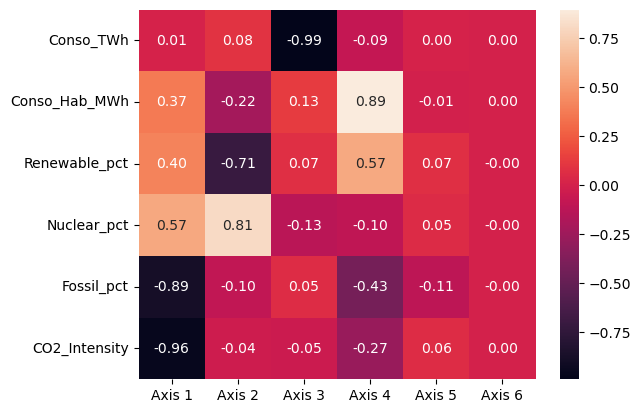

In [69]:
sns.heatmap(L,annot=True,fmt=".2f", yticklabels=data.columns,xticklabels= [f"Axis {k}" for k in range(1,7)])

<Axes: >

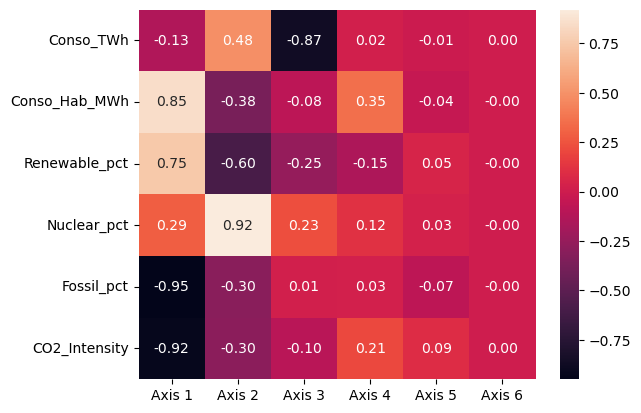

In [70]:
sns.heatmap(apc.col_coord_,annot=True,fmt=".2f", yticklabels=data.columns,xticklabels= [f"Axis {k}" for k in range(1,7)])

Bon, ici le résultat n'est pas flagrant puisque nous avions déjà des axes plutôt bien équilibrés. Néanmoins, vous remarquerez que les axes sont bien plus tranchés qu'avant tout de même. Il est possible d'afficher à nouveau le bitplot après rotation quartimax en utilisant la matrice L. Vous pouvez aussi afficher un cercle des corrélations, etc... Néanmoins, cela est assez fastidieux à faire puisque statsmodels n'est pas optimisé pour fonctionner avec scikitlearn. Pour cela, il existe factor_analyzer, mais j'ai l'impressio qu'il n'est plus très à jour depuis quelques années. J'hésite à faire un petit package simple qui permet de faire cela de manière assez aisée. 

Je vous conseille néanmoins de faire vos rotatons sur le peu d'axes que vous avez considérés, et cela lorsque vous avez du mal à analyser quoique ce soit entre les facteurs. Dans une optique de classement des individus selon différentes variables, cela peut être promordiale. 

Pour la rotation Quartimax, il suffit de l'appeler par son nom:

In [71]:
from statsmodels.multivariate.factor_rotation import rotate_factors

L_quartimax,T_quartimax = rotate_factors(apc.col_coord_,method="quartimax")

<Axes: >

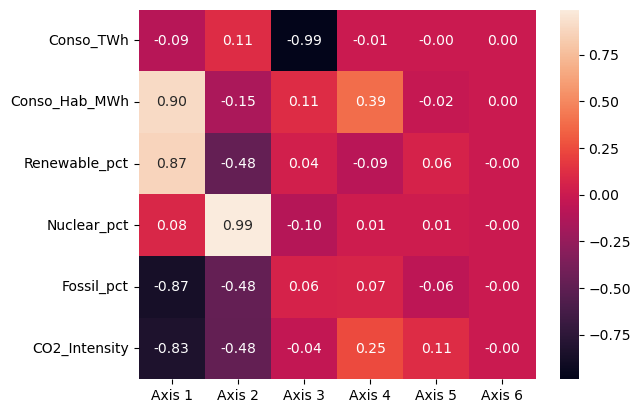

In [72]:
sns.heatmap(L_quartimax,annot=True,fmt=".2f", yticklabels=data.columns,xticklabels= [f"Axis {k}" for k in range(1,7)])

Comme vous pouvez le voir, Quartimax a tendance à beaucoup plus charger les axes qui avaient déjà des corrélations importantes. Au niveau des cosinus carrés:

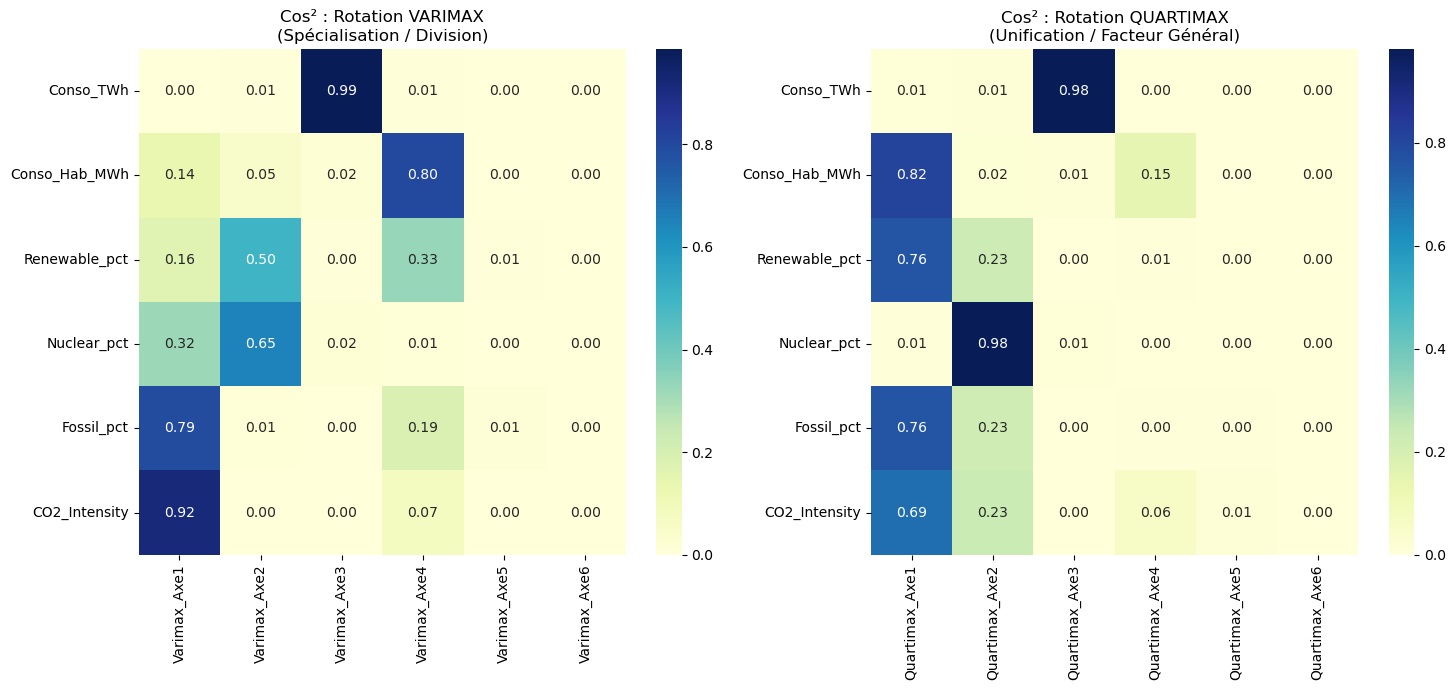

In [73]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.multivariate.factor_rotation import rotate_factors

# 1. On récupère les loadings bruts de fanalysis
# apc.col_coord_ est déjà au format (variables, axes)
L_initial = apc.col_coord_
variables_names = apc.col_labels

# 2. On effectue les deux rotations
# rotate_factors renvoie (Loadings_rotatés, Matrice_de_passage_T)
L_v, T_v = rotate_factors(L_initial, method="varimax")
L_q, T_q = rotate_factors(L_initial, method="quartimax")

# 3. On calcule les Cosinus Carrés (L au carré)
# On crée des noms de colonnes dynamiques selon le nombre d'axes
n_axes = L_initial.shape[1]
cols_v = [f'Varimax_Axe{i+1}' for i in range(n_axes)]
cols_q = [f'Quartimax_Axe{i+1}' for i in range(n_axes)]

df_v = pd.DataFrame(L_v**2, index=variables_names, columns=cols_v)
df_q = pd.DataFrame(L_q**2, index=variables_names, columns=cols_q)

# 4. Affichage des Heatmaps
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 7))

sns.heatmap(df_v, annot=True, cmap='YlGnBu', ax=ax1, cbar=True,fmt=".2f")
ax1.set_title('Cos² : Rotation VARIMAX\n(Spécialisation / Division)', fontsize=12)

sns.heatmap(df_q, annot=True, cmap='YlGnBu', ax=ax2, cbar=True,fmt=".2f")
ax2.set_title('Cos² : Rotation QUARTIMAX\n(Unification / Facteur Général)', fontsize=12)

plt.tight_layout()
plt.show()

La différence se retrouve donc au sein des contributions. Comme je vous l'avais dit, Varimax a tendance à jouer sur les contributions aux différents axes, et Quartimax sur les cos2 au seins de très peu d'axes. 

Quartimax permet donc de valider quels sont les axes les plus "performantes. Ici, il est clair qu'il y a trois axes bien distincts grâce à Quartimax. Varimax nous en apprend plus sur la répartition des différentes variables.

Il y a donc parfois un intérêt permettant d'asseoir la légitimité du nombre d'axes factoriels à garder. 


De même, nous remarquerons qu'on peut analyser ces graphiques et en déduire que: les pays fonctionnant aux énergies renouvelables sont en opposition totales avec les pays fonctionnant aux énergies carbonnés (c'est assez obvious je suis d'accord). Mias là où cest plus intéressant, c'est qu'il semble que l'utilisation des énergies renouvelables induit une consommation par habitant beaucoup plus importante.  D'autre part, les énergies nucléaires sont à part. On remarquera de même que la consommation énergétique semble indépendante du type d'énergie utilisée. 

Grâce à l'utilisation de Varimax, nous pourrons en déduire: Les pays utilisant le plus d'énergie fossile, et donc les pays les plus pollueurs, nous pourrons ensuite aussi analyser les pays qui au contraire ont tendance à utiliser le nucléaire ou les énergies renouvelables. Le choix semble rhédibitoire puisque peu de pays ont l'air d'utiliser les deux en même temps, si on s'en tient aux corrélations !


La suite n'est pas très utile, mais nous allons le faire quand même pour être assez précis dans ce cours. Nous allons le mettre en place sur ce dataset précis, mais ensuite, je vais vous montrer des datasets où l'utilisation de ces rotations serait bien plus utile. 

Ok, comme vous le savez, Orthomax a beaucoup plus de déclinaisons que simplement Varimax ou encore Quartimax. Il y a aussi entre autres: biquartimax ($\gamma = 0.5$), ou encore Equamax ($\gamma = \frac{p}{2}$). Notez que statsmodel pour equamax demande 1/p, il me semble que c'est lié à une manière différente de calculer l'lgorithme Orthomax que celle que nous avons vu. Comme je n'ai pas forcément réponse à cela, je ne préfère pas vous induire en erreur. Retenez seulement que c'est 1/k !

L'idée de Biquartimax est d'offrir un entre deux entre un Varimax qui envoie les données sur un peu tous les facteurs, et un Quartimax qui essaie de condenser au plus. 

Regardez par vous-même :

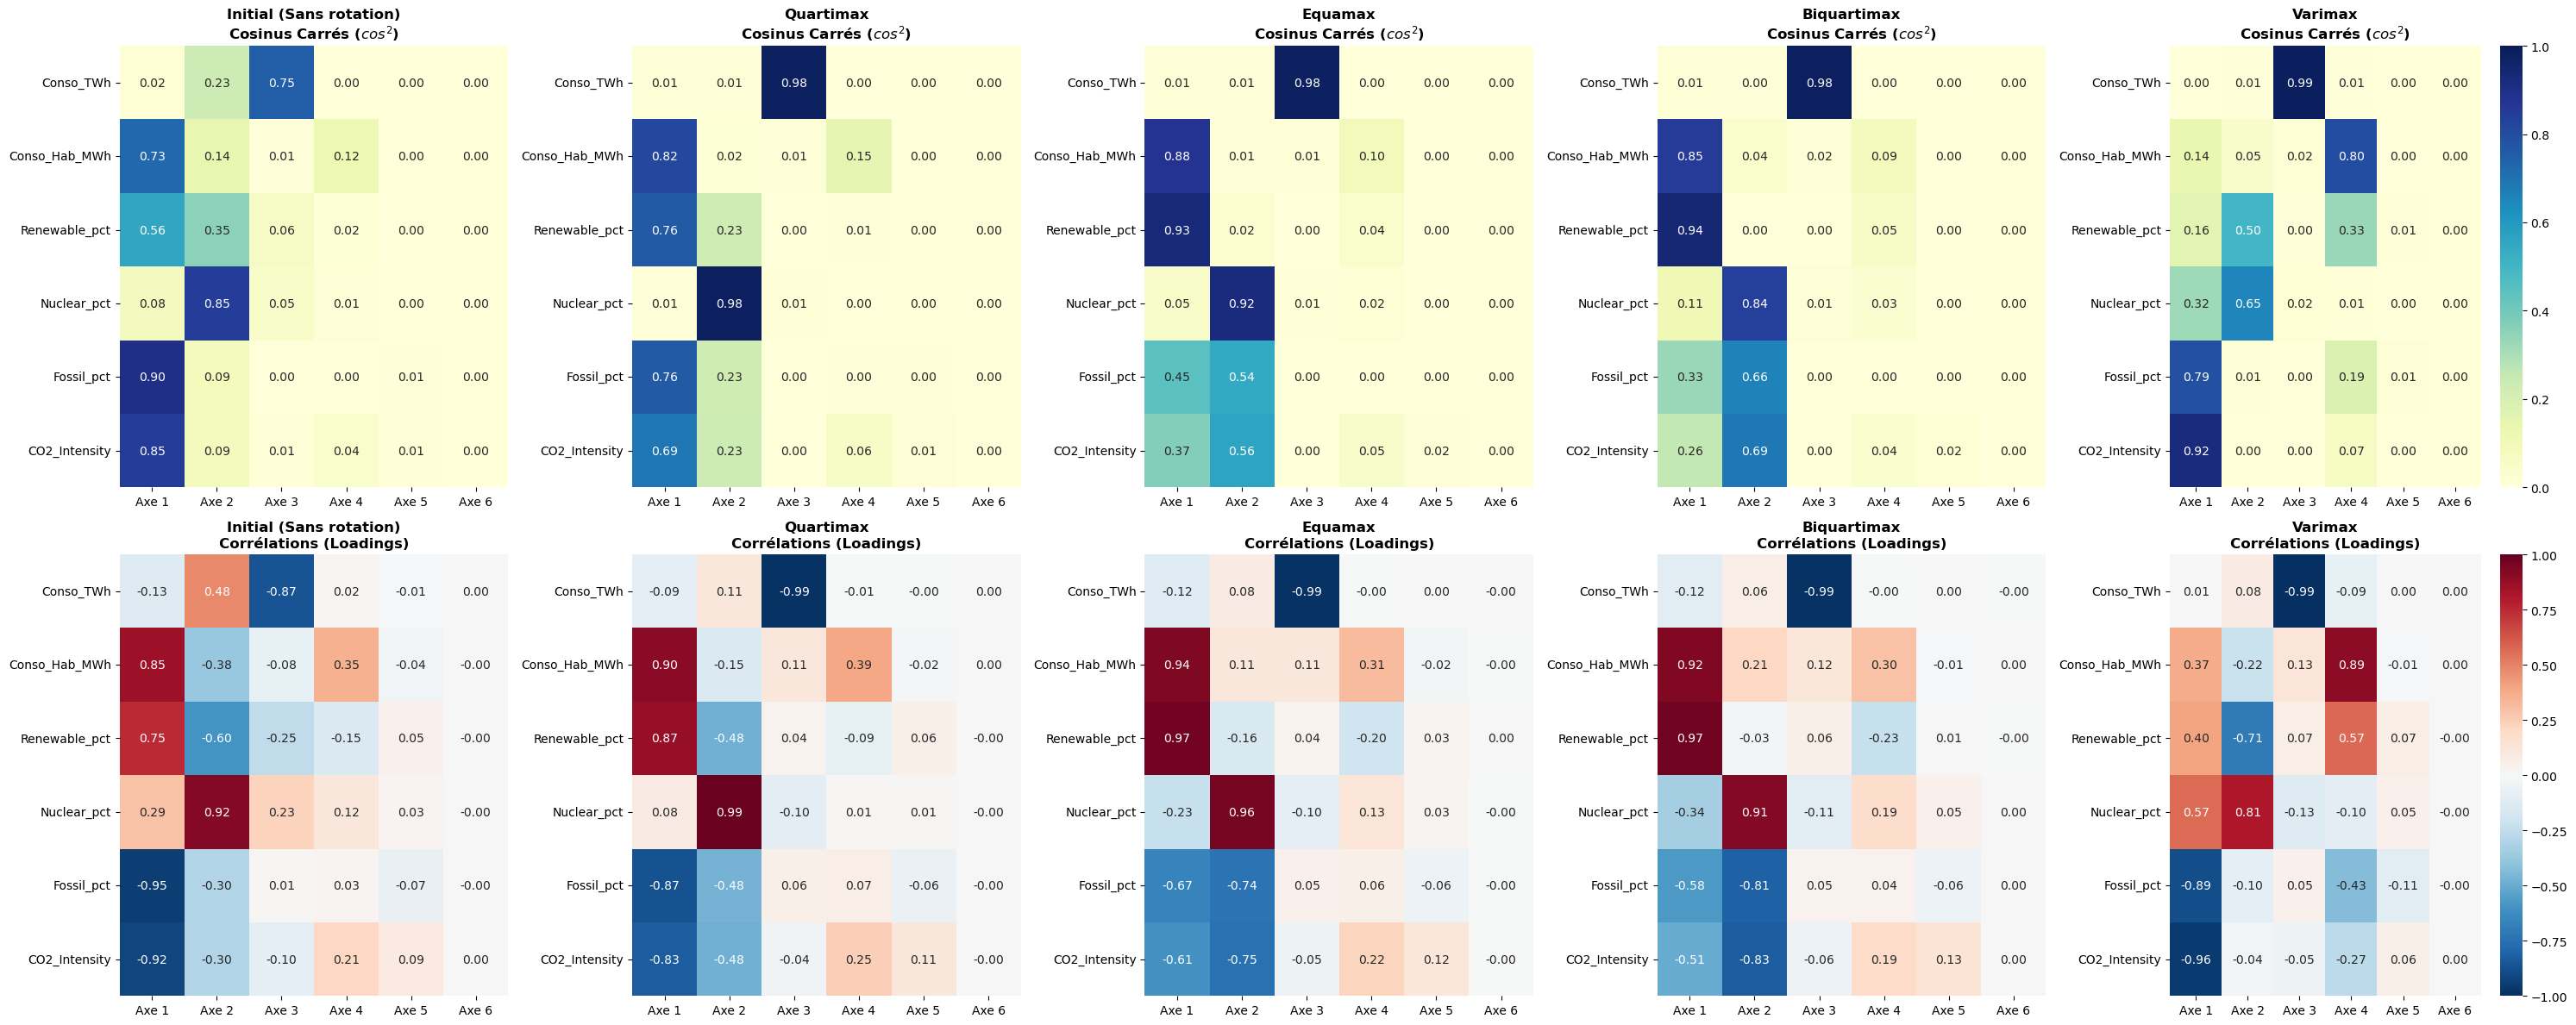

In [74]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.multivariate.factor_rotation import rotate_factors

# 1. Configuration des données
L_initial = apc.col_coord_
variables = apc.col_labels
k = L_initial.shape[1]
axes_names = [f'Axe {i+1}' for i in range(k)]

# 2. Préparation de la figure : 5 colonnes maintenant
fig, axes = plt.subplots(2, 5, figsize=(30, 12))

# Liste des configurations : (Label, Methode_SM, Gamma_ou_None)
# 'None' pour le second élément signifie "Pas de rotation"
configs = [
    ("Initial (Sans rotation)", None, None),
    ("Quartimax", "quartimax", None),
    ("Equamax", "orthomax", 1/k),
    ("Biquartimax", "orthomax", 0.5),
    ("Varimax", "varimax", None)
]

for i, (name, sm_method, gamma) in enumerate(configs):
    # --- Logique d'appel ---
    if sm_method is None:
        # Cas de l'ACP de base
        L_rot = L_initial
    elif gamma is not None:
        # Pour orthomax (Equamax, Biquartimax)
        L_rot, T = rotate_factors(L_initial, sm_method, gamma)
    else:
        # Pour varimax et quartimax
        L_rot, T = rotate_factors(L_initial, sm_method)
    
    # --- Affichage Matrice 1 : Cos² ---
    df_cos2 = pd.DataFrame(L_rot**2, index=variables, columns=axes_names)
    sns.heatmap(df_cos2, annot=True, cmap='YlGnBu', ax=axes[0, i], cbar=(i==4), vmin=0, vmax=1, fmt=".2f")
    axes[0, i].set_title(f'{name}\nCosinus Carrés ($cos^2$)', fontweight='bold')

    # --- Affichage Matrice 2 : Loadings ---
    df_load = pd.DataFrame(L_rot, index=variables, columns=axes_names)
    sns.heatmap(df_load, annot=True, cmap='RdBu_r', ax=axes[1, i], center=0, cbar=(i==4), vmin=-1, vmax=1, fmt=".2f")
    axes[1, i].set_title(f'{name}\nCorrélations (Loadings)', fontweight='bold')

plt.tight_layout()
plt.show()

La, je vous propose du grand art !

### Récapitulatif des Stratégies de Rotation (Famille Orthomax)

| Méthode | Paramètre Gamma | Objectif de la structure | Comportement observé | Usage pour l'audit |
| :--- | :---: | :--- | :--- | :--- |
| **Initial** | - | Maximisation de la variance globale. | Variables dispersées (Renewable et Nuclear sur plusieurs axes). | Référence de base (complexité brute). |
| **Quartimax** | 0 | **Unification** : Simplifier les lignes. | Crée un "Super-Axe 1" regroupant Fossile, CO2 et Renouvelable. | Valide le facteur général de puissance du système. |
| **Equamax** | 1/k | **Distribution** : Compromis lignes/colonnes. | Très proche de Quartimax. Isole peu à peu le Nucléaire sur l'Axe 2. | Vision hiérarchisée moins "écrasée" que Quartimax. |
| **Biquartimax** | 0.5 | **Équilibre** : Juste milieu. | Fragmentation de l'Axe 1. La consommation migre vers l'Axe 4. | Identifie les variables qui résistent à la séparation. |
| **Varimax** | 1 | **Spécialisation** : Simplifier les colonnes. | **Contraste maximal**. Chaque variable a un ancrage unique ($cos^2 \approx 1$). | **Choix final** : Idéal pour un clustering sans ambiguïté. |

---

### Analyse des 4 Piliers retenus (Rotation Varimax)

D'après nos graphiques, la rotation Varimax permet de nommer précisément les dimensions de notre analyse:

1.  **Axe 1 (Pollution)** : Concentre `Fossil_pct` et `CO2_Intensity`. C'est l'empreinte carbone.
2.  **Axe 2 (Stratégie Bas-Carbone)** : Isole le `Nuclear_pct` face au `Renewable_pct`.
3.  **Axe 3 (Taille du Pays)** : Dédié uniquement à la consommation totale (`Conso_TWh`).
4.  **Axe 4 (Standard de vie)** : Dédié à la consommation par habitant (`Conso_Hab_MWh`).

Amusez-vous toujours à tester plusieurs combinaisons et à voir laquelle est la meilleure. Comme ceci, vous vous assurez de faire le bon choix, et surtout, vous forgez petit à petit une expertise sur les datasets futurs puisque vous comprenez de mieux en mieux comment les données peuvent s'agréger ensembles. 

Je pourrais vous dire que c'est tout et qu'il n'existe pas d'autre type de rotation, mais ce serait vous mentir ! Dans la famille d'Orthomax, vous pourrez retrouver aussi Parsimax, etc... Je vous ai montrer les principales. (celles prises en compte par statsmodel)



## 2. La famille des rotations oblimin.

L'idée est de minimiser la covariance entre les axes car l'idée ici est que: si on minimise la covariance entre deux axes, cela signifie que deux variables ne peuvent mathématiquement pas se retrouver sur un seul et même axe. En levant l'hypothèse d'orthogonalité, on pourrait avoir des axes qui peuvent passer plus facilement entre les loadings.

Si vous suivez la même logique que Orthomax mais avec la formule de la covariance, vous trouverez sans doute, à $\delta$ près (qui prend le même principe que $\gamma$):

$$f(\Lambda) = \sum_{r < s}^{k} \left( \sum_{i=1}^{p} \lambda_{ir}^2 \lambda_{is}^2 - \frac{\delta}{p} \sum_{i=1}^{p} \lambda_{ir}^2 \sum_{i=1}^{p} \lambda_{is}^2 \right)$$

On obtient alors, selon les valeurs de $\delta$:

- $\delta = 0$ : Quartimin (en référence à Quartimax, mais ici on minimise la covariance)
- $\delta = 0.5$ : Biquartimin (en référence à Biquartimax)
- $\delta = 1$ : Covarimin (en référence à Covarimax)
- Je ne sais pas si Equamin existe, ni même Parsimin, à verifier. (ahahaha)

Néanmoins, ces rotations obliques entrainent des soucis majeurs: la perte de l'orthogonalité. Plus le $\delta$ va vers les négatif (en réalité 0), plus les axes deviennent orthogonaux, plus le $\delta$ va vers 1, plus les axes sont malléables. 

Voyons les difficultés qui sont engendrées par des rotations obliques. La première et pas des moindres, la variance n'est plus linéaire, elle devient:

$$Var_{extraite} = \sum_{j=1}^{k} Var(A_j) - \sum_{r < s} \text{Redondance}(A_r, A_s)$$

En effet, comme les axes sont corrélées, une partie de la corrélation de l'axe 1 existe probablement aussi sur l'axe 2. 

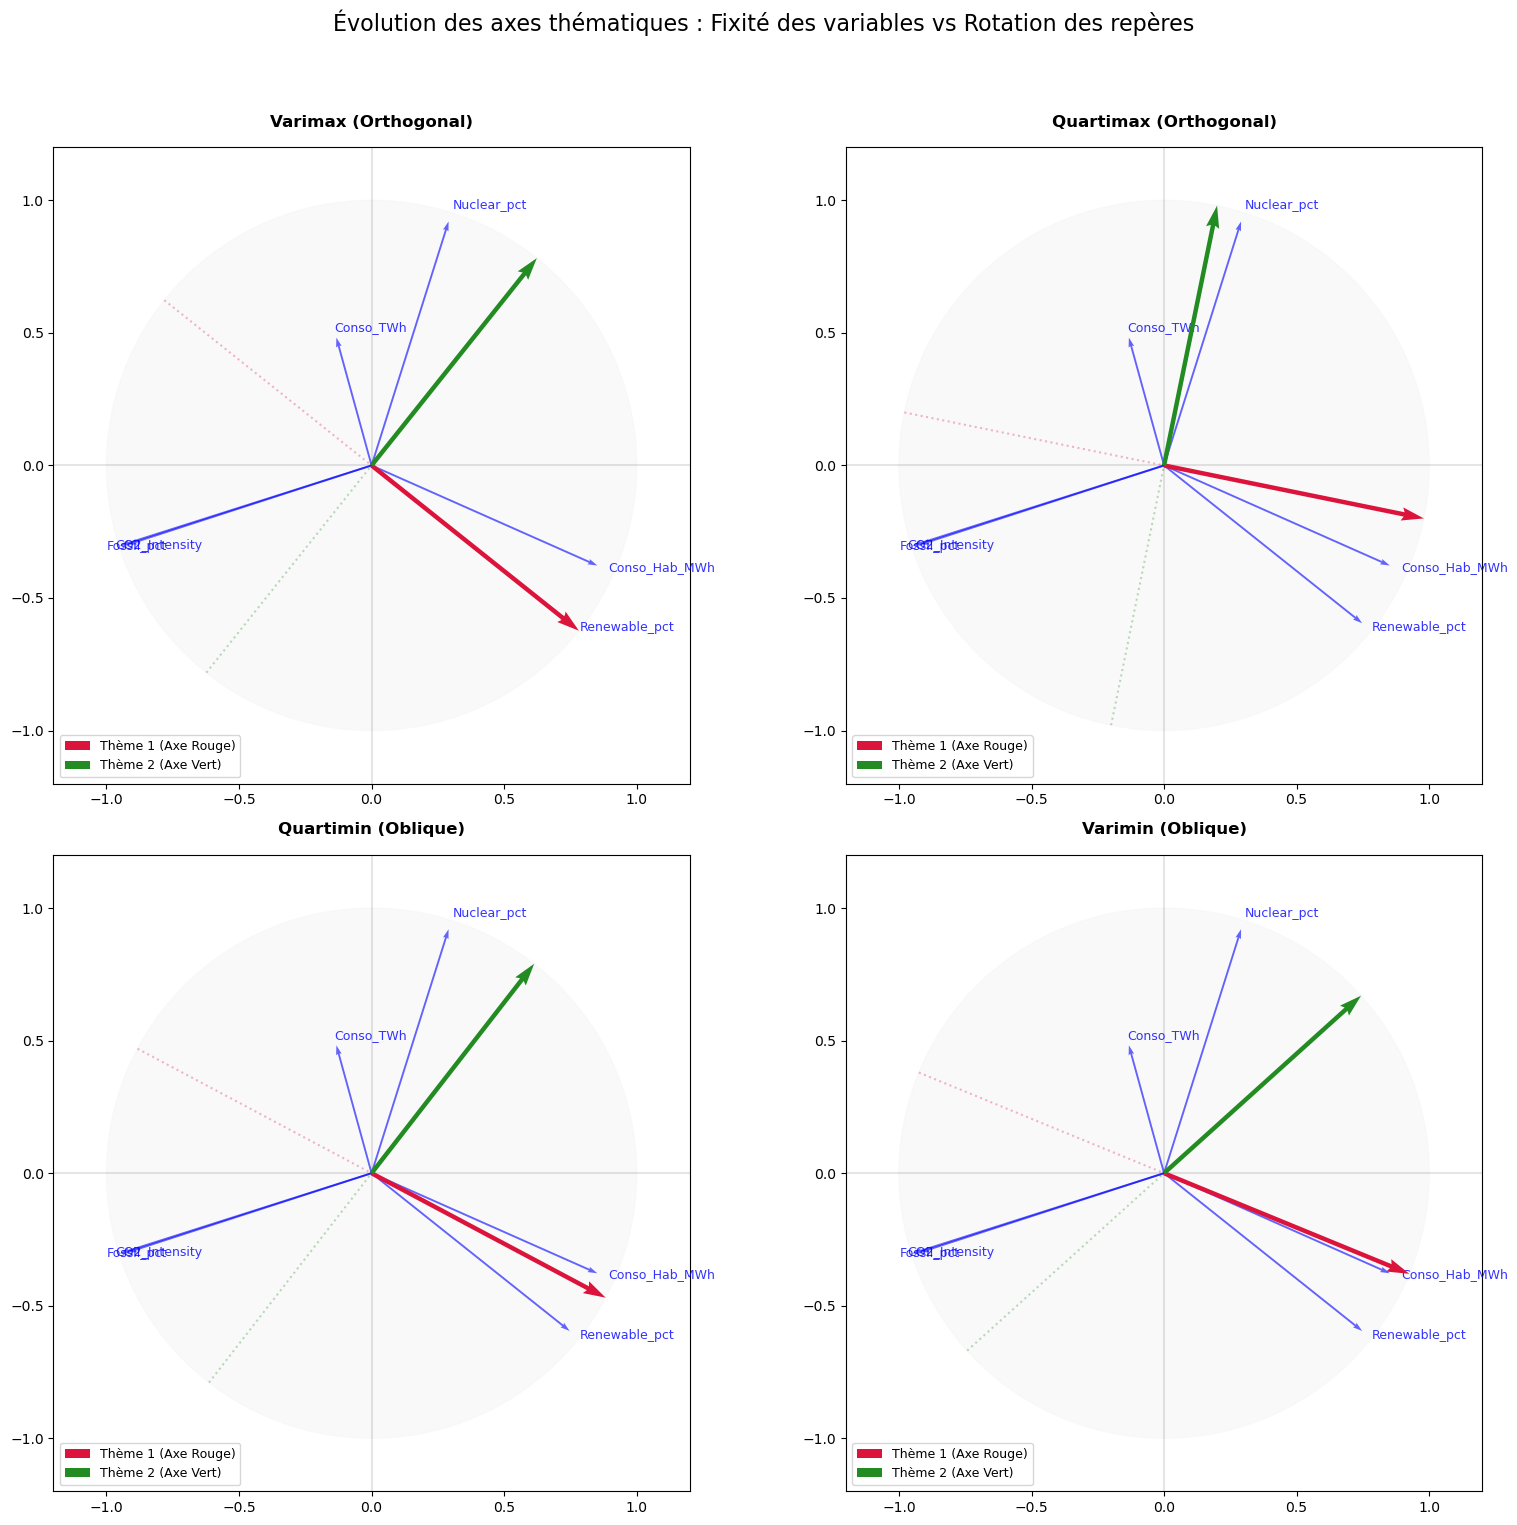

In [75]:
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.multivariate.factor_rotation import rotate_factors

# 1. Extraction des loadings FIXES de fanalysis
L_fixed = apc.col_coord_[:, :2] 
var_names = data.columns

# 2. Définition des rotations (on garde les 4 pour comparer)
rotations = {
    'Varimax (Orthogonal)': {'method': 'varimax'},
    'Quartimax (Orthogonal)': {'method': 'quartimax'},
    'Quartimin (Oblique)': {'method': 'oblimin', 'args': [0.0, 'oblique']},
    'Varimin (Oblique)': {'method': 'oblimin', 'args': [1.0, 'oblique']},
}

fig, axes = plt.subplots(2, 2, figsize=(16, 16))
axes = axes.flatten()

for idx, (rot_name, rot_params) in enumerate(rotations.items()):
    ax = axes[idx]
    
    # Calcul de la rotation
    if 'args' in rot_params:
        P, T = rotate_factors(L_fixed, rot_params['method'], *rot_params['args'])
    else:
        P, T = rotate_factors(L_fixed, rot_params['method'])
    
    # --- DESSIN DU CERCLE ET DES AXES PCA ---
    circle = plt.Circle((0,0), 1, color='whitesmoke', fill=True, alpha=0.5, zorder=0)
    ax.add_artist(circle)
    ax.axhline(0, color='black', alpha=0.1, zorder=1)
    ax.axvline(0, color='black', alpha=0.1, zorder=1)

    # --- LES VARIABLES (FIXES) ---
    for i in range(len(var_names)):
        ax.quiver(0, 0, L_fixed[i, 0], L_fixed[i, 1], color='blue', alpha=0.6, 
                   scale=1, scale_units='xy', angles='xy', width=0.003, zorder=3)
        ax.text(L_fixed[i, 0] * 1.05, L_fixed[i, 1] * 1.05, var_names[i], 
                color='blue', fontsize=9, alpha=0.8, zorder=4)

    # --- LES NOUVEAUX AXES DE L'AUDIT (MOBILES & DISTINCTS) ---
    # Axe 1 en ROUGE
    ax.quiver(0, 0, T[0, 0], T[1, 0], color='crimson', scale=1, scale_units='xy', 
               angles='xy', width=0.007, label='Thème 1 (Axe Rouge)', zorder=5)
    # Axe 2 en VERT
    ax.quiver(0, 0, T[0, 1], T[1, 1], color='forestgreen', scale=1, scale_units='xy', 
               angles='xy', width=0.007, label='Thème 2 (Axe Vert)', zorder=5)
    
    # Ajout d'une ligne d'extension pour voir l'inclinaison complète
    ax.plot([-T[0,0], T[0,0]], [-T[1,0], T[1,0]], color='crimson', linestyle=':', alpha=0.3, zorder=2)
    ax.plot([-T[0,1], T[0,1]], [-T[1,1], T[1,1]], color='forestgreen', linestyle=':', alpha=0.3, zorder=2)

    ax.set_title(rot_name, fontweight='bold', pad=15)
    ax.set_xlim(-1.2, 1.2); ax.set_ylim(-1.2, 1.2)
    ax.set_aspect('equal')
    ax.legend(loc='lower left', fontsize=9)

plt.suptitle("Évolution des axes thématiques : Fixité des variables vs Rotation des repères", fontsize=16)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

Je vous affiche les nouveaux repères en fonction des anciens. J'espère que vous comprenez enfin pourquoi les rotations sont orthogonales ou obliques, et pourquoi on parle de rotations. 

On voit que varimin et quartimin n'offrent plus des axes orthogonaux (l'angle n'est plus à 90°). Cependant, les axes ne sont pas non plus à 1° pour autant. Cela permet en théorie d'obtenir une meilleure fluidité de l'information, et de meux fit nos data. De notre côté, Varimax fait déjà bien le travail, je ne vous conseille donc pas du tout d'utiliser une Varimin à cause de l'absence d'orthogonalité qui rend plus difficile l'interprétation des cos2, des contributions aux axes, ou encore la projection sur les graphiques.  

## Comment obtenir les coordonnées de nos loadings après rotation ?

Ce document formalise le passage de la base des composantes principales orthogonales vers une base thématique oblique (Quartimin) en utilisant l'algèbre linéaire.

---

## 1. Les Bases en présence

Soit $V$ l'espace des variables de dimension $p$.

* $\mathcal{B}_C = \{e_1, e_2, \dots, e_p\}$ : **Base Canonique** (Variables originales centrées-réduites).
* $\mathcal{B}_{ACP} = \{f_1, f_2\}$ : **Base Factorielle** (Axes extraits par `fanalysis`).
* $\mathcal{B}_{ROT} = \{g_1, g_2\}$ : **Base Tournée** (Nouveaux thèmes après rotation).

---
## Rappel. Les formules de changement de base.

On pose $\mathcal{Mat}_{B_1,B_2}$ la matrice d'une application linéaire emmenant les coordonnées d'un point X notées $\mathcal{Coord}(x)_{B_1}$ vers les mêmes coordonnées de ce point dans la base B2, notées: $\mathcal{Coord}(x)_{B_2}$. On a donc, si l'on considère un vecteur colonne:

$$\mathcal{Coord}(x)_{B_2} = Mat(Id)_{B_2,B_1} \times \mathcal{Coord}(x)_{B_2}$$

En trransposant, on obtient l'équivalence pour les lignes:

$$\mathcal{Coord}(x)_{B_1}^T = (Mat(Id)_{B_2,B_1} \times \mathcal{Coord}(x)_{B_2})^T = \mathcal{Coord}(x)_{B_2}^T \times Mat(Id)_{B_2,B_1} ^T$$

On a aussi, en considérant le passage des coordonnées de B1 vers B2:

$$\mathcal{Coord}(x)_{B_2}^T \times Mat(Id)_{B_1,B_2}  = \mathcal{Coord}(x)_{B_1}^T $$

## 2. Équations de Transition

### A. La Matrice des Loadings ($L$)
Dans `fanalysis`, les `col_coord_` représentent la projection des variables sur les axes. Algébriquement, c'est la matrice de passage de la base ACP vers la base Canonique :

$$L = \text{Mat}_{\mathcal{B}_C, \mathcal{B}_{ACP}}$$

### B. La Matrice de Rotation ($T$)
La fonction `rotate_factors` calcule $T$, qui est la matrice de passage de la base ACP vers la base de rotation :

$$T = \text{Mat}_{\mathcal{B}_{ACP}, \mathcal{B}_{ROT}}$$

### C. Composition (Loi de Chasles matricielle)
Pour exprimer nos nouveaux thèmes (les axes rouges et verts) directement dans le repère de nos variables, on multiplie les matrices de passage :

$$\text{Mat}_{\mathcal{B}_C, \mathcal{B}_{ROT}} = \text{Mat}_{\mathcal{B}_C, \mathcal{B}_{ACP}} \times \text{Mat}_{\mathcal{B}_{ACP}, \mathcal{B}_{ROT}}$$

$$L_{nouveau} = L \times T$$



Pour obtenir les coordonnées des individus dans la nouvelle base $\mathcal{B}_{ROT}$ (le biplot), on part de la relation de transition :$$\text{Mat}_{\text{Individus}, \mathcal{B}_{ROT}} = \text{Mat}_{\text{Individus}, \mathcal{B}_{ACP}} \times \text{Mat}_{\mathcal{B}_{ACP}, \mathcal{B}_{ROT}}$$

En Python, les individus sont stockés en lignes dans une matrice $F$ (Scores). Soit $F_{ACP}$ la matrice originale ($n \times p$).Pour appliquer la transformation à toutes les lignes d'un coup, on transpose l'égalité vectorielle :$$( [x]_{\mathcal{B}_{ROT}} )^T = ( [x]_{\mathcal{B}_{ACP}} )^T \times (T^{-1})^T$$

En pratique, voici comment calculer nos nouveaux scores:


In [76]:
L_oblimin,T_oblimin = rotate_factors(apc.col_coord_,"oblimin",0, "oblique")
scores_oblimin = apc.row_coord_@np.linalg.inv(T_oblimin).T

Ce qui ne change pas en rotation, c'est que les loadings représentent toujours la corrélation entre l'une des variables et l'axe factoriel en question. Néanmoins, ce ne seront plus des corrélations au sens stricte, mais plus généralement, des poids de régression (linéaire). De même, si l'on passe au cos2, le résultat peut être supérieur à 1. 

<Axes: >

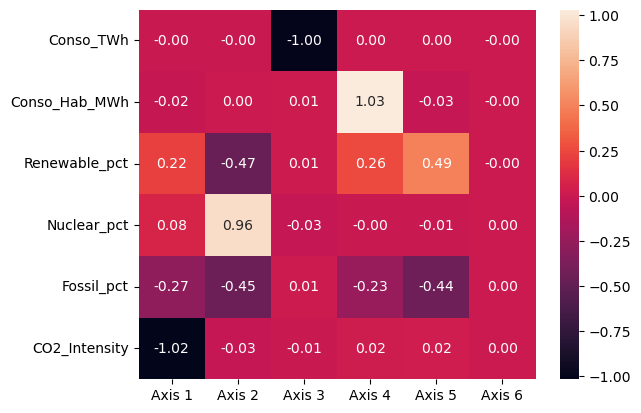

In [77]:
sns.heatmap(L_oblimin,annot=True,fmt='.2f', xticklabels=[f"Axis {k}" for k in range(1,7)],yticklabels=data.columns)

Ici, Quartimin propose une autre manière de voir le jeu de donnée. Il propose de classer selon le premier axe l'intensité de CO2, sur le second axe, ceux qui utilisent le nucléaire face à ceux qui utilisent les énergies renouvelables et les énergies fossiles, le troisième axe va discriminer les pays consommant énormément, et ansi de suite. 

Comme la somme des cos2 par colonne retranscrit le % d'inertie expliqué pour chaque axe, vous remarquerez qu'en réalité une rotation, qu'elle soit oblique ou encore orthogonale, elle redistribue le % de variance expliqué par chaque axe. 

N'essayez pas non plus de plot vos données via matplotlib puisque le repère n'est plus orthogonal et que matplotlib affiche des points dans un repère purement cartésien. UNE PREMIÈRE TECHNIQUE de visualisation peut consister à placer vos points de l'ACP standard dans le repère orthonormé, puis d'afficher les points en conséquence. Cela requiert néanmoins une gymnastique mentale assez forte pour pouvoir lire des coordonnées de points en les projetant de manière parallèle au vecteur opposé. Mais vous pouvez essayer. 


Sinon, il faut forcer matplotlib à transformer le graphique en conséquence, ce qui est ma foi assez complexe.

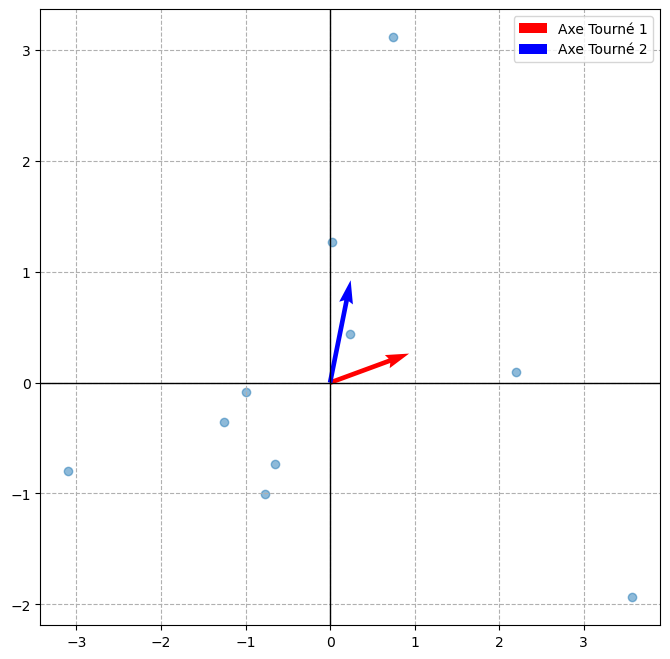

In [78]:
import matplotlib.pyplot as plt
import numpy as np

# Supposons que T est ta matrice de passage (2x2 pour 2 axes)
# Les colonnes de T indiquent la direction des nouveaux axes dans l'ancien repère
axis1_dir = T_oblimin[:, 0]
axis2_dir = T_oblimin[:, 1]

plt.figure(figsize=(8, 8))

# 1. Tracer les points (scores originaux de l'ACP)
plt.scatter(apc.row_coord_[:, 0], apc.row_coord_[:, 1], alpha=0.5)

# 2. Tracer les nouveaux axes obliques partant de l'origine
plt.quiver(0, 0, axis1_dir[0], axis1_dir[1], angles='xy', scale_units='xy', scale=1, color='red', label='Axe Tourné 1')
plt.quiver(0, 0, axis2_dir[0], axis2_dir[1], angles='xy', scale_units='xy', scale=1, color='blue', label='Axe Tourné 2')

plt.axhline(0, color='black', lw=1)
plt.axvline(0, color='black', lw=1)
plt.legend()
plt.grid(True, linestyle='--')
plt.show()

Comme vous le voyez, l'Axe 1 a moins de contribution que l'Axe deux par exemple. N'oubliez jamais que les représentations graphiques dans ce genre de cas sont assez inutiles par rapport à la difficulté de les coder. Interprétez plutôt les résultats numériques. 

ChatGPT m'a fourni cette fonction réutilisable rien que pour vous (et c'est pour ce genre de choses que les gens devraient l'utiliser !):

In [79]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.transforms import Affine2D
from mpl_toolkits.axisartist.floating_axes import GridHelperCurveLinear, FloatingSubplot

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.transforms import Affine2D
from mpl_toolkits.axisartist.floating_axes import GridHelperCurveLinear, FloatingSubplot

def setup_oblique_axes(angle_x_deg=0, angle_y_deg=90, x_lim=(-4, 4), y_lim=(-4, 4), fig=None, pos=111, title=""):
    """
    Crée un système d'axes obliques.
    pos  : position (ex: 121 pour 1 ligne, 2 colonnes, index 1)
    fig  : objet Figure de matplotlib
    angle_x_deg : angle de l'axe des abscisses (0 = horizontal)

    angle_y_deg : angle de l'axe des ordonnées (90 = vertical)
    """
    # 1. Calcul des angles
    rad_x, rad_y = np.radians(angle_x_deg), np.radians(angle_y_deg)
    
    # 2. Construction de la matrice de transformation
    matrix = [np.cos(rad_x), np.sin(rad_x), np.cos(rad_y), np.sin(rad_y), 0, 0]
    tr = Affine2D().from_values(*matrix)
    
    # 3. Préparation du helper de grille
    grid_helper = GridHelperCurveLinear(tr, extremes=(x_lim[0], x_lim[1], y_lim[0], y_lim[1]))
    
    # 4. Gestion de la figure (si None, on crée une figure par défaut)
    if fig is None:
        fig = plt.figure(figsize=(8, 8))
    
    # 5. Création du subplot à la position demandée
    ax = FloatingSubplot(fig, pos, grid_helper=grid_helper)
    fig.add_subplot(ax)
    
    # Expose la transformation pour les données
    ax.oblique_tr = tr + ax.transData
    
    ax.grid(True, linestyle='--', alpha=0.6)
    if title:
        ax.set_title(title, pad=20)
    
    return ax

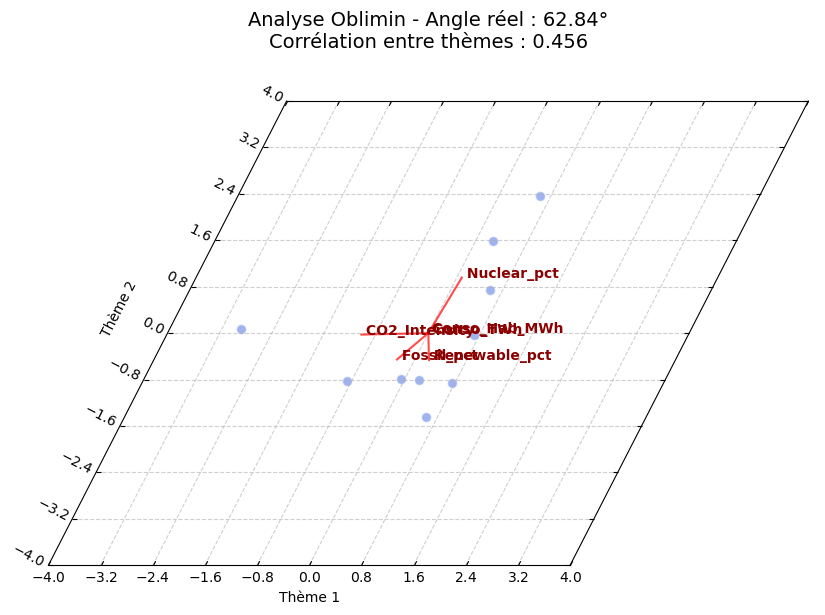

In [80]:
# --- 1. CALCUL DE L'ANGLE RÉEL ---
# On extrait les directions des deux colonnes de la matrice de rotation T
v1 = T_oblimin[:, 0]
v2 = T_oblimin[:, 1]

# Cosinus de l'angle (Produit scalaire / produit des normes)
cos_theta = np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2))
# Sécurité pour éviter les erreurs de flottants au-delà de 1.0
angle_rad = np.arccos(np.clip(cos_theta, -1.0, 1.0))
angle_themes = np.degrees(angle_rad)

# --- 2. TRACÉ DU GRAPHIQUE ---
fig = plt.figure(figsize=(10, 8))

# On garde l'axe X horizontal (0°) et on incline l'axe Y selon l'angle calculé
ax = setup_oblique_axes(angle_x_deg=0, angle_y_deg=angle_themes, fig=fig)

# Affichage des scores
ax.scatter(scores_oblimin[:, 0], scores_oblimin[:, 1], 
           transform=ax.oblique_tr, alpha=0.5, c="royalblue", edgecolors="white", s=50)

# Affichage des vecteurs (Loadings)
for i, var_name in enumerate(data.columns):
    dx, dy = L_oblimin[i, 0], L_oblimin[i, 1]
    ax.plot([0, dx], [0, dy], transform=ax.oblique_tr, color='red', lw=1.5, alpha=0.7)
    ax.text(dx, dy, f" {var_name}", transform=ax.oblique_tr, color='darkred', weight='bold')

# --- 3. MISE EN FORME ---
ax.set_title(f"Analyse Oblimin - Angle réel : {angle_themes:.2f}°\nCorrélation entre thèmes : {cos_theta:.3f}", 
             pad=35, fontsize=14)
ax.set_xlabel("Thème 1", labelpad=20)
ax.set_ylabel("Thème 2", labelpad=20)

plt.show()

Je n'ai pas l'expertise suffisante sur matplotlib pour vous assurer que la manière dont ChatGPT a fait la fonction de rotation des axes est réellement pertinente. Si vous vous y connaissez mieux que moi, n'hésitez pas à me faire savoir vos impressions à mon mail: kevinmr89400@gmail.com.

Vous pouvez toujours calculer les contributions en prenant le cos2, puis en le divisant par la somme des cos2 de la colonne (celle qui redonne l'inertie associée à l'axe, c'est-à-dire la nouvelle valeur propre.)

Notez que depuis le début, je m'embête avec le choix des gamma, de la rotation si elle est oblique ou orthogonale, etc... dans la famille orthomax et oblimin pour vous entraîner à comprendre les concepts mathématiques derrière, mais si vous voulez faire la rotation que vous souhaitez, il suffit de taper son nom:


In [81]:
L,T = rotate_factors(apc.row_coord_,"parsimax")

In [82]:
L,T = rotate_factors(apc.col_coord_,"biquartimin")


Regardons comment fonctionne plus en détail 

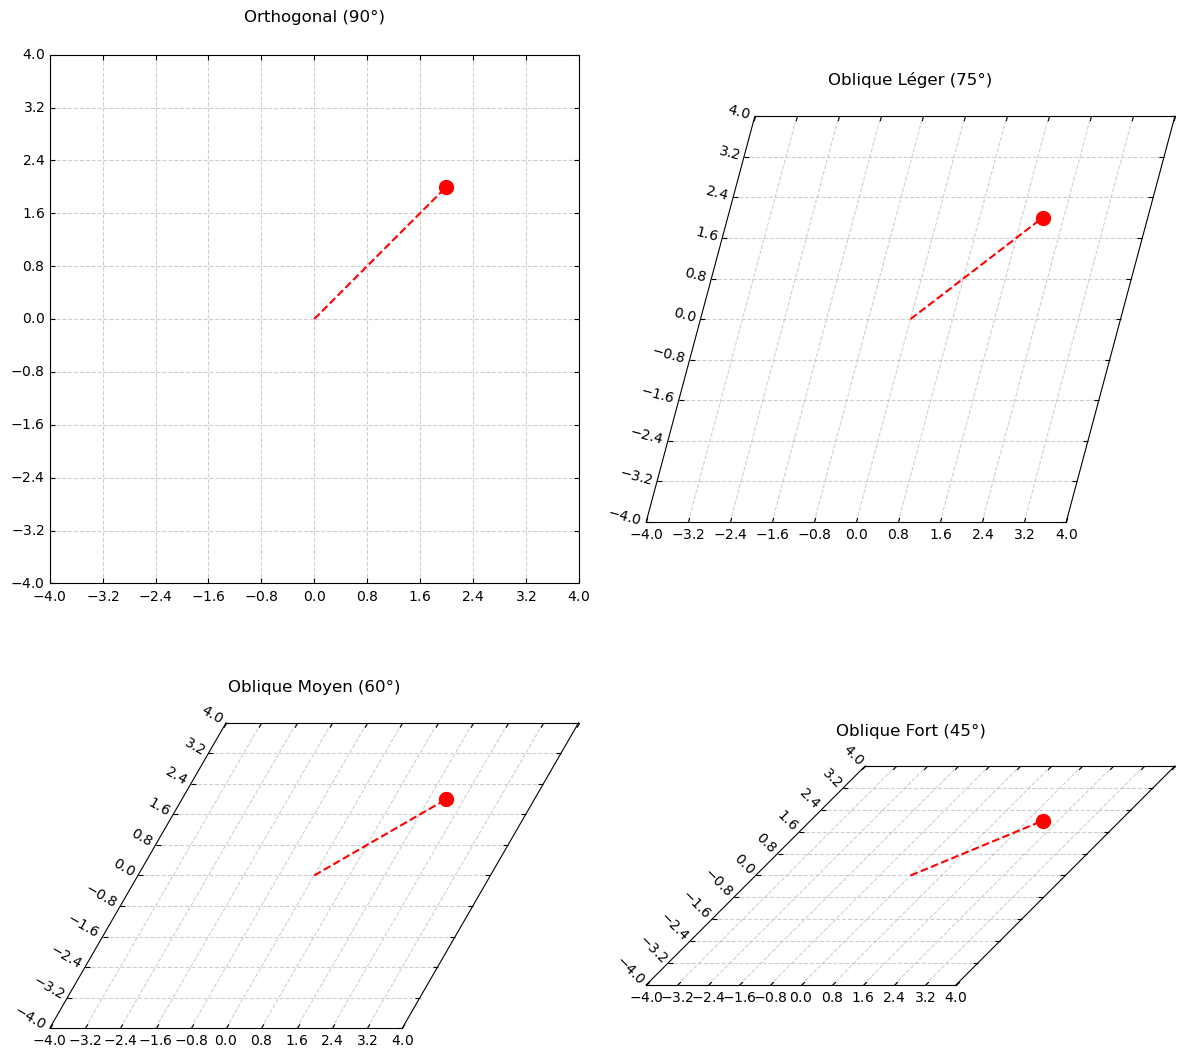

In [83]:
# 1. Créer une figure carrée pour accueillir les 4 graphiques
fig = plt.figure(figsize=(12, 12))

# 2. On définit nos 4 axes avec des angles différents pour comparer
# Position 221 : Haut Gauche
ax1 = setup_oblique_axes(0, 90, fig=fig, pos=221, title="Orthogonal (90°)")

# Position 222 : Haut Droite
ax2 = setup_oblique_axes(0, 75, fig=fig, pos=222, title="Oblique Léger (75°)")

# Position 223 : Bas Gauche
ax3 = setup_oblique_axes(0, 60, fig=fig, pos=223, title="Oblique Moyen (60°)")

# Position 224 : Bas Droite
ax4 = setup_oblique_axes(0, 45, fig=fig, pos=224, title="Oblique Fort (45°)")

# 3. Exemple : Tracer le même point (2, 2) partout pour voir la déformation
axes_list = [ax1, ax2, ax3, ax4]
for ax in axes_list:
    ax.scatter(2, 2, transform=ax.oblique_tr, color='red', s=100)
    # On peut aussi tracer un vecteur
    ax.plot([0, 2], [0, 2], transform=ax.oblique_tr, color='red', linestyle='--')

# 4. Ajustement final pour éviter que les titres touchent les axes du haut
plt.tight_layout()
plt.show()

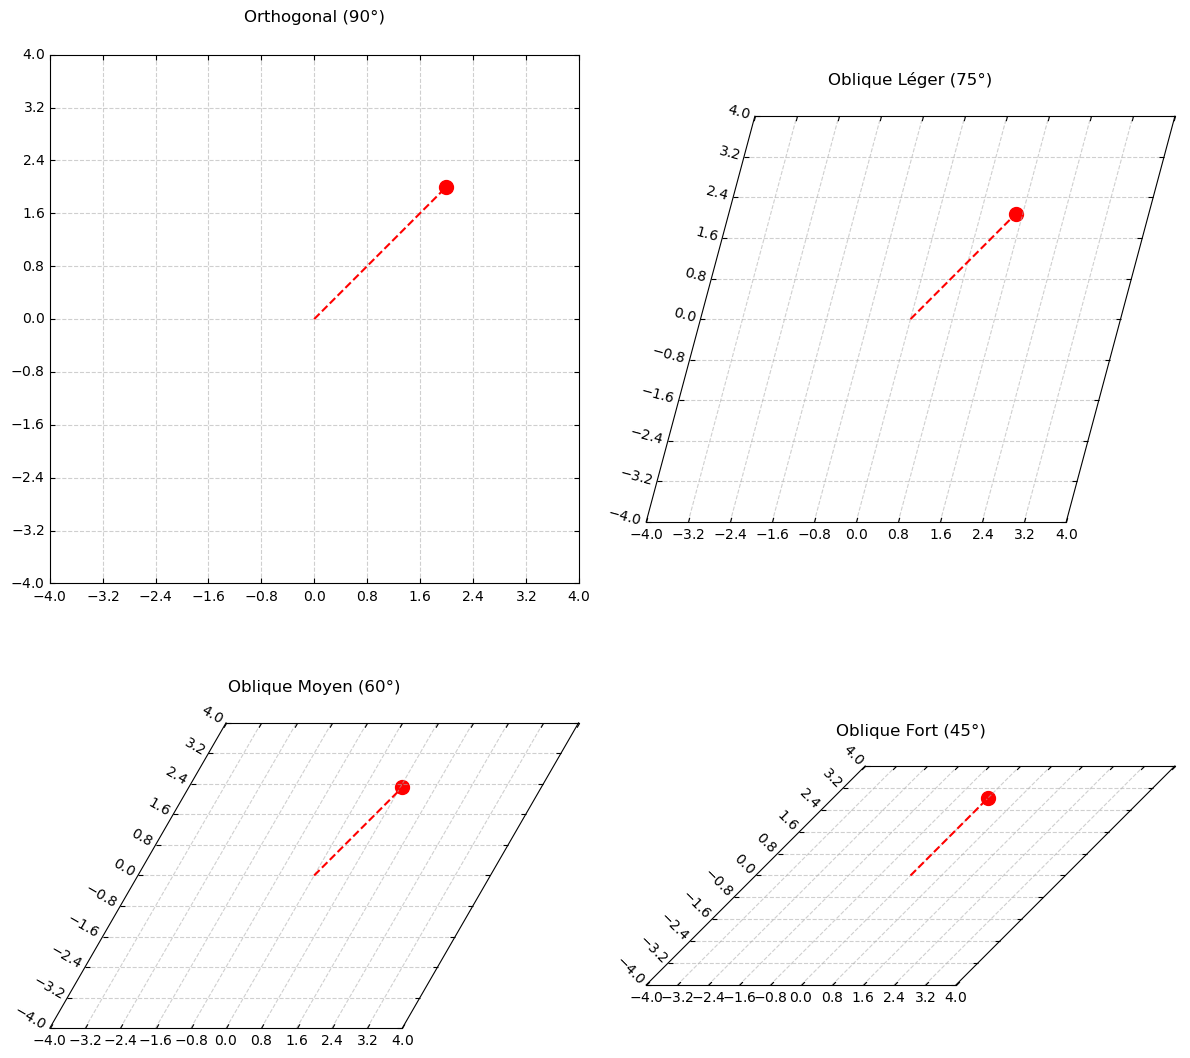

In [84]:
# 1. Créer une figure carrée pour accueillir les 4 graphiques
fig = plt.figure(figsize=(12, 12))

# 2. On définit nos 4 axes avec des angles différents pour comparer
# Position 221 : Haut Gauche
ax1 = setup_oblique_axes(0, 90, fig=fig, pos=221, title="Orthogonal (90°)")

# Position 222 : Haut Droite
ax2 = setup_oblique_axes(0, 75, fig=fig, pos=222, title="Oblique Léger (75°)")

# Position 223 : Bas Gauche
ax3 = setup_oblique_axes(0, 60, fig=fig, pos=223, title="Oblique Moyen (60°)")

# Position 224 : Bas Droite
ax4 = setup_oblique_axes(0, 45, fig=fig, pos=224, title="Oblique Fort (45°)")

# 3. Exemple : Tracer le même point (2, 2) partout pour voir la déformation
axes_list = [ax1, ax2, ax3, ax4]
for ax in axes_list:
    ax.scatter(2, 2, color='red', s=100)
    # On peut aussi tracer un vecteur
    ax.plot([0, 2], [0, 2], color='red', linestyle='--')

# 4. Ajustement final pour éviter que les titres touchent les axes du haut
plt.tight_layout()
plt.show()

Vous voyez qu'il faut faire attention à l'argument tr_oblique. 

Il existe encore d'autres types de rotation, mais elles ne sont pas disponibles, à ma connaissance, dans le package statsmodel. Pour ne pas vous embrouiller, je préfère m'arrêter là !

Si vous voulez en apprendre plus, regardez la famille de Crawford-Ferguson, ou encore la rotation Parsimax. 